In [1]:

# INSTALL REQUIRED LIBRARIES

!pip install rdkit scikit-learn pandas numpy matplotlib seaborn -q

print("All required libraries installed successfully!")


All required libraries installed successfully!


In [2]:

# IMPORT LIBRARIES

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from rdkit import Chem
from rdkit.Chem import AllChem, Draw, Descriptors

# Set random seed for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch Version:", torch.__version__)
print("Device:", device)
print("RDKit imported successfully!")


PyTorch Version: 2.14.1+cpu
Device: cpu
RDKit imported successfully!


In [3]:

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\nSYSTEM READY!")


GPU Available: False
NumPy: 2.4.6
Pandas: 2.2.3

SYSTEM READY!


In [4]:

# DOWNLOAD DAVIS DATASET

!wget -q https://baidu-nlp.bj.bcebos.com/PaddleHelix/datasets/dti_datasets/davis_v1.tgz -O davis.tgz

!tar -xzf davis.tgz

print("Davis dataset downloaded and extracted!")

print("\nDataset files:")
!ls -R davis | head -30


Davis dataset downloaded and extracted!

Dataset files:
davis:
folds
ligands_can.txt
processed
proteins.txt
Y

davis/folds:
test_fold_setting1.txt
train_fold_setting1.txt

davis/processed:
test
train

davis/processed/test:
davis_test.npz

davis/processed/train:
davis_train.npz


In [5]:

import os

dataset_path = "davis"

print("Dataset contents:\n")

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        print(os.path.join(root, file))


Dataset contents:

davis/Y
davis/ligands_can.txt
davis/proteins.txt
davis/folds/test_fold_setting1.txt
davis/folds/train_fold_setting1.txt
davis/processed/test/davis_test.npz
davis/processed/train/davis_train.npz


In [7]:

import os

print("Files available in Colab:\n")

print(os.listdir('/content'))


Files available in Colab:

['.config', 'davis.tgz', 'davis', 'kiba.csv', 'sample_data']


In [8]:

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving kiba.csv to kiba (1).csv
Uploaded files: ['kiba (1).csv']


In [9]:

import pandas as pd

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (118254, 5)


,ID,Molecule ID,Molecule Sequence,Protein Sequence,Binding Affinity
0,CHEMBL1087421,O00141,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.1
1,CHEMBL1087421,O14920,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.1
2,CHEMBL1087421,O15111,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...,11.1
3,CHEMBL1087421,P00533,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...,11.1
4,CHEMBL1087421,P04626,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MELAALCRWGLLLALLPPGAASTQVCTGTDMKLRLPASPETHLDML...,11.1



Column names:
['ID', 'Molecule ID', 'Molecule Sequence', 'Protein Sequence', 'Binding Affinity']

Missing values:
ID                   0
Molecule ID          0
Molecule Sequence    0
Protein Sequence     0
Binding Affinity     0
dtype: int64


In [10]:

# ============================================================
# STAGE 2: DATASET EXPLORATION
# ============================================================

# Import the required library
import pandas as pd
import numpy as np

# Display the total number of rows and columns
print("Dataset Dimensions:")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display all column names
print("\nDataset Column Names:")
print(df.columns.tolist())

# Display the first five observations
print("\nFirst Five Records:")
display(df.head())

# Display the last five observations
print("\nLast Five Records:")
display(df.tail())

# Display the data types and non-null counts
print("\nDataset Information:")
df.info()


Dataset Dimensions:
Number of Rows: 118254
Number of Columns: 5

Dataset Column Names:
['ID', 'Molecule ID', 'Molecule Sequence', 'Protein Sequence', 'Binding Affinity']

First Five Records:


,ID,Molecule ID,Molecule Sequence,Protein Sequence,Binding Affinity
0,CHEMBL1087421,O00141,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.1
1,CHEMBL1087421,O14920,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.1
2,CHEMBL1087421,O15111,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...,11.1
3,CHEMBL1087421,P00533,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...,11.1
4,CHEMBL1087421,P04626,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MELAALCRWGLLLALLPPGAASTQVCTGTDMKLRLPASPETHLDML...,11.1



Last Five Records:


,ID,Molecule ID,Molecule Sequence,Protein Sequence,Binding Affinity
118249,CHEMBL230654,Q13554,CCCC1=C(NC=N1)CNC2=CC(=C3C(=C2)C(=C(C=N3)C#N)N...,MATTVTCTRFTDEYQLYEDIGKGAFSVVRRCVKLCTGHEYAAKIIN...,10.49794
118250,CHEMBL230654,Q13555,CCCC1=C(NC=N1)CNC2=CC(=C3C(=C2)C(=C(C=N3)C#N)N...,MATTATCTRFTDDYQLFEELGKGAFSVVRRCVKKTSTQEYAAKIIN...,10.49794
118251,CHEMBL230654,Q13557,CCCC1=C(NC=N1)CNC2=CC(=C3C(=C2)C(=C(C=N3)C#N)N...,MASTTTCTRFTDEYQLFEELGKGAFSVVRRCMKIPTGQEYAAKIIN...,10.49794
118252,CHEMBL230654,Q16539,CCCC1=C(NC=N1)CNC2=CC(=C3C(=C2)C(=C(C=N3)C#N)N...,MSQERPTFYRQELNKTIWEVPERYQNLSPVGSGAYGSVCAAFDTKT...,10.49794
118253,CHEMBL230654,Q9UQM7,CCCC1=C(NC=N1)CNC2=CC(=C3C(=C2)C(=C(C=N3)C#N)N...,MATITCTRFTEEYQLFEELGKGAFSVVRRCVKVLAGQEYAAKIINT...,10.49794



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118254 entries, 0 to 118253
Data columns (total 5 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ID                 118254 non-null  object 
 1   Molecule ID        118254 non-null  object 
 2   Molecule Sequence  118254 non-null  object 
 3   Protein Sequence   118254 non-null  object 
 4   Binding Affinity   118254 non-null  float64
dtypes: float64(1), object(4)
memory usage: 4.5+ MB


In [11]:

# ============================================================
# CHECK MISSING VALUES AND DUPLICATE RECORDS
# ============================================================

# Count missing values in each column
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Calculate the percentage of missing values
print("\nMissing Value Percentage:")
print((df.isnull().mean() * 100).round(2))

# Count duplicate records
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

# Display statistical information for numerical columns
print("\nStatistical Summary:")
display(df.describe(include="all").T)


Missing Values in Each Column:
ID                   0
Molecule ID          0
Molecule Sequence    0
Protein Sequence     0
Binding Affinity     0
dtype: int64

Missing Value Percentage:
ID                   0.0
Molecule ID          0.0
Molecule Sequence    0.0
Protein Sequence     0.0
Binding Affinity     0.0
dtype: float64

Number of Duplicate Rows:
0

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,118254,2111,CHEMBL1990885,166,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Molecule ID,118254,229,P35968,1452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Molecule Sequence,118254,2068,CN1CCN(CC1)C2=CC=C(C=C2)C(=O)NC3=NNC4=C3CN(C4)...,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Protein Sequence,118254,229,MQSKVLLAVALWLCVETRAASVGLPSVSLDLPRLSIQKDILTIKAN...,1452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Binding Affinity,118254.0,NaN,NaN,NaN,11.719935,0.836947,0.0,11.2,11.5,11.923909,17.200179


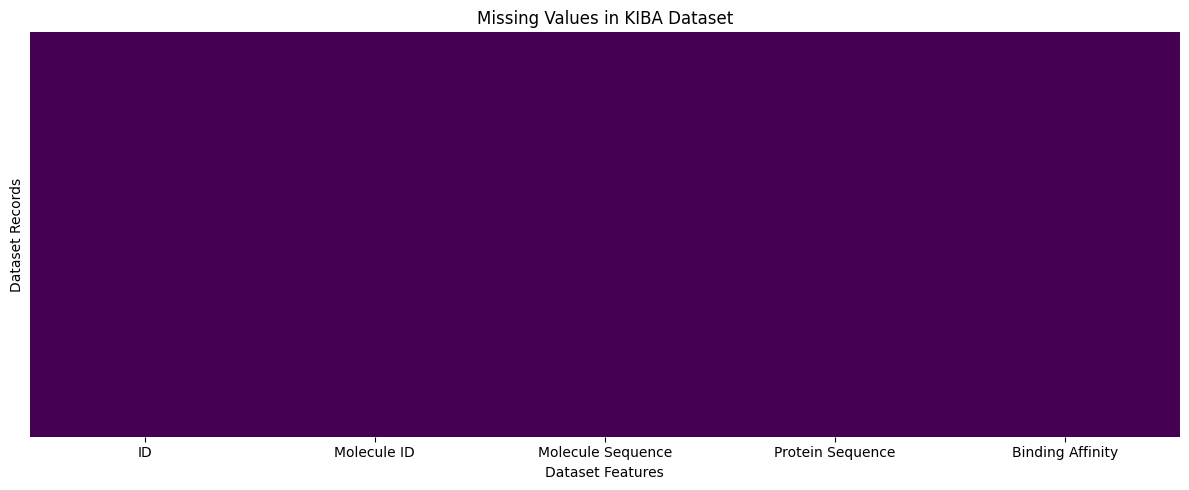

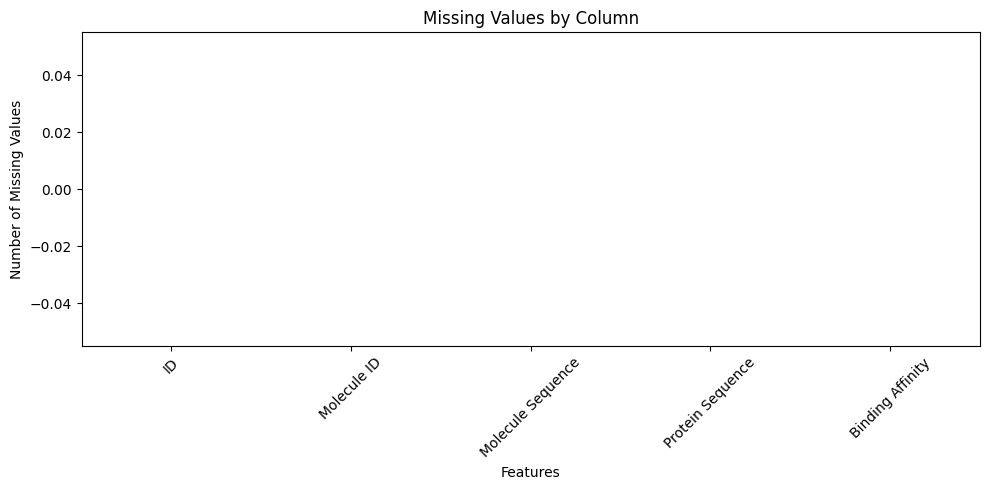

In [12]:

# ============================================================
# VISUALIZATION OF DATASET QUALITY
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Plot missing values for each column
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in KIBA Dataset")
plt.xlabel("Dataset Features")
plt.ylabel("Dataset Records")
plt.tight_layout()
plt.show()

# Plot the number of missing values per column
plt.figure(figsize=(10, 5))

df.isnull().sum().plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:

# ============================================================
# STAGE 3: DETAILED DATASET ANALYSIS
# CELL 9: UNIQUE DRUGS AND PROTEINS
# ============================================================

# Count the number of unique drug molecules
unique_drugs = df["Molecule Sequence"].nunique()

# Count the number of unique protein sequences
unique_proteins = df["Protein Sequence"].nunique()

# Count the number of unique drug-protein combinations
unique_pairs = df[
    ["Molecule Sequence", "Protein Sequence"]
].drop_duplicates().shape[0]

# Display the results
print("DATASET DIVERSITY ANALYSIS")
print("--------------------------------")
print("Total observations:", len(df))
print("Unique drug molecules:", unique_drugs)
print("Unique protein sequences:", unique_proteins)
print("Unique drug-protein pairs:", unique_pairs)

# Check repeated drug-protein combinations
print("\nRepeated drug-protein combinations:",
      len(df) - unique_pairs)


DATASET DIVERSITY ANALYSIS
--------------------------------
Total observations: 118254
Unique drug molecules: 2068
Unique protein sequences: 229
Unique drug-protein pairs: 117657

Repeated drug-protein combinations: 597


In [14]:

# ============================================================
# CELL 10: BINDING AFFINITY STATISTICS
# ============================================================

# Extract the binding affinity column
affinity = df["Binding Affinity"]

# Calculate important statistical measures
print("BINDING AFFINITY STATISTICS")
print("--------------------------------")

print("Mean:", affinity.mean())
print("Median:", affinity.median())
print("Minimum:", affinity.min())
print("Maximum:", affinity.max())
print("Standard Deviation:", affinity.std())

# Display the complete statistical summary
display(affinity.describe())


BINDING AFFINITY STATISTICS
--------------------------------
Mean: 11.719934769945
Median: 11.500000437
Minimum: 0.0
Maximum: 17.200179498
Standard Deviation: 0.8369466298268775


,Binding Affinity
count,118254.000000
mean,11.719935
std,0.836947
min,0.000000
25%,11.200000
50%,11.500000
75%,11.923909
max,17.200179


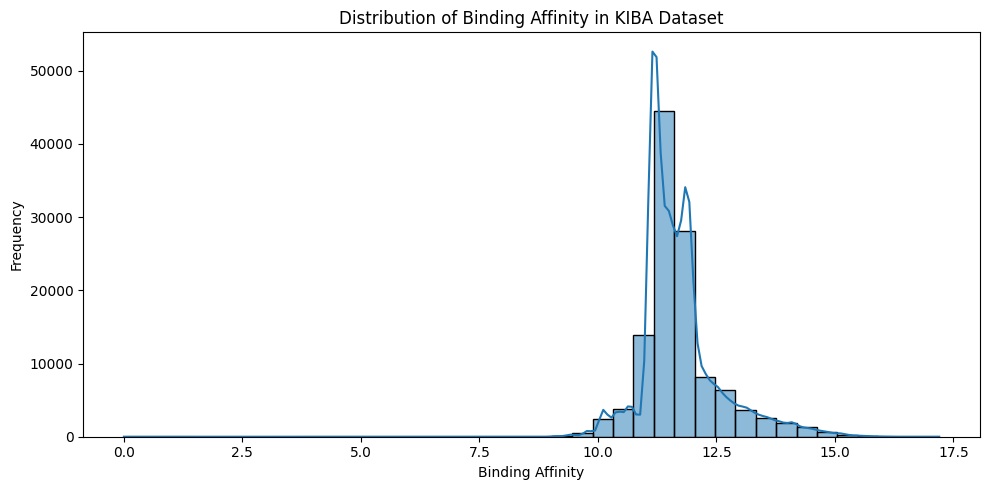

In [15]:

# ============================================================
# CELL 11: BINDING AFFINITY DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

# Plot the distribution of binding affinity values
sns.histplot(
    df["Binding Affinity"],
    bins=40,
    kde=True
)

# Add graph labels and title
plt.title("Distribution of Binding Affinity in KIBA Dataset")
plt.xlabel("Binding Affinity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


In [16]:

# ============================================================
# CELL 12: DRUG MOLECULE VALIDATION USING RDKIT
# ============================================================

from rdkit import Chem

# Get unique drug molecular structures
unique_smiles = df["Molecule Sequence"].dropna().unique()

# Initialize counters
valid_molecules = 0
invalid_molecules = 0

# Validate each molecular structure
for smiles in unique_smiles:

    # Convert SMILES string into an RDKit molecule
    molecule = Chem.MolFromSmiles(smiles)

    # Check whether the molecule was successfully created
    if molecule is not None:
        valid_molecules += 1
    else:
        invalid_molecules += 1

# Display validation results
print("MOLECULAR STRUCTURE VALIDATION")
print("--------------------------------")
print("Total unique SMILES:", len(unique_smiles))
print("Valid molecules:", valid_molecules)
print("Invalid molecules:", invalid_molecules)

print("\nMolecular validation completed!")


MOLECULAR STRUCTURE VALIDATION
--------------------------------
Total unique SMILES: 2068
Valid molecules: 2068
Invalid molecules: 0

Molecular validation completed!


PROTEIN SEQUENCE ANALYSIS
--------------------------------
Total unique protein sequences: 229
Average sequence length: 728.9563318777292
Minimum sequence length: 215
Maximum sequence length: 4128


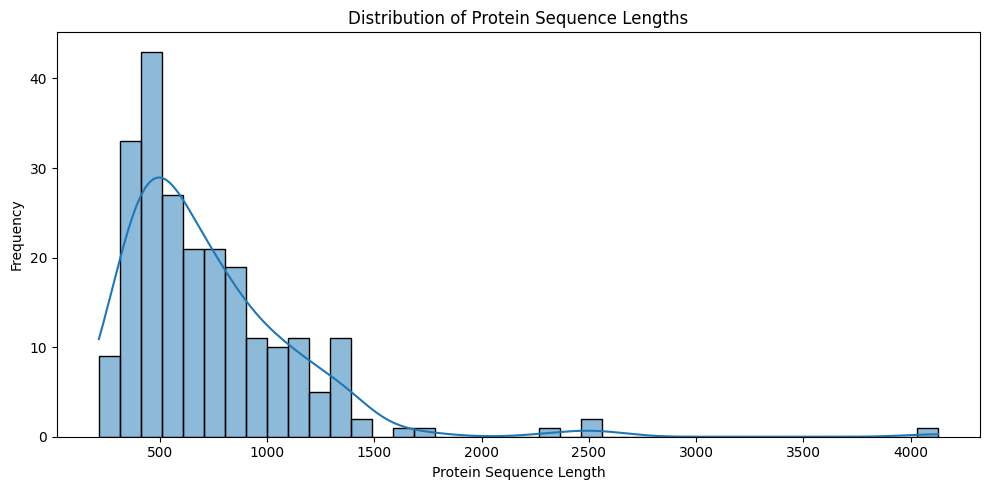

In [17]:

# ============================================================
# CELL 13: PROTEIN SEQUENCE ANALYSIS
# ============================================================

# Extract unique protein sequences
unique_sequences = df["Protein Sequence"].dropna().unique()

# Calculate the length of each protein sequence
protein_lengths = [
    len(sequence) for sequence in unique_sequences
]

# Display protein statistics
print("PROTEIN SEQUENCE ANALYSIS")
print("--------------------------------")
print("Total unique protein sequences:",
      len(unique_sequences))

print("Average sequence length:",
      np.mean(protein_lengths))

print("Minimum sequence length:",
      np.min(protein_lengths))

print("Maximum sequence length:",
      np.max(protein_lengths))

# Visualize protein sequence lengths
plt.figure(figsize=(10, 5))

sns.histplot(protein_lengths, bins=40, kde=True)

plt.title("Distribution of Protein Sequence Lengths")
plt.xlabel("Protein Sequence Length")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


In [18]:

# ============================================================
# STAGE 4: DATA QUALITY CHECKS
# CELL 14: DUPLICATE INTERACTION ANALYSIS
# ============================================================

# Group records using their actual drug and protein sequences
pair_analysis = (
    df.groupby(["Molecule Sequence", "Protein Sequence"])
      ["Binding Affinity"]
      .agg(["count", "nunique", "min", "max", "mean"])
      .reset_index()
)

# Select drug-protein pairs occurring more than once
duplicate_pairs = pair_analysis[
    pair_analysis["count"] > 1
]

# Identify pairs having different affinity values
conflicting_pairs = pair_analysis[
    pair_analysis["nunique"] > 1
]

# Display duplicate analysis
print("DUPLICATE INTERACTION ANALYSIS")
print("--------------------------------")

print("Repeated drug-protein pairs:",
      len(duplicate_pairs))

print("Pairs with conflicting affinity values:",
      len(conflicting_pairs))

print("\nDuplicate pair details:")
display(duplicate_pairs.head(10))

print("\nConflicting pair details:")
display(conflicting_pairs.head(10))


DUPLICATE INTERACTION ANALYSIS
--------------------------------
Repeated drug-protein pairs: 473
Pairs with conflicting affinity values: 288

Duplicate pair details:


,Molecule Sequence,Protein Sequence,count,nunique,min,max,mean
12390,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MADPAAGPPPSEGEESTVRFARKGALRQKNVHEVKNHKFTARFFKQ...,8,7,9.79897,10.869551,10.343554
12391,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MADVFPGNDSTASQDVANRFARKGALRQKNVHEVKDHKFIARFFKQ...,8,7,9.79897,10.869551,10.343554
12392,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MAGLGPGVGDSEGGPRPLFCRKGALRQKVVHEVKSHKFTARFFKQP...,8,7,9.79897,10.869551,10.343554
12393,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,8,7,9.79897,10.869551,10.343554
12394,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MPSRTGPKMEGSGGRVRLKAHYGGDIFITSVDAATTFEELCEEVRD...,8,7,9.79897,10.869551,10.343554
12395,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MPTQRDSSTMSHTVAGGGSGDHSHQVRVKAYYRGDIMITHFEPSIS...,8,7,9.79897,10.869551,10.343554
12396,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MSANNSPPSAQKSVLPTAIPAVLPAASPCSSPKTGLSARLSNGSFS...,8,7,9.79897,10.869551,10.343554
12397,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MSAPPVLRPPSPLLPVAAAAAAAAAALVPGSGPGPAPFLAPVAAPV...,8,7,9.79897,10.869551,10.343554
12398,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MSPFLRIGLSNFDCGSCQSCQGEAVNPYCAVLVKEYVESENGQMYI...,8,7,9.79897,10.869551,10.343554
12399,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MSSGTMKFNGYLRVRIGEAVGLQPTRWSLRHSLFKKGHQLLDPYLT...,8,7,9.79897,10.869551,10.343554



Conflicting pair details:


,Molecule Sequence,Protein Sequence,count,nunique,min,max,mean
12390,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MADPAAGPPPSEGEESTVRFARKGALRQKNVHEVKNHKFTARFFKQ...,8,7,9.79897,10.869551,10.343554
12391,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MADVFPGNDSTASQDVANRFARKGALRQKNVHEVKDHKFIARFFKQ...,8,7,9.79897,10.869551,10.343554
12392,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MAGLGPGVGDSEGGPRPLFCRKGALRQKVVHEVKSHKFTARFFKQP...,8,7,9.79897,10.869551,10.343554
12393,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,8,7,9.79897,10.869551,10.343554
12394,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MPSRTGPKMEGSGGRVRLKAHYGGDIFITSVDAATTFEELCEEVRD...,8,7,9.79897,10.869551,10.343554
12395,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MPTQRDSSTMSHTVAGGGSGDHSHQVRVKAYYRGDIMITHFEPSIS...,8,7,9.79897,10.869551,10.343554
12396,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MSANNSPPSAQKSVLPTAIPAVLPAASPCSSPKTGLSARLSNGSFS...,8,7,9.79897,10.869551,10.343554
12397,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MSAPPVLRPPSPLLPVAAAAAAAAAALVPGSGPGPAPFLAPVAAPV...,8,7,9.79897,10.869551,10.343554
12398,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MSPFLRIGLSNFDCGSCQSCQGEAVNPYCAVLVKEYVESENGQMYI...,8,7,9.79897,10.869551,10.343554
12399,C1=CC2=C(C=C1O)NC3=C4C(=C5C(=C23)C(=O)N(C5=O)N...,MSSGTMKFNGYLRVRIGEAVGLQPTRWSLRHSLFKKGHQLLDPYLT...,8,7,9.79897,10.869551,10.343554


In [19]:

# ============================================================
# CELL 15: BINDING AFFINITY ZERO-VALUE ANALYSIS
# ============================================================

# Count observations with zero affinity score
zero_count = (df["Binding Affinity"] == 0).sum()

# Calculate percentage of zero values
zero_percentage = (zero_count / len(df)) * 100

# Count observations with positive affinity scores
positive_count = (df["Binding Affinity"] > 0).sum()

# Display results
print("ZERO-VALUE ANALYSIS")
print("--------------------------------")

print("Zero affinity observations:", zero_count)

print("Zero value percentage:",
      round(zero_percentage, 4), "%")

print("Positive affinity observations:",
      positive_count)


ZERO-VALUE ANALYSIS
--------------------------------
Zero affinity observations: 1
Zero value percentage: 0.0008 %
Positive affinity observations: 118253


In [20]:

# ============================================================
# CELL 16: IDENTIFIER CONSISTENCY CHECK
# ============================================================

# Check how many unique drug structures correspond to each ID
drug_id_mapping = (
    df.groupby("ID")["Molecule Sequence"].nunique()
)

# Check how many unique protein sequences correspond
# to each Molecule ID
protein_id_mapping = (
    df.groupby("Molecule ID")["Protein Sequence"].nunique()
)

print("IDENTIFIER CONSISTENCY")
print("--------------------------------")

print("Drug IDs with multiple structures:",
      (drug_id_mapping > 1).sum())

print("Protein IDs with multiple sequences:",
      (protein_id_mapping > 1).sum())

print("\nUnique drug IDs:", df["ID"].nunique())
print("Unique protein IDs:", df["Molecule ID"].nunique())


IDENTIFIER CONSISTENCY
--------------------------------
Drug IDs with multiple structures: 0
Protein IDs with multiple sequences: 0

Unique drug IDs: 2111
Unique protein IDs: 229


In [21]:

# ============================================================
# STAGE 5: DATA PREPROCESSING
# CELL 17: HANDLE DUPLICATE INTERACTIONS
# ============================================================

# Preserve the original dataset for reference
df_original = df.copy()

# Group records by their drug and protein sequences
# Calculate mean affinity for repeated interactions
# Retain the number of measurements for analysis

processed_df = (
    df.groupby(
        ["Molecule Sequence", "Protein Sequence"],
        as_index=False
    )
    .agg({
        "ID": "first",
        "Molecule ID": "first",
        "Binding Affinity": "mean"
    })
)

# Count the number of unique drug-protein combinations
print("DATASET AFTER DUPLICATE HANDLING")
print("--------------------------------")

print("Original observations:", len(df_original))
print("Processed observations:", len(processed_df))

print("Remaining duplicate pairs:",
      processed_df.duplicated(
          subset=["Molecule Sequence", "Protein Sequence"]
      ).sum())

# Check whether any affinity values are missing
print("Missing affinity values:",
      processed_df["Binding Affinity"].isnull().sum())

# Display the processed dataset
display(processed_df.head())


DATASET AFTER DUPLICATE HANDLING
--------------------------------
Original observations: 118254
Processed observations: 117657
Remaining duplicate pairs: 0
Missing affinity values: 0


,Molecule Sequence,Protein Sequence,ID,Molecule ID,Binding Affinity
0,C#CC1=CN(C2=C1C(=NC=N2)N)C3CCCC3,MAAAYLDPNLNHTPNSSTKTHLGTGMERSPGAMERVLKVFHYFESN...,CHEMBL1993877,Q05397,11.600000
1,C#CC1=CN(C2=C1C(=NC=N2)N)C3CCCC3,MAAVILESIFLKRSQQKKKTSPLNFKKRLFLLTVHKLSYYEYDFER...,CHEMBL1993877,Q06187,11.300000
2,C#CC1=CN(C2=C1C(=NC=N2)N)C3CCCC3,MAKATSGAAGLRLLLLLLLPLLGKVALGLYFSRDAYWEKLYVDQAA...,CHEMBL1993877,P07949,13.000009
3,C#CC1=CN(C2=C1C(=NC=N2)N)C3CCCC3,MAKQYDSVECPFCDEVSKYEKLAKIGQGTFGEVFKARHRKTGQKVA...,CHEMBL1993877,P50750,11.900001
4,C#CC1=CN(C2=C1C(=NC=N2)N)C3CCCC3,MALDVKSRAKRYEKLDFLGEGQFATVYKARDKNTNQIVAIKKIKLG...,CHEMBL1993877,P50613,11.900001


In [22]:

# ============================================================
# CELL 18: VALIDATE PROCESSED AFFINITY VALUES
# ============================================================

# Display updated affinity statistics
print("PROCESSED BINDING AFFINITY STATISTICS")
print("--------------------------------")

print(processed_df["Binding Affinity"].describe())

# Count zero values after aggregation
print("\nZero affinity values:",
      (processed_df["Binding Affinity"] == 0).sum())

# Verify that all affinity values are finite
print("All affinity values are finite:",
      np.isfinite(processed_df["Binding Affinity"]).all())


PROCESSED BINDING AFFINITY STATISTICS
--------------------------------
count    117657.000000
mean         11.721431
std           0.834363
min           0.000000
25%          11.200000
50%          11.527128
75%          11.923909
max          17.200179
Name: Binding Affinity, dtype: float64

Zero affinity values: 1
All affinity values are finite: True


In [23]:

# ============================================================
# CELL 19: TRAIN-TEST DATA SPLITTING
# ============================================================

from sklearn.model_selection import train_test_split

# Create row indices for the processed dataset
indices = np.arange(len(processed_df))

# Split the observations into training and testing sets
train_indices, test_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

# Create training and testing datasets
train_df = processed_df.iloc[train_indices].copy()
test_df = processed_df.iloc[test_indices].copy()

# Reset dataset indices
train_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

# Display splitting results
print("TRAIN-TEST SPLIT RESULTS")
print("--------------------------------")

print("Total observations:", len(processed_df))
print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("Training percentage:",
      round(len(train_df) / len(processed_df) * 100, 2), "%")

print("Testing percentage:",
      round(len(test_df) / len(processed_df) * 100, 2), "%")


TRAIN-TEST SPLIT RESULTS
--------------------------------
Total observations: 117657
Training observations: 94125
Testing observations: 23532
Training percentage: 80.0 %
Testing percentage: 20.0 %


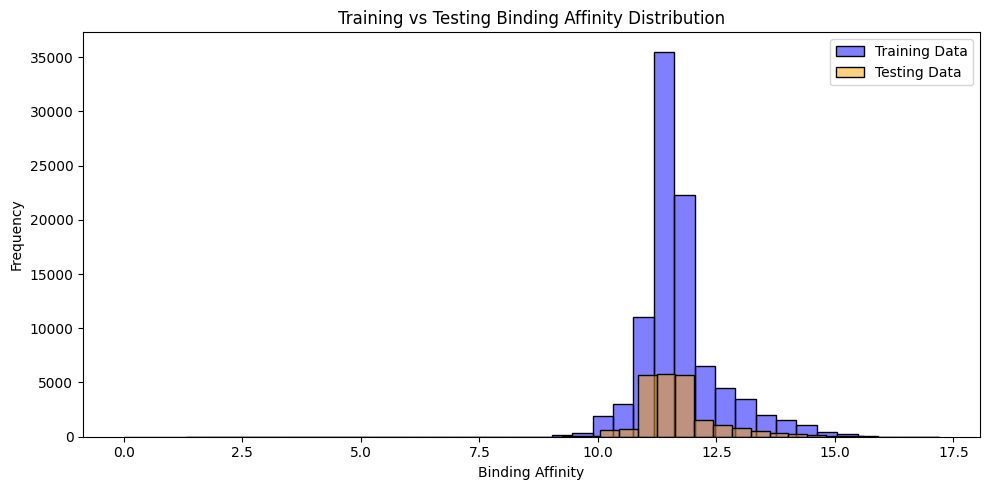

In [24]:

# ============================================================
# CELL 20: VISUALIZE TRAINING AND TESTING DISTRIBUTIONS
# ============================================================

plt.figure(figsize=(10, 5))

# Plot training affinity distribution
sns.histplot(
    train_df["Binding Affinity"],
    bins=40,
    color="blue",
    label="Training Data",
    alpha=0.5
)

# Plot testing affinity distribution
sns.histplot(
    test_df["Binding Affinity"],
    bins=40,
    color="orange",
    label="Testing Data",
    alpha=0.5
)

# Add graph labels
plt.title("Training vs Testing Binding Affinity Distribution")
plt.xlabel("Binding Affinity")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()
plt.show()


In [25]:

# ============================================================
# STAGE 6: MOLECULAR GRAPH CONSTRUCTION
# CELL 21: INSTALL PYTORCH GEOMETRIC
# ============================================================

# Install PyTorch Geometric for graph neural networks
!pip install torch-geometric -q

# Import graph-learning components
from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader

# Verify installation
import torch_geometric

print("PyTorch Geometric installed successfully!")
print("PyTorch Geometric Version:", torch_geometric.__version__)
print("PyTorch Version:", torch.__version__)


PyTorch Geometric installed successfully!
PyTorch Geometric Version: 2.8.1
PyTorch Version: 2.14.1+cpu


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [26]:

# ============================================================
# CELL 22: MOLECULAR ATOM FEATURE EXTRACTION
# ============================================================

from rdkit import Chem
import numpy as np

def get_atom_features(atom):

    # Extract basic chemical properties of an atom
    features = [
        atom.GetAtomicNum(),
        atom.GetDegree(),
        atom.GetFormalCharge(),
        atom.GetTotalNumHs(),
        int(atom.GetIsAromatic()),
        atom.GetMass()
    ]

    return features


# Test atom feature extraction using a real drug
sample_smiles = processed_df["Molecule Sequence"].iloc[0]

sample_molecule = Chem.MolFromSmiles(sample_smiles)

# Extract features for every atom
sample_features = [
    get_atom_features(atom)
    for atom in sample_molecule.GetAtoms()
]

print("Sample Drug SMILES:")
print(sample_smiles)

print("\nNumber of atoms:", sample_molecule.GetNumAtoms())

print("\nFirst five atom feature vectors:")
print(sample_features[:5])


Sample Drug SMILES:
C#CC1=CN(C2=C1C(=NC=N2)N)C3CCCC3

Number of atoms: 17

First five atom feature vectors:
[[6, 1, 0, 1, 0, 12.011], [6, 2, 0, 0, 0, 12.011], [6, 3, 0, 0, 1, 12.011], [6, 2, 0, 1, 1, 12.011], [7, 3, 0, 0, 1, 14.007]]


In [27]:

# ============================================================
# CELL 23: 3D MOLECULAR CONFORMER GENERATION
# ============================================================

from rdkit.Chem import AllChem

def generate_3d_conformer(smiles):

    # Convert SMILES into an RDKit molecule
    molecule = Chem.MolFromSmiles(smiles)

    if molecule is None:
        return None

    # Add hydrogen atoms for 3D conformer generation
    molecule = Chem.AddHs(molecule)

    # Generate a 3D conformer using ETKDG
    parameters = AllChem.ETKDGv3()
    parameters.randomSeed = 42

    conformer_id = AllChem.EmbedMolecule(
        molecule,
        parameters
    )

    # Check whether conformer generation succeeded
    if conformer_id == -1:
        return None

    # Optimize molecular geometry using MMFF
    optimization_status = AllChem.MMFFOptimizeMolecule(
        molecule,
        maxIters=100
    )

    # Extract 3D atomic coordinates
    coordinates = molecule.GetConformer().GetPositions()

    return molecule, coordinates


# Test 3D conformer generation
result = generate_3d_conformer(sample_smiles)

if result is not None:

    molecule_3d, coordinates = result

    print("3D conformer generated successfully!")

    print("Number of atoms including hydrogens:",
          molecule_3d.GetNumAtoms())

    print("Coordinate matrix shape:",
          coordinates.shape)

    print("\nFirst five 3D coordinates:")
    print(coordinates[:5])

else:
    print("3D conformer generation failed.")


3D conformer generated successfully!
Number of atoms including hydrogens: 31
Coordinate matrix shape: (31, 3)

First five 3D coordinates:
[[ 2.32604258  3.7349207   0.43218548]
 [ 1.86185466  2.65081023  0.20728056]
 [ 1.30798113  1.36364287 -0.05823427]
 [-0.03778382  1.13230307 -0.25064074]
 [-0.20904743 -0.21071092 -0.48080822]]


In [28]:

# ============================================================
# CELL 24: CONSTRUCT GEOMETRY-AWARE MOLECULAR GRAPH
# ============================================================

def build_molecular_graph(smiles):

    # Generate the 3D molecular conformer
    result = generate_3d_conformer(smiles)

    if result is None:
        return None

    molecule, coordinates = result

    # Extract atom features
    node_features = []

    for atom in molecule.GetAtoms():
        node_features.append(get_atom_features(atom))

    # Convert atom features into a PyTorch tensor
    x = torch.tensor(
        node_features,
        dtype=torch.float
    )

    # Extract 3D coordinates
    pos = torch.tensor(
        coordinates,
        dtype=torch.float
    )

    # Initialize graph edge information
    edge_indices = []
    edge_features = []

    # Extract chemical bonds
    for bond in molecule.GetBonds():

        atom1 = bond.GetBeginAtomIdx()
        atom2 = bond.GetEndAtomIdx()

        # Encode bond types
        bond_type = bond.GetBondType()

        bond_feature = [
            float(bond_type == Chem.BondType.SINGLE),
            float(bond_type == Chem.BondType.DOUBLE),
            float(bond_type == Chem.BondType.TRIPLE),
            float(bond_type == Chem.BondType.AROMATIC)
        ]

        # Add both directions because molecular graphs are bidirectional
        edge_indices.append([atom1, atom2])
        edge_indices.append([atom2, atom1])

        edge_features.append(bond_feature)
        edge_features.append(bond_feature)

    # Convert edges into tensors
    if len(edge_indices) > 0:

        edge_index = torch.tensor(
            edge_indices,
            dtype=torch.long
        ).t().contiguous()

        edge_attr = torch.tensor(
            edge_features,
            dtype=torch.float
        )

    else:

        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, 4), dtype=torch.float)

    # Create a PyTorch Geometric graph
    graph = Data(
        x=x,
        edge_index=edge_index,
        edge_attr=edge_attr,
        pos=pos
    )

    return graph


# Build a graph for one real drug molecule
sample_graph = build_molecular_graph(sample_smiles)

if sample_graph is not None:

    print("MOLECULAR GRAPH CREATED")
    print("--------------------------------")

    print("Node feature shape:", sample_graph.x.shape)
    print("Edge index shape:", sample_graph.edge_index.shape)
    print("Bond feature shape:", sample_graph.edge_attr.shape)
    print("3D coordinate shape:", sample_graph.pos.shape)

    print("\nSample graph:")
    print(sample_graph)

else:
    print("Unable to construct molecular graph.")


MOLECULAR GRAPH CREATED
--------------------------------
Node feature shape: torch.Size([31, 6])
Edge index shape: torch.Size([2, 66])
Bond feature shape: torch.Size([66, 4])
3D coordinate shape: torch.Size([31, 3])

Sample graph:
Data(x=[31, 6], edge_index=[2, 66], edge_attr=[66, 4], pos=[31, 3])


In [29]:

# ============================================================
# STAGE 7: COMPLETE MOLECULAR GRAPH DATASET
# CELL 25: GENERATE AND CACHE ALL DRUG GRAPHS
# ============================================================

import time

# Extract all unique drug molecular structures
unique_drug_smiles = (
    processed_df["Molecule Sequence"].unique()
)

# Create a dictionary to store molecular graphs
drug_graphs = {}

# Track successful and failed graph generation
successful_graphs = 0
failed_graphs = 0

# Start execution timer
start_time = time.time()

print("GENERATING MOLECULAR GRAPHS")
print("--------------------------------")

# Generate a graph for every unique drug
for index, smiles in enumerate(unique_drug_smiles):

    try:

        # Construct the molecular graph
        graph = build_molecular_graph(smiles)

        if graph is not None:

            # Store graph using its SMILES structure
            drug_graphs[smiles] = graph

            successful_graphs += 1

        else:
            failed_graphs += 1

    except Exception as error:

        failed_graphs += 1

    # Display progress after every 100 molecules
    if (index + 1) % 100 == 0:

        print(
            f"Processed {index + 1}/"
            f"{len(unique_drug_smiles)} molecules"
        )

# Calculate execution time
execution_time = time.time() - start_time

# Display final results
print("\nMOLECULAR GRAPH GENERATION RESULTS")
print("--------------------------------")

print("Total unique drugs:", len(unique_drug_smiles))
print("Successful graphs:", successful_graphs)
print("Failed graphs:", failed_graphs)

print("Execution time:",
      round(execution_time, 2), "seconds")

# Save the generated graph dictionary
torch.save(drug_graphs, "drug_graphs.pt")

print("\nMolecular graphs saved successfully!")


GENERATING MOLECULAR GRAPHS
--------------------------------
Processed 100/2068 molecules
Processed 200/2068 molecules
Processed 300/2068 molecules
Processed 400/2068 molecules
Processed 500/2068 molecules
Processed 600/2068 molecules
Processed 700/2068 molecules
Processed 800/2068 molecules
Processed 900/2068 molecules
Processed 1000/2068 molecules
Processed 1100/2068 molecules
Processed 1200/2068 molecules
Processed 1300/2068 molecules
Processed 1400/2068 molecules
Processed 1500/2068 molecules
Processed 1600/2068 molecules
Processed 1700/2068 molecules
Processed 1800/2068 molecules
Processed 1900/2068 molecules
Processed 2000/2068 molecules

MOLECULAR GRAPH GENERATION RESULTS
--------------------------------
Total unique drugs: 2068
Successful graphs: 2061
Failed graphs: 7
Execution time: 220.03 seconds

Molecular graphs saved successfully!


In [30]:

# ============================================================
# STAGE 8: FAILED MOLECULE INVESTIGATION
# CELL 26: IDENTIFY FAILED SMILES
# ============================================================

# Find molecules that do not have generated graphs
failed_smiles = [
    smiles
    for smiles in unique_drug_smiles
    if smiles not in drug_graphs
]

print("FAILED MOLECULE ANALYSIS")
print("--------------------------------")

print("Number of failed molecules:", len(failed_smiles))

# Display failed molecular structures
for i, smiles in enumerate(failed_smiles):

    print(f"\nFailed molecule {i + 1}:")
    print(smiles)

# Verify successful graph percentage
success_percentage = (
    len(drug_graphs) / len(unique_drug_smiles)
) * 100

print("\nSuccess percentage:",
      round(success_percentage, 2), "%")


FAILED MOLECULE ANALYSIS
--------------------------------
Number of failed molecules: 7

Failed molecule 1:
C1=CC2=C(C=CN=C2)C(=C1)S(=O)(=O)NCCNCCC(=O)NC(CO)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(=O)O

Failed molecule 2:
C1C2C(C3C(C(O2)OC(=O)C4=CC(=C(C(=C4)OC5=C(C(=C(C6=C5C(=O)OC7C(COC(=O)C8=CC(=C(C(=C86)O)O)O)OC(C9C7OC(=O)C2=CC(=C(C(=C2C2=C(C(=C(C=C2C(=O)O9)O)O)O)O)O)O)OC(=O)C2=CC(=C(C(=C2)OC2=C(C(=C(C4=C2C(=O)OC2C(COC(=O)C5=CC(=C(C(=C54)O)O)O)OC(C4C2OC(=O)C2=CC(=C(C(=C2C2=C(C(=C(C=C2C(=O)O4)O)O)O)O)O)O)OC(=O)C2=CC(=C(C(=C2)OC2=C(C(=C(C4=C2C(=O)OC2C(COC(=O)C5=CC(=C(C(=C54)O)O)O)OC(C4C2OC(=O)C2=CC(=C(C(=C2C2=C(C(=C(C=C2C(=O)O4)O)O)O)O)O)O)OC(=O)C2=CC(=C(C(=C2)O)O)O)O)O)O)O)O)O)O)O)O)O)O)O)O)O)O)OC(=O)C2=CC(=C(C(=C2C2=C(C(=C(C=C2C(=O)O3)O)O)O)O)O)O)OC(=O)C2=CC(=C(C(=C2C2=C(C(=C(C=C2C(=O)O1)O)O)O)O)O)O

Failed molecule 3:
CC(C(=O)NC(C)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(=O)NC(CCCN=C(N)N)C(

In [31]:

# ============================================================
# CELL 27: SAVE MOLECULAR GRAPH DATA
# ============================================================

# Save the graph dictionary
torch.save(drug_graphs, "drug_graphs.pt")

# Save failed molecules for documentation
failed_df = pd.DataFrame({
    "Failed SMILES": failed_smiles
})

failed_df.to_csv("failed_molecules.csv", index=False)

print("Molecular graphs saved!")
print("Failed molecule report saved!")

print("Graph file: drug_graphs.pt")
print("Failure report: failed_molecules.csv")


Molecular graphs saved!
Failed molecule report saved!
Graph file: drug_graphs.pt
Failure report: failed_molecules.csv


In [32]:

# ============================================================
# STAGE 9: PROTEIN FEATURE ENGINEERING
# CELL 28: AMINO ACID COMPOSITION
# ============================================================

from collections import Counter

# Define the 20 standard amino acids
amino_acids = "ACDEFGHIKLMNPQRSTVWY"

def extract_protein_features(sequence):

    # Convert sequence to uppercase
    sequence = sequence.upper()

    # Count amino acid occurrences
    counts = Counter(sequence)

    # Calculate normalized amino acid frequencies
    features = [
        counts[aa] / len(sequence)
        for aa in amino_acids
    ]

    return features


# Test protein feature extraction
sample_protein = processed_df[
    "Protein Sequence"
].iloc[0]

protein_features = extract_protein_features(
    sample_protein
)

print("PROTEIN FEATURE EXTRACTION")
print("--------------------------------")

print("Protein sequence length:", len(sample_protein))

print("Number of amino acid features:",
      len(protein_features))

print("\nExtracted features:")
print(protein_features)


PROTEIN FEATURE EXTRACTION
--------------------------------
Protein sequence length: 1052
Number of amino acid features: 20

Extracted features:
[0.06273764258555133, 0.013307984790874524, 0.05038022813688213, 0.07984790874524715, 0.028517110266159697, 0.057034220532319393, 0.025665399239543727, 0.055133079847908745, 0.05988593155893536, 0.09505703422053231, 0.03231939163498099, 0.034220532319391636, 0.0655893536121673, 0.051330798479087454, 0.058935361216730035, 0.07699619771863118, 0.04847908745247148, 0.055133079847908745, 0.013307984790874524, 0.03612167300380228]


In [33]:

# ============================================================
# CELL 29: GENERATE ALL PROTEIN FEATURES
# ============================================================

# Extract unique protein sequences
unique_proteins = (
    processed_df["Protein Sequence"].unique()
)

# Create a dictionary to store protein features
protein_features_dict = {}

# Generate features for each unique protein
for sequence in unique_proteins:

    protein_features_dict[sequence] = (
        extract_protein_features(sequence)
    )

print("PROTEIN FEATURE GENERATION")
print("--------------------------------")

print("Total unique proteins:",
      len(unique_proteins))

print("Successfully encoded proteins:",
      len(protein_features_dict))

# Save protein features
torch.save(
    protein_features_dict,
    "protein_features.pt"
)

print("\nProtein features saved successfully!")


PROTEIN FEATURE GENERATION
--------------------------------
Total unique proteins: 229
Successfully encoded proteins: 229

Protein features saved successfully!


In [34]:

# ============================================================
# STAGE 10: FINAL MODEL DATA PREPARATION
# CELL 30: COMBINE DRUG AND PROTEIN FEATURES
# ============================================================

import torch
import numpy as np
import pandas as pd

from torch_geometric.data import Data, Batch
from torch_geometric.nn import GINEConv, global_mean_pool
from torch.utils.data import Dataset, DataLoader

# Select only interactions with successfully generated drug graphs
train_clean = train_df[
    train_df["Molecule Sequence"].isin(drug_graphs)
].copy()

test_clean = test_df[
    test_df["Molecule Sequence"].isin(drug_graphs)
].copy()

# Check that all protein features are available
train_clean = train_clean[
    train_clean["Protein Sequence"].isin(protein_features_dict)
]

test_clean = test_clean[
    test_clean["Protein Sequence"].isin(protein_features_dict)
]

print("FINAL TRAINING DATA")
print("--------------------------------")
print("Training samples:", len(train_clean))
print("Testing samples:", len(test_clean))

print("\nAll required molecular graphs available:",
      train_clean["Molecule Sequence"].isin(drug_graphs).all())

print("All required protein features available:",
      train_clean["Protein Sequence"].isin(protein_features_dict).all())


FINAL TRAINING DATA
--------------------------------
Training samples: 94046
Testing samples: 23516

All required molecular graphs available: True
All required protein features available: True


In [35]:

# ============================================================
# CELL 31: CREATE GRAPH-PROTEIN DATASET
# ============================================================

class DrugProteinDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Retrieve the drug molecular graph
        smiles = row["Molecule Sequence"]
        original_graph = drug_graphs[smiles]

        # Normalize atom features
        x = original_graph.x.clone()

        x[:, 0] = x[:, 0] / 20.0
        x[:, 1] = x[:, 1] / 6.0
        x[:, 2] = x[:, 2] / 3.0
        x[:, 3] = x[:, 3] / 4.0
        x[:, 5] = x[:, 5] / 200.0

        # Calculate interatomic distances
        source = original_graph.edge_index[0]
        target = original_graph.edge_index[1]

        distances = torch.norm(
            original_graph.pos[source] -
            original_graph.pos[target],
            dim=1
        ).unsqueeze(1)

        # Scale distances
        distances = distances / 5.0

        # Combine chemical bond features and distances
        edge_attr = torch.cat(
            [original_graph.edge_attr, distances],
            dim=1
        )

        # Construct processed graph
        graph = Data(
            x=x,
            edge_index=original_graph.edge_index,
            edge_attr=edge_attr,
            pos=original_graph.pos
        )

        # Retrieve protein composition features
        protein = torch.tensor(
            protein_features_dict[row["Protein Sequence"]],
            dtype=torch.float
        )

        # Retrieve real KIBA score
        target_value = torch.tensor(
            row["Binding Affinity"],
            dtype=torch.float
        )

        return graph, protein, target_value


# Custom function to combine graphs into batches
def collate_graphs(batch):

    graphs, proteins, targets = zip(*batch)

    # Combine molecular graphs
    graph_batch = Batch.from_data_list(list(graphs))

    # Combine protein features
    protein_batch = torch.stack(proteins)

    # Combine target values
    target_batch = torch.stack(targets)

    return graph_batch, protein_batch, target_batch


# Create training and testing datasets
train_dataset = DrugProteinDataset(train_clean)
test_dataset = DrugProteinDataset(test_clean)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    collate_fn=collate_graphs
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    collate_fn=collate_graphs
)

print("DATA LOADERS CREATED")
print("--------------------------------")
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))


DATA LOADERS CREATED
--------------------------------
Training batches: 735
Testing batches: 184


In [36]:

# ============================================================
# STAGE 11: DISTANCE-AWARE GRAPH NEURAL NETWORK
# CELL 32: MODEL ARCHITECTURE
# ============================================================

import torch.nn as nn
import torch.nn.functional as F

class DrugTargetGNN(nn.Module):

    def __init__(self):

        super(DrugTargetGNN, self).__init__()

        # Molecular atom feature encoder
        self.atom_encoder = nn.Linear(6, 64)

        # First graph convolution layer
        self.conv1 = GINEConv(
            nn.Sequential(
                nn.Linear(64, 64),
                nn.ReLU(),
                nn.Linear(64, 64)
            ),
            edge_dim=5
        )

        # Second graph convolution layer
        self.conv2 = GINEConv(
            nn.Sequential(
                nn.Linear(64, 64),
                nn.ReLU(),
                nn.Linear(64, 64)
            ),
            edge_dim=5
        )

        # Protein sequence encoder
        self.protein_encoder = nn.Sequential(
            nn.Linear(20, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )

        # Combined feature regression network
        self.regressor = nn.Sequential(
            nn.Linear(96, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, graph, protein):

        # Encode molecular atom features
        x = self.atom_encoder(graph.x)

        # Perform graph message passing
        x = F.relu(
            self.conv1(
                x,
                graph.edge_index,
                graph.edge_attr
            )
        )

        x = F.relu(
            self.conv2(
                x,
                graph.edge_index,
                graph.edge_attr
            )
        )

        # Convert atom representations into graph representations
        drug_embedding = global_mean_pool(
            x,
            graph.batch
        )

        # Encode protein sequence features
        protein_embedding = self.protein_encoder(protein)

        # Combine drug and protein representations
        combined = torch.cat(
            [drug_embedding, protein_embedding],
            dim=1
        )

        # Predict binding affinity
        prediction = self.regressor(combined)

        return prediction.squeeze(1)


# Initialize the model
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = DrugTargetGNN().to(device)

print("MODEL CREATED SUCCESSFULLY!")
print("--------------------------------")
print("Device:", device)
print("Model architecture:")
print(model)

# Count trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nTrainable parameters:", total_parameters)


MODEL CREATED SUCCESSFULLY!
--------------------------------
Device: cpu
Model architecture:
DrugTargetGNN(
  (atom_encoder): Linear(in_features=6, out_features=64, bias=True)
  (conv1): GINEConv(nn=Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
  ))
  (conv2): GINEConv(nn=Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
  ))
  (protein_encoder): Sequential(
    (0): Linear(in_features=20, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
  )
  (regressor): Sequential(
    (0): Linear(in_features=96, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [37]:

# ============================================================
# CELL 33: LOSS FUNCTION AND OPTIMIZER
# ============================================================

# Mean Squared Error measures prediction error
criterion = nn.MSELoss()

# Adam optimizer performs gradient-based parameter updates
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("MODEL TRAINING CONFIGURATION")
print("--------------------------------")

print("Loss Function: Mean Squared Error")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Device:", device)

print("\nMathematical objective:")
print("MSE = (1/N) * Sum((Actual - Predicted)^2)")

print("\nGradient-based update:")
print("Parameter = Parameter - Learning Rate * Gradient")


MODEL TRAINING CONFIGURATION
--------------------------------
Loss Function: Mean Squared Error
Optimizer: Adam
Learning Rate: 0.001
Device: cpu

Mathematical objective:
MSE = (1/N) * Sum((Actual - Predicted)^2)

Gradient-based update:
Parameter = Parameter - Learning Rate * Gradient


In [38]:

# ============================================================
# CELL 34: TRAIN THE GNN MODEL
# ============================================================

import time

# Number of training epochs
EPOCHS = 5

# Store training loss for visualization
training_losses = []

print("STARTING MODEL TRAINING")
print("--------------------------------")

start_time = time.time()

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for graph_batch, protein_batch, targets in train_loader:

        # Move data to GPU or CPU
        graph_batch = graph_batch.to(device)
        protein_batch = protein_batch.to(device)
        targets = targets.to(device)

        # Reset previous gradients
        optimizer.zero_grad()

        # Forward propagation
        predictions = model(
            graph_batch,
            protein_batch
        )

        # Calculate Mean Squared Error
        loss = criterion(predictions, targets)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Accumulate total loss
        batch_size = targets.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    # Calculate average epoch loss
    epoch_loss = total_loss / total_samples

    training_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Training MSE: {epoch_loss:.6f}"
    )

training_time = time.time() - start_time

print("\nTRAINING COMPLETED!")
print("Total training time:",
      round(training_time, 2), "seconds")


STARTING MODEL TRAINING
--------------------------------
Epoch [1/5] Training MSE: 6.023589
Epoch [2/5] Training MSE: 1.218876
Epoch [3/5] Training MSE: 0.880729
Epoch [4/5] Training MSE: 0.802824
Epoch [5/5] Training MSE: 0.755340

TRAINING COMPLETED!
Total training time: 312.95 seconds


In [39]:

# ============================================================
# STAGE 12: MODEL EVALUATION
# CELL 35: TESTING THE TRAINED MODEL
# ============================================================

import numpy as np
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Switch model to evaluation mode
model.eval()

# Store actual and predicted values
actual_values = []
predicted_values = []

# Disable gradient calculation during testing
with torch.no_grad():

    for graph_batch, protein_batch, targets in test_loader:

        # Move testing data to selected device
        graph_batch = graph_batch.to(device)
        protein_batch = protein_batch.to(device)
        targets = targets.to(device)

        # Generate predictions
        predictions = model(
            graph_batch,
            protein_batch
        )

        # Store actual and predicted values
        actual_values.extend(
            targets.cpu().numpy()
        )

        predicted_values.extend(
            predictions.cpu().numpy()
        )

# Convert lists into NumPy arrays
actual_values = np.array(actual_values)
predicted_values = np.array(predicted_values)

# Calculate evaluation metrics
mse = mean_squared_error(
    actual_values,
    predicted_values
)

rmse = np.sqrt(mse)

mae = mean_absolute_error(
    actual_values,
    predicted_values
)

r2 = r2_score(
    actual_values,
    predicted_values
)

# Display evaluation results
print("MODEL EVALUATION RESULTS")
print("--------------------------------")

print("Testing samples:", len(actual_values))

print("Mean Squared Error (MSE):",
      round(mse, 6))

print("Root Mean Squared Error (RMSE):",
      round(rmse, 6))

print("Mean Absolute Error (MAE):",
      round(mae, 6))

print("R2 Score:",
      round(r2, 6))


MODEL EVALUATION RESULTS
--------------------------------
Testing samples: 23516
Mean Squared Error (MSE): 7.118341
Root Mean Squared Error (RMSE): 2.668022
Mean Absolute Error (MAE): 2.538651
R2 Score: -9.148079


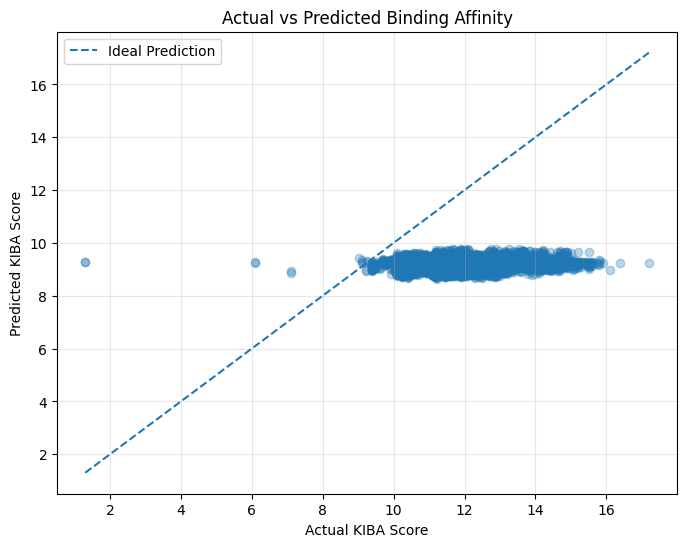

In [40]:

# ============================================================
# CELL 36: ACTUAL VS PREDICTED VALUES
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Plot actual and predicted binding affinity
plt.scatter(
    actual_values,
    predicted_values,
    alpha=0.3
)

# Draw ideal prediction line
minimum = min(
    actual_values.min(),
    predicted_values.min()
)

maximum = max(
    actual_values.max(),
    predicted_values.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Ideal Prediction"
)

plt.xlabel("Actual KIBA Score")
plt.ylabel("Predicted KIBA Score")

plt.title("Actual vs Predicted Binding Affinity")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


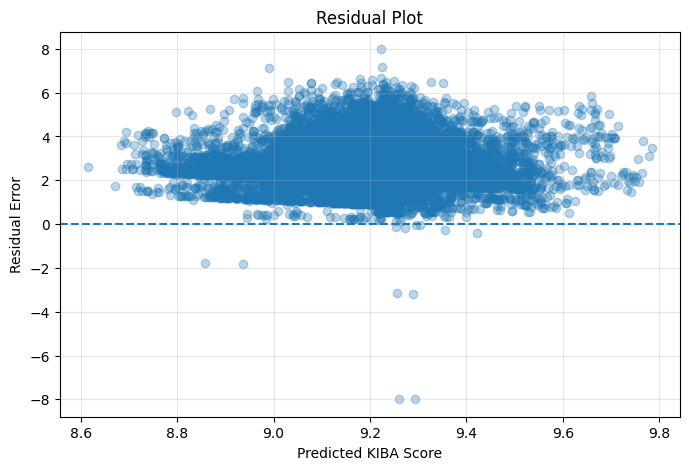

Mean Residual: 2.536355
Residual Standard Deviation: 0.827794


In [41]:

# ============================================================
# CELL 37: RESIDUAL ANALYSIS
# ============================================================

# Calculate prediction errors
residuals = actual_values - predicted_values

plt.figure(figsize=(8, 5))

plt.scatter(
    predicted_values,
    residuals,
    alpha=0.3
)

# Ideal residual reference line
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted KIBA Score")
plt.ylabel("Residual Error")

plt.title("Residual Plot")

plt.grid(alpha=0.3)
plt.show()

print("Mean Residual:",
      round(np.mean(residuals), 6))

print("Residual Standard Deviation:",
      round(np.std(residuals), 6))


In [42]:

# ============================================================
# STAGE 13: MODEL DIAGNOSIS
# CELL 38: COMPARE TRAINING AND TESTING PERFORMANCE
# ============================================================

def get_predictions(loader):

    model.eval()

    actual = []
    predicted = []

    with torch.no_grad():

        for graph_batch, protein_batch, targets in loader:

            graph_batch = graph_batch.to(device)
            protein_batch = protein_batch.to(device)

            predictions = model(
                graph_batch,
                protein_batch
            )

            actual.extend(targets.numpy())
            predicted.extend(predictions.cpu().numpy())

    return np.array(actual), np.array(predicted)


# Evaluate training data in evaluation mode
train_actual, train_predicted = get_predictions(train_loader)

# Evaluate testing data
test_actual, test_predicted = get_predictions(test_loader)


# Display comparison
print("TRAINING VS TESTING DIAGNOSIS")
print("--------------------------------")

print("\nTRAINING DATA")
print("Actual mean:", train_actual.mean())
print("Predicted mean:", train_predicted.mean())
print("Actual standard deviation:", train_actual.std())
print("Predicted standard deviation:", train_predicted.std())
print("Training evaluation MSE:",
      mean_squared_error(train_actual, train_predicted))

print("\nTESTING DATA")
print("Actual mean:", test_actual.mean())
print("Predicted mean:", test_predicted.mean())
print("Actual standard deviation:", test_actual.std())
print("Predicted standard deviation:", test_predicted.std())
print("Testing evaluation MSE:",
      mean_squared_error(test_actual, test_predicted))


# Check prediction collapse
print("\nPREDICTION COLLAPSE CHECK")
print("--------------------------------")

print("Prediction range:",
      test_predicted.min(),
      "to",
      test_predicted.max())

print("Prediction standard deviation:",
      test_predicted.std())

print("Actual standard deviation:",
      test_actual.std())


TRAINING VS TESTING DIAGNOSIS
--------------------------------

TRAINING DATA
Actual mean: 11.721594
Predicted mean: 9.185898
Actual standard deviation: 0.8331043
Predicted standard deviation: 0.13394003
Training evaluation MSE: 7.111490726470947

TESTING DATA
Actual mean: 11.7228985
Predicted mean: 9.1865425
Actual standard deviation: 0.8375244
Predicted standard deviation: 0.13521837
Testing evaluation MSE: 7.118340969085693

PREDICTION COLLAPSE CHECK
--------------------------------
Prediction range: 8.614991 to 9.784106
Prediction standard deviation: 0.13521837
Actual standard deviation: 0.8375244


TARGET DISTRIBUTION COMPARISON
--------------------------------

Training target statistics:
count    94046.000000
mean        11.721593
std          0.833109
min          0.000000
25%         11.200000
50%         11.531798
75%         11.953872
max         17.196910
Name: Binding Affinity, dtype: float64

Testing target statistics:
count    23516.000000
mean        11.722898
std          0.837542
min          1.300000
25%         11.200000
50%         11.553912
75%         11.900001
max         17.200179
Name: Binding Affinity, dtype: float64


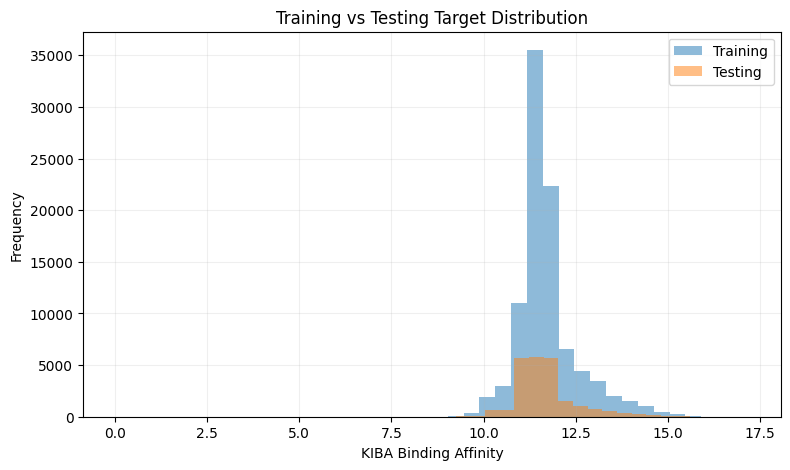

In [43]:

# ============================================================
# CELL 39: CHECK TRAINING AND TESTING TARGET DISTRIBUTIONS
# ============================================================

print("TARGET DISTRIBUTION COMPARISON")
print("--------------------------------")

print("\nTraining target statistics:")
print(train_clean["Binding Affinity"].describe())

print("\nTesting target statistics:")
print(test_clean["Binding Affinity"].describe())

# Visualize both distributions
plt.figure(figsize=(9, 5))

plt.hist(
    train_clean["Binding Affinity"],
    bins=40,
    alpha=0.5,
    label="Training"
)

plt.hist(
    test_clean["Binding Affinity"],
    bins=40,
    alpha=0.5,
    label="Testing"
)

plt.xlabel("KIBA Binding Affinity")
plt.ylabel("Frequency")

plt.title("Training vs Testing Target Distribution")

plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [44]:

# ============================================================
# STAGE 14: TRAINING INCONSISTENCY DIAGNOSIS
# CELL 40: VERIFY MODEL OUTPUTS
# ============================================================

model.eval()

# Get one training batch
graph_batch, protein_batch, targets = next(iter(train_loader))

graph_batch = graph_batch.to(device)
protein_batch = protein_batch.to(device)
targets = targets.to(device)

with torch.no_grad():

    # Predictions in evaluation mode
    model.eval()
    eval_predictions = model(graph_batch, protein_batch)

    # Predictions in training mode
    model.train()
    train_predictions = model(graph_batch, protein_batch)

    model.eval()

print("BATCH DIAGNOSTIC RESULTS")
print("--------------------------------")

print("Actual target mean:", targets.mean().item())

print("Evaluation prediction mean:",
      eval_predictions.mean().item())

print("Training prediction mean:",
      train_predictions.mean().item())

print("Evaluation batch MSE:",
      criterion(eval_predictions, targets).item())

print("Training batch MSE:",
      criterion(train_predictions, targets).item())

print("\nActual target standard deviation:",
      targets.std().item())

print("Prediction standard deviation:",
      eval_predictions.std().item())


BATCH DIAGNOSTIC RESULTS
--------------------------------
Actual target mean: 11.801185607910156
Evaluation prediction mean: 9.201528549194336
Training prediction mean: 11.537518501281738
Evaluation batch MSE: 7.511526107788086
Training batch MSE: 0.9112676978111267

Actual target standard deviation: 0.8943725824356079
Prediction standard deviation: 0.15047422051429749


In [45]:

# ============================================================
# CELL 41: TARGET NORMALIZATION
# ============================================================

# Calculate statistics using training data only
y_mean = train_clean["Binding Affinity"].mean()
y_std = train_clean["Binding Affinity"].std()

print("TARGET NORMALIZATION")
print("--------------------------------")

print("Training target mean:", y_mean)
print("Training target standard deviation:", y_std)

# Modify dataset to return normalized targets
class NormalizedDrugProteinDataset(DrugProteinDataset):

    def __getitem__(self, index):

        graph, protein, target = super().__getitem__(index)

        # Standardize target using training statistics
        target = (target - y_mean) / y_std

        return graph, protein, target


# Recreate datasets
train_dataset = NormalizedDrugProteinDataset(train_clean)
test_dataset = NormalizedDrugProteinDataset(test_clean)

# Recreate data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    collate_fn=collate_graphs
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    collate_fn=collate_graphs
)

print("\nNormalized datasets created successfully!")


TARGET NORMALIZATION
--------------------------------
Training target mean: 11.721592534485476
Training target standard deviation: 0.8331087636917053

Normalized datasets created successfully!


In [47]:

# ============================================================
# CELL 42: RETRAIN WITH NORMALIZED TARGETS
# ============================================================

# Initialize a fresh model
model = DrugTargetGNN().to(device)

# MSE loss
criterion = nn.MSELoss()

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.0001
)

# Training configuration
EPOCHS = 15

normalized_losses = []

print("RETRAINING MODEL")
print("--------------------------------")

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0
    total_samples = 0

    for graph_batch, protein_batch, targets in train_loader:

        graph_batch = graph_batch.to(device)
        protein_batch = protein_batch.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        predictions = model(
            graph_batch,
            protein_batch
        )

        loss = criterion(predictions, targets)

        loss.backward()

        optimizer.step()

        batch_size = targets.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    epoch_loss = total_loss / total_samples

    normalized_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Normalized MSE: {epoch_loss:.6f}"
    )

print("\nRETRAINING COMPLETED!")


RETRAINING MODEL
--------------------------------
Epoch [1/15] Normalized MSE: 0.999831
Epoch [2/15] Normalized MSE: 0.996247
Epoch [3/15] Normalized MSE: 0.994520
Epoch [4/15] Normalized MSE: 0.994145
Epoch [5/15] Normalized MSE: 0.993507
Epoch [6/15] Normalized MSE: 0.992686
Epoch [7/15] Normalized MSE: 0.992561
Epoch [8/15] Normalized MSE: 0.992455
Epoch [9/15] Normalized MSE: 0.991818
Epoch [10/15] Normalized MSE: 0.990082
Epoch [11/15] Normalized MSE: 0.989161
Epoch [12/15] Normalized MSE: 0.985857
Epoch [13/15] Normalized MSE: 0.981169
Epoch [14/15] Normalized MSE: 0.974811
Epoch [15/15] Normalized MSE: 0.973654

RETRAINING COMPLETED!


In [48]:

# ============================================================
# STAGE 15: EVALUATE NORMALIZED GNN MODEL
# CELL 43: TEST PERFORMANCE AND BASELINE COMPARISON
# ============================================================

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Put model in evaluation mode
model.eval()

actual_normalized = []
predicted_normalized = []

# Generate predictions on testing data
with torch.no_grad():

    for graph_batch, protein_batch, targets in test_loader:

        graph_batch = graph_batch.to(device)
        protein_batch = protein_batch.to(device)

        predictions = model(
            graph_batch,
            protein_batch
        )

        actual_normalized.extend(targets.numpy())
        predicted_normalized.extend(predictions.cpu().numpy())

# Convert to NumPy arrays
actual_normalized = np.array(actual_normalized)
predicted_normalized = np.array(predicted_normalized)

# Convert normalized values back to original KIBA scale
actual_original = actual_normalized * y_std + y_mean
predicted_original = predicted_normalized * y_std + y_mean

# Calculate metrics in original scale
mse = mean_squared_error(actual_original, predicted_original)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual_original, predicted_original)
r2 = r2_score(actual_original, predicted_original)

# Calculate simple mean-prediction baseline
baseline_predictions = np.full_like(
    actual_original,
    y_mean
)

baseline_mse = mean_squared_error(
    actual_original,
    baseline_predictions
)

baseline_r2 = r2_score(
    actual_original,
    baseline_predictions
)

print("IMPROVED MODEL EVALUATION")
print("--------------------------------")

print("MSE:", round(mse, 6))
print("RMSE:", round(rmse, 6))
print("MAE:", round(mae, 6))
print("R2 Score:", round(r2, 6))

print("\nBASELINE COMPARISON")
print("--------------------------------")

print("Baseline MSE:", round(baseline_mse, 6))
print("Baseline R2:", round(baseline_r2, 6))

print("\nPREDICTION ANALYSIS")
print("--------------------------------")

print("Actual mean:", round(actual_original.mean(), 4))
print("Predicted mean:", round(predicted_original.mean(), 4))

print("Actual standard deviation:",
      round(actual_original.std(), 4))

print("Predicted standard deviation:",
      round(predicted_original.std(), 4))


IMPROVED MODEL EVALUATION
--------------------------------
MSE: 0.685149
RMSE: 0.827737
MAE: 0.59268
R2 Score: 0.023235

BASELINE COMPARISON
--------------------------------
Baseline MSE: 0.701449
Baseline R2: -2e-06

PREDICTION ANALYSIS
--------------------------------
Actual mean: 11.7229
Predicted mean: 11.7654
Actual standard deviation: 0.8375
Predicted standard deviation: 0.158


In [49]:

import os
import subprocess

if not os.path.exists("DeepDTA"):
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/hkmztrk/DeepDTA.git"
    ], check=True)

print("Repository downloaded successfully!")
print("Davis folder:", os.listdir("DeepDTA/data/davis"))


Repository downloaded successfully!
Davis folder: ['folds', 'Y', 'ligands_can.txt', 'drug-target_interaction_affinities_Kd__Davis_et_al.2011v1.txt', 'drug-drug_similarities_2D.txt', 'proteins.txt', 'target-target_similarities_WS.txt', 'ligands_iso.txt']


In [50]:

# CELL 45: Load Davis dataset

import json
import pickle
import numpy as np
import pandas as pd

davis_path = "DeepDTA/data/davis"

# Load drug SMILES
with open(f"{davis_path}/ligands_can.txt", "r") as f:
    davis_drugs = json.load(f)

# Load protein sequences
with open(f"{davis_path}/proteins.txt", "r") as f:
    davis_proteins = json.load(f)

# Load affinity matrix
with open(f"{davis_path}/Y", "rb") as f:
    davis_Y = pickle.load(f, encoding="latin1")

davis_Y = np.asarray(davis_Y, dtype=float)

print("Davis dataset loaded!")
print("Drug count:", len(davis_drugs))
print("Protein count:", len(davis_proteins))
print("Affinity matrix:", davis_Y.shape)



Davis dataset loaded!
Drug count: 68
Protein count: 442
Affinity matrix: (68, 442)


In [51]:

# CELL 46: Prepare Davis interaction records

drug_smiles = list(davis_drugs.values())
protein_sequences = list(davis_proteins.values())

rows = []

for i in range(davis_Y.shape[0]):
    for j in range(davis_Y.shape[1]):

        kd_nm = davis_Y[i, j]

        if np.isfinite(kd_nm) and kd_nm > 0:
            pkd = 9 - np.log10(kd_nm)

            rows.append({
                "Molecule Sequence": drug_smiles[i],
                "Protein Sequence": protein_sequences[j],
                "Binding Affinity": pkd,
                "Original Kd (nM)": kd_nm
            })

davis_df = pd.DataFrame(rows)

print("Davis DataFrame:", davis_df.shape)
print("Unique drugs:", davis_df["Molecule Sequence"].nunique())
print("Unique proteins:", davis_df["Protein Sequence"].nunique())

display(davis_df.head())


Davis DataFrame: (30056, 4)
Unique drugs: 68
Unique proteins: 379


,Molecule Sequence,Protein Sequence,Binding Affinity,Original Kd (nM)
0,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,7.366532,43.0
1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000,10000.0
2,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000,10000.0
3,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000,10000.0
4,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000,10000.0


In [55]:

# CELL 47: Download BindingDB without PyTDC

import requests
import zipfile
import os
import pandas as pd

bindingdb_url = (
    "https://www.bindingdb.org/rwd/bind/downloads/"
    "BindingDB_BindingDB_Articles_202611_tsv.zip"
)

zip_path = "BindingDB_Articles.zip"

print("Downloading BindingDB...")

response = requests.get(bindingdb_url, stream=True, timeout=180)
response.raise_for_status()

with open(zip_path, "wb") as f:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)

print("Download completed!")
print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

# Inspect files inside ZIP
with zipfile.ZipFile(zip_path, "r") as z:
    print("\nFiles inside ZIP:")
    print(z.namelist())


Download completed!
File size: 17.43 MB

Files inside ZIP:
['BindingDB_BindingDB_Articles.tsv']


In [56]:

# CELL 48: Read BindingDB TSV

with zipfile.ZipFile(zip_path, "r") as z:

    tsv_files = [
        name for name in z.namelist()
        if name.lower().endswith((".tsv", ".txt"))
    ]

    if not tsv_files:
        raise ValueError("No TSV file found inside ZIP!")

    tsv_name = tsv_files[0]

    with z.open(tsv_name) as f:
        bindingdb_df = pd.read_csv(
            f,
            sep="\t",
            low_memory=False,
            on_bad_lines="skip"
        )

print("BindingDB loaded successfully!")
print("Shape:", bindingdb_df.shape)

print("\nColumn names:")
print(bindingdb_df.columns.tolist())

display(bindingdb_df.head(3))


BindingDB loaded successfully!
Shape: (93712, 640)

Column names:
['BindingDB Reactant_set_id', 'Ligand SMILES', 'Ligand InChI', 'Ligand InChI Key', 'BindingDB MonomerID', 'BindingDB Ligand Name', 'Target Name', 'Target Source Organism According to Curator or DataSource', 'Ki (nM)', 'IC50 (nM)', 'Kd (nM)', 'EC50 (nM)', 'koff (s-1)', 'kon (M-1-s-1)', 'pH', 'Temp (C)', 'Curation/DataSource', 'Article DOI', 'BindingDB Entry DOI', 'PMID', 'PubChem AID', 'Patent Number', 'Authors', 'Date of publication', 'Date in BindingDB', 'Institution', 'Link to Ligand in BindingDB', 'Link to Target in BindingDB', 'Link to Ligand-Target Pair in BindingDB', 'Ligand HET ID in PDB', 'PDB ID(s) for Ligand-Target Complex', 'PubChem CID', 'PubChem SID', 'ChEBI ID of Ligand', 'ChEMBL ID of Ligand', 'DrugBank ID of Ligand', 'IUPHAR_GRAC ID of Ligand', 'KEGG ID of Ligand', 'ZINC ID of Ligand', 'Number of Protein Chains in Target (>1 implies a multichain complex)', 'BindingDB Target Chain Sequence 1', 'PDB ID(s) o

,BindingDB Reactant_set_id,Ligand SMILES,Ligand InChI,Ligand InChI Key,BindingDB MonomerID,BindingDB Ligand Name,Target Name,Target Source Organism According to Curator or DataSource,Ki (nM),IC50 (nM),...,UniProt (SwissProt) Recommended Name of Target Chain 50,UniProt (SwissProt) Entry Name of Target Chain 50,UniProt (SwissProt) Primary ID of Target Chain 50,UniProt (SwissProt) Secondary ID(s) of Target Chain 50,UniProt (SwissProt) Alternative ID(s) of Target Chain 50,UniProt (TrEMBL) Submitted Name of Target Chain 50,UniProt (TrEMBL) Entry Name of Target Chain 50,UniProt (TrEMBL) Primary ID of Target Chain 50,UniProt (TrEMBL) Secondary ID(s) of Target Chain 50,UniProt (TrEMBL) Alternative ID(s) of Target Chain 50
0,9825,COc1cc2c(Nc3ccc(Cl)cc3Cl)c(cnc2cc1OCCCN1CCN(C)...,InChI=1S/C25H27Cl2N5O2/c1-31-7-9-32(10-8-31)6-...,MVQUQGLRQPMJPU-UHFFFAOYSA-N,4521,"4-[(2,4-dichlorophenyl)amino]-6-methoxy-7-[3-(...",Proto-oncogene tyrosine-protein kinase Src,Homo sapiens,NaN,8.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,9826,COc1cc2c(Nc3cc(OC)c(OC)c(OC)c3)c(cnc2cc1OCCCN1...,InChI=1S/C28H35N5O5/c1-32-8-10-33(11-9-32)7-6-...,VOUVVBUKNLBXGS-UHFFFAOYSA-N,6121,6-methoxy-7-[3-(4-methylpiperazin-1-yl)propoxy...,Proto-oncogene tyrosine-protein kinase Src,Homo sapiens,NaN,5.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9827,COCCOc1cc2ncc(C#N)c(Nc3cc(OC)c(Cl)cc3Cl)c2cc1O...,InChI=1S/C23H23Cl2N3O5/c1-29-4-6-32-21-8-15-18...,VXEOIAFZWQMOEP-UHFFFAOYSA-N,6122,"4-[(2,4-dichloro-5-methoxyphenyl)amino]-6,7-bi...",Proto-oncogene tyrosine-protein kinase Src,Homo sapiens,NaN,2.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [57]:

# CELL 49: Identify relevant BindingDB columns

for col in bindingdb_df.columns:
    if any(word in col.lower() for word in [
        "smiles", "kd (nm)", "chain sequence",
        "target name", "reactant_set_id"
    ]):
        print("\nCOLUMN:", repr(col))
        print(bindingdb_df[col].dropna().head(3).tolist())



COLUMN: 'BindingDB Reactant_set_id'
[9825, 9826, 9827]

COLUMN: 'Ligand SMILES'
['COc1cc2c(Nc3ccc(Cl)cc3Cl)c(cnc2cc1OCCCN1CCN(C)CC1)C#N', 'COc1cc2c(Nc3cc(OC)c(OC)c(OC)c3)c(cnc2cc1OCCCN1CCN(C)CC1)C#N', 'COCCOc1cc2ncc(C#N)c(Nc3cc(OC)c(Cl)cc3Cl)c2cc1OCCOC']

COLUMN: 'Target Name'
['Proto-oncogene tyrosine-protein kinase Src', 'Proto-oncogene tyrosine-protein kinase Src', 'Proto-oncogene tyrosine-protein kinase Src']

COLUMN: 'Kd (nM)'
[' 43000', ' 77000', ' 100000']

COLUMN: 'BindingDB Target Chain Sequence 1'
['MGSNKSKPKDASQRRRSLEPAENVHGAGGGAFPASQTPSKPASADGHRGPSAAFAPAAAEPKLFGGFNSSDTVTSPQRAGPLAGGVTTFVALYDYESRTETDLSFKKGERLQIVNNTEGDWWLAHSLSTGQTGYIPSNYVAPSDSIQAEEWYFGKITRRESERLLLNAENPRGTFLVRESETTKGAYCLSVSDFDNAKGLNVKHYKIRKLDSGGFYITSRTQFNSLQQLVAYYSKHADGLCHRLTTVCPTSKPQTQGLAKDAWEIPRESLRLEVKLGQGCFGEVWMGTWNGTTRVAIKTLKPGTMSPEAFLQEAQVMKKLRHEKLVQLYAVVSEEPIYIVTEYMSKGSLLDFLKGETGKYLRLPQLVDMAAQIASGMAYVERMNYVHRDLRAANILVGENLVCKVADFGLARLIEDNEYTARQGAKFPIKWTAPEAALYGRFTIKSDVWSFGILLTELTTKGRVPYPGMVNREVLDQVERGYRM

In [58]:

# CELL 50: Extract and clean BindingDB information

import re
import numpy as np
import pandas as pd

# Identify all protein chain sequence columns
chain_cols = [
    col for col in bindingdb_df.columns
    if "BindingDB Target Chain Sequence" in col
]

print("Protein chain columns found:", len(chain_cols))
print(chain_cols)

# Standard 20 amino acids
valid_amino_acids = set("ACDEFGHIKLMNPQRSTVWY")

# Clean protein sequences
def clean_sequence(value):
    if pd.isna(value):
        return ""

    sequence = str(value).upper()
    sequence = re.sub(r"\s+", "", sequence)

    if not sequence:
        return ""

    if not set(sequence).issubset(valid_amino_acids):
        return ""

    return sequence

# Select the longest valid chain in each record
def select_longest_chain(row):
    sequences = [
        clean_sequence(row[col])
        for col in chain_cols
    ]

    valid_sequences = [s for s in sequences if s]

    if not valid_sequences:
        return ""

    return max(valid_sequences, key=len)

# Extract Kd values
kd_numeric = pd.to_numeric(
    bindingdb_df["Kd (nM)"],
    errors="coerce"
)

# Build clean dataset
bindingdb_clean = pd.DataFrame({
    "Molecule Sequence": bindingdb_df["Ligand SMILES"].astype(str).str.strip(),
    "Protein Sequence": bindingdb_df.apply(select_longest_chain, axis=1),
    "Kd (nM)": kd_numeric
})

# Keep valid measurements and records
bindingdb_clean = bindingdb_clean[
    (bindingdb_clean["Kd (nM)"] > 0) &
    (bindingdb_clean["Molecule Sequence"] != "") &
    (bindingdb_clean["Molecule Sequence"].str.lower() != "nan") &
    (bindingdb_clean["Protein Sequence"] != "")
].copy()

# Convert Kd (nM) to pKd
bindingdb_clean["Binding Affinity"] = (
    9 - np.log10(bindingdb_clean["Kd (nM)"])
)

bindingdb_clean.reset_index(drop=True, inplace=True)

print("\nBindingDB preprocessing completed!")
print("Valid records:", len(bindingdb_clean))
print("Unique drugs:", bindingdb_clean["Molecule Sequence"].nunique())
print("Unique proteins:", bindingdb_clean["Protein Sequence"].nunique())

display(bindingdb_clean.head())


Protein chain columns found: 50
['BindingDB Target Chain Sequence 1', 'BindingDB Target Chain Sequence 2', 'BindingDB Target Chain Sequence 3', 'BindingDB Target Chain Sequence 4', 'BindingDB Target Chain Sequence 5', 'BindingDB Target Chain Sequence 6', 'BindingDB Target Chain Sequence 7', 'BindingDB Target Chain Sequence 8', 'BindingDB Target Chain Sequence 9', 'BindingDB Target Chain Sequence 10', 'BindingDB Target Chain Sequence 11', 'BindingDB Target Chain Sequence 12', 'BindingDB Target Chain Sequence 13', 'BindingDB Target Chain Sequence 14', 'BindingDB Target Chain Sequence 15', 'BindingDB Target Chain Sequence 16', 'BindingDB Target Chain Sequence 17', 'BindingDB Target Chain Sequence 18', 'BindingDB Target Chain Sequence 19', 'BindingDB Target Chain Sequence 20', 'BindingDB Target Chain Sequence 21', 'BindingDB Target Chain Sequence 22', 'BindingDB Target Chain Sequence 23', 'BindingDB Target Chain Sequence 24', 'BindingDB Target Chain Sequence 25', 'BindingDB Target Chain Se

,Molecule Sequence,Protein Sequence,Kd (nM),Binding Affinity
0,CC(=O)CCCCN1C(=O)c2c(ncn2C)N(C1=O)C,MRFATSTIVKVALLLSSLCVDAAVMWNRDTSSTDLEARASSGYRSV...,43000.0,4.366532
1,CC(=O)CCCCN1C(=O)c2c(ncn2C)N(C1=O)C,MRFATSTIVKVALLLSSLCVDAAVMWNRDTSSTDLEARASSGYRSV...,77000.0,4.113509
2,CC(=O)CCCCN1C(=O)c2c(ncn2C)N(C1=O)C,MRFATSTIVKVALLLSSLCVDAAVMWNRDTSSTDLEARASSGYRSV...,100000.0,4.000000
3,CC(=O)CCCCN1C(=O)c2c(ncn2C)N(C1=O)C,MRFATSTIVKVALLLSSLCVDAAVMWNRDTSSTDLEARASSGYRSV...,62000.0,4.207608
4,CC(=O)CCCCN1C(=O)c2c(ncn2C)N(C1=O)C,MRFATSTIVKVALLLSSLCVDAAVMWNRDTSSTDLEARASSGYRSV...,45000.0,4.346787


In [59]:

# CELL 51: BindingDB statistics

print("Cleaned dataset shape:", bindingdb_clean.shape)

print("\nMissing values:")
print(bindingdb_clean.isnull().sum())

print("\nKd (nM) statistics:")
print(bindingdb_clean["Kd (nM)"].describe())

print("\npKd statistics:")
print(bindingdb_clean["Binding Affinity"].describe())

print("\nProtein sequence length:")
print(bindingdb_clean["Protein Sequence"].str.len().describe())

print("\nDuplicate drug-protein pairs:",
      bindingdb_clean.duplicated(
          subset=["Molecule Sequence", "Protein Sequence"]
      ).sum())


Cleaned dataset shape: (2490, 4)

Missing values:
Molecule Sequence    0
Protein Sequence     0
Kd (nM)              0
Binding Affinity     0
dtype: int64

Kd (nM) statistics:
count    2.490000e+03
mean     1.805825e+05
std      2.208835e+06
min      4.700000e-05
25%      2.000000e+01
50%      6.000000e+02
75%      1.100000e+04
max      7.680400e+07
Name: Kd (nM), dtype: float64

pKd statistics:
count    2490.000000
mean        6.333292
std         1.807305
min         1.114616
25%         4.958607
50%         6.221849
75%         7.698970
max        13.327902
Name: Binding Affinity, dtype: float64

Protein sequence length:
count    2490.000000
mean      622.975502
std      1244.688268
min        53.000000
25%       250.000000
50%       354.000000
75%       479.250000
max      7096.000000
Name: Protein Sequence, dtype: float64

Duplicate drug-protein pairs: 238


In [60]:

# CELL 52: Standardize SMILES and aggregate duplicate pairs

from rdkit import Chem
import numpy as np
import pandas as pd

def canonicalize_smiles(smiles):
    try:
        mol = Chem.MolFromSmiles(str(smiles))
        if mol is None:
            return None
        return Chem.MolToSmiles(mol, canonical=True)
    except:
        return None

# Create canonical SMILES columns
davis_df["Canonical SMILES"] = davis_df["Molecule Sequence"].apply(
    canonicalize_smiles
)

bindingdb_clean["Canonical SMILES"] = bindingdb_clean[
    "Molecule Sequence"
].apply(canonicalize_smiles)

# Remove invalid structures
davis_df = davis_df.dropna(subset=["Canonical SMILES"]).copy()
bindingdb_clean = bindingdb_clean.dropna(
    subset=["Canonical SMILES"]
).copy()

# Aggregate repeated drug-protein pairs
davis_clean = (
    davis_df.groupby(
        ["Canonical SMILES", "Protein Sequence"],
        as_index=False
    )
    .agg({
        "Binding Affinity": "mean",
        "Original Kd (nM)": "mean"
    })
)

bindingdb_clean = (
    bindingdb_clean.groupby(
        ["Canonical SMILES", "Protein Sequence"],
        as_index=False
    )
    .agg({
        "Binding Affinity": "mean",
        "Kd (nM)": "mean"
    })
)

print("Davis after cleaning:", davis_clean.shape)
print("BindingDB after cleaning:", bindingdb_clean.shape)

print("Davis unique drugs:",
      davis_clean["Canonical SMILES"].nunique())

print("BindingDB unique drugs:",
      bindingdb_clean["Canonical SMILES"].nunique())


[13:51:53] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8
[13:51:53] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8


Davis after cleaning: (25772, 4)
BindingDB after cleaning: (2220, 4)
Davis unique drugs: 68
BindingDB unique drugs: 1362


In [61]:

# CELL 53: Build canonical molecular graph lookup

# Canonicalize existing KIBA graph keys
canonical_graphs = {}

for original_smiles, graph in drug_graphs.items():
    canonical = canonicalize_smiles(original_smiles)

    if canonical is not None and canonical not in canonical_graphs:
        canonical_graphs[canonical] = graph

print("Existing molecular graphs:", len(drug_graphs))
print("Canonical graph entries:", len(canonical_graphs))

# Check whether external drugs have an existing graph
davis_clean["Graph Available"] = (
    davis_clean["Canonical SMILES"].isin(canonical_graphs)
)

bindingdb_clean["Graph Available"] = (
    bindingdb_clean["Canonical SMILES"].isin(canonical_graphs)
)

print("\nDAVIS GRAPH COVERAGE")
print(davis_clean["Graph Available"].value_counts())
print(
    "Coverage:",
    round(100 * davis_clean["Graph Available"].mean(), 2),
    "%"
)

print("\nBINDINGDB GRAPH COVERAGE")
print(bindingdb_clean["Graph Available"].value_counts())
print(
    "Coverage:",
    round(100 * bindingdb_clean["Graph Available"].mean(), 2),
    "%"
)


Existing molecular graphs: 2061
Canonical graph entries: 2061

DAVIS GRAPH COVERAGE
Graph Available
False    22361
True      3411
Name: count, dtype: int64
Coverage: 13.24 %

BINDINGDB GRAPH COVERAGE
Graph Available
False    2210
True       10
Name: count, dtype: int64
Coverage: 0.45 %


In [62]:

# CELL 54: Keep interactions with available molecular graphs

davis_external = davis_clean[
    davis_clean["Graph Available"]
].copy()

bindingdb_external = bindingdb_clean[
    bindingdb_clean["Graph Available"]
].copy()

print("DAVIS external evaluation records:",
      len(davis_external))

print("BINDINGDB external evaluation records:",
      len(bindingdb_external))

print("\nDAVIS affinity summary:")
print(davis_external["Binding Affinity"].describe())

print("\nBINDINGDB affinity summary:")
print(bindingdb_external["Binding Affinity"].describe())

# Save cleaned datasets
davis_external.to_csv("davis_external.csv", index=False)
bindingdb_external.to_csv("bindingdb_external.csv", index=False)

print("\nExternal datasets saved successfully!")


DAVIS external evaluation records: 3411
BINDINGDB external evaluation records: 10

DAVIS affinity summary:
count    3411.000000
mean        5.603753
std         1.001039
min         5.000000
25%         5.000000
50%         5.000000
75%         6.000000
max        10.619789
Name: Binding Affinity, dtype: float64

BINDINGDB affinity summary:
count    10.000000
mean      6.223950
std       0.591595
min       5.050610
25%       5.865889
50%       6.321857
75%       6.646546
max       7.004365
Name: Binding Affinity, dtype: float64

External datasets saved successfully!


In [63]:

# CELL 55: Generate missing external drug graphs

import time
from rdkit import Chem

# Collect all unique external drug structures
external_smiles = set(
    davis_clean["Canonical SMILES"].dropna()
).union(
    set(bindingdb_clean["Canonical SMILES"].dropna())
)

# Find structures not already represented in our graph library
missing_smiles = [
    smiles for smiles in external_smiles
    if smiles not in canonical_graphs
]

print("Existing canonical graphs:", len(canonical_graphs))
print("External unique drugs:", len(external_smiles))
print("Missing graphs to generate:", len(missing_smiles))

new_graphs = {}
failed_external = []

start_time = time.time()

for i, smiles in enumerate(missing_smiles):

    try:
        graph = build_molecular_graph(smiles)

        if graph is not None:
            new_graphs[smiles] = graph
        else:
            failed_external.append(smiles)

    except Exception:
        failed_external.append(smiles)

    if (i + 1) % 25 == 0:
        print(
            f"Processed {i+1}/{len(missing_smiles)} | "
            f"Successful: {len(new_graphs)} | "
            f"Failed: {len(failed_external)}"
        )

# Add generated graphs to the canonical library
canonical_graphs.update(new_graphs)

print("\nGraph generation completed!")
print("New graphs:", len(new_graphs))
print("Failed structures:", len(failed_external))
print("Total canonical graphs:", len(canonical_graphs))
print("Time taken:", round(time.time() - start_time, 2), "seconds")

# Save expanded graph library
torch.save(canonical_graphs, "expanded_drug_graphs.pt")


Existing canonical graphs: 2061
External unique drugs: 1419
Missing graphs to generate: 1402
Processed 25/1402 | Successful: 25 | Failed: 0
Processed 50/1402 | Successful: 49 | Failed: 1
Processed 75/1402 | Successful: 73 | Failed: 2
Processed 100/1402 | Successful: 98 | Failed: 2
Processed 125/1402 | Successful: 122 | Failed: 3
Processed 150/1402 | Successful: 147 | Failed: 3
Processed 175/1402 | Successful: 170 | Failed: 5
Processed 200/1402 | Successful: 194 | Failed: 6
Processed 225/1402 | Successful: 218 | Failed: 7
Processed 250/1402 | Successful: 242 | Failed: 8


[13:56:52] UFFTYPER: Unrecognized charge state for atom: 1


Processed 275/1402 | Successful: 267 | Failed: 8
Processed 300/1402 | Successful: 292 | Failed: 8
Processed 325/1402 | Successful: 317 | Failed: 8
Processed 350/1402 | Successful: 342 | Failed: 8
Processed 375/1402 | Successful: 365 | Failed: 10
Processed 400/1402 | Successful: 389 | Failed: 11
Processed 425/1402 | Successful: 413 | Failed: 12
Processed 450/1402 | Successful: 437 | Failed: 13
Processed 475/1402 | Successful: 461 | Failed: 14
Processed 500/1402 | Successful: 486 | Failed: 14
Processed 525/1402 | Successful: 510 | Failed: 15
Processed 550/1402 | Successful: 535 | Failed: 15
Processed 575/1402 | Successful: 559 | Failed: 16
Processed 600/1402 | Successful: 583 | Failed: 17
Processed 625/1402 | Successful: 606 | Failed: 19
Processed 650/1402 | Successful: 629 | Failed: 21
Processed 675/1402 | Successful: 653 | Failed: 22
Processed 700/1402 | Successful: 677 | Failed: 23
Processed 725/1402 | Successful: 701 | Failed: 24
Processed 750/1402 | Successful: 725 | Failed: 25
Proc

In [64]:

# CELL 56: Recalculate external graph coverage

davis_clean["Graph Available"] = (
    davis_clean["Canonical SMILES"].isin(canonical_graphs)
)

bindingdb_clean["Graph Available"] = (
    bindingdb_clean["Canonical SMILES"].isin(canonical_graphs)
)

davis_external = davis_clean[
    davis_clean["Graph Available"]
].copy()

bindingdb_external = bindingdb_clean[
    bindingdb_clean["Graph Available"]
].copy()

print("DAVIS")
print("Available interactions:", len(davis_external))
print("Unique drugs:", davis_external["Canonical SMILES"].nunique())
print("Unique proteins:", davis_external["Protein Sequence"].nunique())
print("Coverage:", round(
    100 * len(davis_external) / len(davis_clean), 2
), "%")

print("\nBINDINGDB")
print("Available interactions:", len(bindingdb_external))
print("Unique drugs:", bindingdb_external["Canonical SMILES"].nunique())
print("Unique proteins:", bindingdb_external["Protein Sequence"].nunique())
print("Coverage:", round(
    100 * len(bindingdb_external) / len(bindingdb_clean), 2
), "%")


DAVIS
Available interactions: 25772
Unique drugs: 68
Unique proteins: 379
Coverage: 100.0 %

BINDINGDB
Available interactions: 2149
Unique drugs: 1318
Unique proteins: 416
Coverage: 96.8 %


In [65]:

# CELL 57: Prepare KIBA, Davis and BindingDB

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import torch

# Cache canonical SMILES to avoid repeated RDKit calculations
smiles_cache = {}

def get_canonical(smiles):
    if smiles not in smiles_cache:
        smiles_cache[smiles] = canonicalize_smiles(smiles)
    return smiles_cache[smiles]

def prepare_dataset(df):
    data = df.copy()

    data["Canonical SMILES"] = data["Molecule Sequence"].apply(
        get_canonical
    )

    data = data.dropna(
        subset=["Canonical SMILES", "Protein Sequence", "Binding Affinity"]
    )

    data = data[
        data["Canonical SMILES"].isin(canonical_graphs)
    ].copy()

    data = data[
        data["Protein Sequence"].astype(str).str.len() > 0
    ]

    data = data.groupby(
        ["Canonical SMILES", "Protein Sequence"],
        as_index=False
    )["Binding Affinity"].mean()

    return data.reset_index(drop=True)

# KIBA: use existing clean train and test split
kiba_train = prepare_dataset(train_clean)
kiba_test = prepare_dataset(test_clean)

# Davis: create an independent split
davis_data = prepare_dataset(
    davis_external.assign(
        **{"Molecule Sequence": davis_external["Canonical SMILES"]}
    )
)

davis_train, davis_test = train_test_split(
    davis_data, test_size=0.20, random_state=42
)

# BindingDB: create an independent split
binding_data = prepare_dataset(
    bindingdb_external.assign(
        **{"Molecule Sequence": bindingdb_external["Canonical SMILES"]}
    )
)

binding_train, binding_test = train_test_split(
    binding_data, test_size=0.20, random_state=42
)

print("KIBA:", len(kiba_train), "train |", len(kiba_test), "test")
print("Davis:", len(davis_train), "train |", len(davis_test), "test")
print("BindingDB:", len(binding_train), "train |", len(binding_test), "test")


KIBA: 94046 train | 23516 test
Davis: 20617 train | 5155 test
BindingDB: 1719 train | 430 test


In [66]:

# CELL 58: Hybrid model data preparation

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from torch_geometric.data import Batch
from torch_geometric.nn import GINEConv, global_mean_pool, global_max_pool

amino_acids = "ACDEFGHIKLMNPQRSTVWY"
aa_to_idx = {aa: i + 1 for i, aa in enumerate(amino_acids)}
UNKNOWN_IDX = 21

def encode_protein(sequence):
    return torch.tensor(
        [aa_to_idx.get(aa, UNKNOWN_IDX) for aa in str(sequence).upper()],
        dtype=torch.long
    )

def prepare_graph(smiles):
    graph = canonical_graphs[smiles].clone()

    graph.x = graph.x.float().clone()
    graph.x[:, 0] /= 20.0
    graph.x[:, 1] /= 6.0
    graph.x[:, 2] /= 3.0
    graph.x[:, 3] /= 4.0
    graph.x[:, 5] /= 200.0

    src, dst = graph.edge_index

    distances = torch.norm(
        graph.pos[src] - graph.pos[dst],
        dim=1
    ).view(-1, 1) / 5.0

    graph.edge_attr = torch.cat(
        [graph.edge_attr.float(), distances.float()],
        dim=1
    )

    return graph

class HybridDataset(Dataset):

    def __init__(self, dataframe, target_mean, target_std):
        self.df = dataframe.reset_index(drop=True)
        self.mean = target_mean
        self.std = target_std

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        graph = prepare_graph(row["Canonical SMILES"])
        protein = encode_protein(row["Protein Sequence"])

        target = (
            float(row["Binding Affinity"]) - self.mean
        ) / self.std

        return graph, protein, torch.tensor(target, dtype=torch.float32)

def hybrid_collate(batch):
    graphs, proteins, targets = zip(*batch)

    graph_batch = Batch.from_data_list(list(graphs))
    lengths = torch.tensor([len(p) for p in proteins])

    padded_proteins = pad_sequence(
        list(proteins),
        batch_first=True,
        padding_value=0
    )

    return graph_batch, padded_proteins, lengths, torch.stack(targets)

print("Hybrid dataset and sequence encoder ready!")


Hybrid dataset and sequence encoder ready!


In [67]:

# CELL 59: Advanced GINE-GNN + Protein CNN

class HybridDrugTargetModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Drug molecular graph encoder
        self.atom_encoder = nn.Linear(6, 64)

        self.gnn1 = GINEConv(
            nn.Sequential(
                nn.Linear(64, 64),
                nn.ReLU(),
                nn.Linear(64, 64)
            ),
            edge_dim=5
        )

        self.gnn2 = GINEConv(
            nn.Sequential(
                nn.Linear(64, 64),
                nn.ReLU(),
                nn.Linear(64, 64)
            ),
            edge_dim=5
        )

        self.norm1 = nn.LayerNorm(64)
        self.norm2 = nn.LayerNorm(64)

        # Protein sequence encoder
        self.embedding = nn.Embedding(
            22, 32, padding_idx=0
        )

        self.protein_conv1 = nn.Conv1d(
            32, 64, kernel_size=7, padding=3
        )

        self.protein_conv2 = nn.Conv1d(
            64, 64, kernel_size=5, padding=2
        )

        # Feature fusion
        self.fusion = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        self.regressor = nn.Linear(64, 1)

    def forward(self, graph, protein, lengths):

        # GNN branch
        x = self.atom_encoder(graph.x)

        x = F.relu(
            self.norm1(
                self.gnn1(x, graph.edge_index, graph.edge_attr)
            )
        )

        x = F.relu(
            self.norm2(
                self.gnn2(x, graph.edge_index, graph.edge_attr)
            )
        )

        drug_mean = global_mean_pool(x, graph.batch)
        drug_max = global_max_pool(x, graph.batch)

        drug_features = torch.cat(
            [drug_mean, drug_max], dim=1
        )

        # Protein CNN branch
        p = self.embedding(protein)
        p = p.transpose(1, 2)

        p = F.relu(self.protein_conv1(p))
        p = F.relu(self.protein_conv2(p))

        positions = torch.arange(
            p.shape[2], device=p.device
        ).unsqueeze(0)

        mask = positions < lengths.to(p.device).unsqueeze(1)
        mask = mask.unsqueeze(1)

        mean_pool = (
            (p * mask).sum(dim=2) /
            lengths.to(p.device).float().unsqueeze(1)
        )

        max_pool = p.masked_fill(
            ~mask, torch.finfo(p.dtype).min
        ).max(dim=2).values

        protein_features = torch.cat(
            [mean_pool, max_pool], dim=1
        )

        # Fusion and prediction
        combined = torch.cat(
            [drug_features, protein_features], dim=1
        )

        fused = self.fusion(combined)

        return self.regressor(fused).squeeze(1)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = HybridDrugTargetModel().to(device)

print("Advanced hybrid model created!")
print("Device:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


Advanced hybrid model created!
Device: cpu
Trainable parameters: 94977


In [68]:

# CELL 60: Save project data before switching runtime

import torch
import pickle

# Save expanded molecular graphs
torch.save(canonical_graphs, "expanded_drug_graphs.pt")

# Save all prepared dataset splits
project_data = {
    "kiba_train": kiba_train,
    "kiba_test": kiba_test,
    "davis_train": davis_train,
    "davis_test": davis_test,
    "binding_train": binding_train,
    "binding_test": binding_test
}

with open("multi_dataset_splits.pkl", "wb") as f:
    pickle.dump(project_data, f)

print("Project state saved successfully!")
print("Graph library:", len(canonical_graphs))
print("Dataset splits:", list(project_data.keys()))


Project state saved successfully!
Graph library: 3419
Dataset splits: ['kiba_train', 'kiba_test', 'davis_train', 'davis_test', 'binding_train', 'binding_test']


In [69]:

# CELL 61: Restore project after runtime restart

import torch
import pickle

canonical_graphs = torch.load(
    "expanded_drug_graphs.pt",
    map_location="cpu",
    weights_only=False
)

with open("multi_dataset_splits.pkl", "rb") as f:
    project_data = pickle.load(f)

kiba_train = project_data["kiba_train"]
kiba_test = project_data["kiba_test"]
davis_train = project_data["davis_train"]
davis_test = project_data["davis_test"]
binding_train = project_data["binding_train"]
binding_test = project_data["binding_test"]

print("Project restored!")
print("Molecular graphs:", len(canonical_graphs))
print("KIBA:", len(kiba_train), len(kiba_test))
print("Davis:", len(davis_train), len(davis_test))
print("BindingDB:", len(binding_train), len(binding_test))

print("GPU available:", torch.cuda.is_available())


Project restored!
Molecular graphs: 3419
KIBA: 94046 23516
Davis: 20617 5155
BindingDB: 1719 430
GPU available: False


In [70]:

# CELL 62: Check GPU availability

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not enabled. CPU mode is active.")


PyTorch version: 2.14.1+cpu
CUDA available: False
GPU not enabled. CPU mode is active.


In [71]:

import torch
import os
import pickle

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("CPU threads:", os.cpu_count())

# Check saved project files
print("\nSaved files:")
print(os.path.exists("expanded_drug_graphs.pt"))
print(os.path.exists("multi_dataset_splits.pkl"))


PyTorch: 2.14.1+cpu
GPU available: False
CPU threads: 2

Saved files:
True
True


In [72]:

# CELL 58: Hybrid model data preparation

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from torch_geometric.data import Batch
from torch_geometric.nn import GINEConv, global_mean_pool, global_max_pool

amino_acids = "ACDEFGHIKLMNPQRSTVWY"
aa_to_idx = {aa: i + 1 for i, aa in enumerate(amino_acids)}
UNKNOWN_IDX = 21

def encode_protein(sequence):
    return torch.tensor(
        [aa_to_idx.get(aa, UNKNOWN_IDX) for aa in str(sequence).upper()],
        dtype=torch.long
    )

def prepare_graph(smiles):
    graph = canonical_graphs[smiles].clone()

    graph.x = graph.x.float().clone()
    graph.x[:, 0] /= 20.0
    graph.x[:, 1] /= 6.0
    graph.x[:, 2] /= 3.0
    graph.x[:, 3] /= 4.0
    graph.x[:, 5] /= 200.0

    src, dst = graph.edge_index

    distances = torch.norm(
        graph.pos[src] - graph.pos[dst],
        dim=1
    ).view(-1, 1) / 5.0

    graph.edge_attr = torch.cat(
        [graph.edge_attr.float(), distances.float()],
        dim=1
    )

    return graph

class HybridDataset(Dataset):

    def __init__(self, dataframe, target_mean, target_std):
        self.df = dataframe.reset_index(drop=True)
        self.mean = target_mean
        self.std = target_std

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        graph = prepare_graph(row["Canonical SMILES"])
        protein = encode_protein(row["Protein Sequence"])

        target = (
            float(row["Binding Affinity"]) - self.mean
        ) / self.std

        return graph, protein, torch.tensor(target, dtype=torch.float32)

def hybrid_collate(batch):
    graphs, proteins, targets = zip(*batch)

    graph_batch = Batch.from_data_list(list(graphs))
    lengths = torch.tensor([len(p) for p in proteins])

    padded_proteins = pad_sequence(
        list(proteins),
        batch_first=True,
        padding_value=0
    )

    return graph_batch, padded_proteins, lengths, torch.stack(targets)

print("Hybrid dataset and sequence encoder ready!")


Hybrid dataset and sequence encoder ready!


In [73]:

# CELL 59: Advanced GINE-GNN + Protein CNN

class HybridDrugTargetModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Drug molecular graph encoder
        self.atom_encoder = nn.Linear(6, 64)

        self.gnn1 = GINEConv(
            nn.Sequential(
                nn.Linear(64, 64),
                nn.ReLU(),
                nn.Linear(64, 64)
            ),
            edge_dim=5
        )

        self.gnn2 = GINEConv(
            nn.Sequential(
                nn.Linear(64, 64),
                nn.ReLU(),
                nn.Linear(64, 64)
            ),
            edge_dim=5
        )

        self.norm1 = nn.LayerNorm(64)
        self.norm2 = nn.LayerNorm(64)

        # Protein sequence encoder
        self.embedding = nn.Embedding(
            22, 32, padding_idx=0
        )

        self.protein_conv1 = nn.Conv1d(
            32, 64, kernel_size=7, padding=3
        )

        self.protein_conv2 = nn.Conv1d(
            64, 64, kernel_size=5, padding=2
        )

        # Feature fusion
        self.fusion = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        self.regressor = nn.Linear(64, 1)

    def forward(self, graph, protein, lengths):

        # GNN branch
        x = self.atom_encoder(graph.x)

        x = F.relu(
            self.norm1(
                self.gnn1(x, graph.edge_index, graph.edge_attr)
            )
        )

        x = F.relu(
            self.norm2(
                self.gnn2(x, graph.edge_index, graph.edge_attr)
            )
        )

        drug_mean = global_mean_pool(x, graph.batch)
        drug_max = global_max_pool(x, graph.batch)

        drug_features = torch.cat(
            [drug_mean, drug_max], dim=1
        )

        # Protein CNN branch
        p = self.embedding(protein)
        p = p.transpose(1, 2)

        p = F.relu(self.protein_conv1(p))
        p = F.relu(self.protein_conv2(p))

        positions = torch.arange(
            p.shape[2], device=p.device
        ).unsqueeze(0)

        mask = positions < lengths.to(p.device).unsqueeze(1)
        mask = mask.unsqueeze(1)

        mean_pool = (
            (p * mask).sum(dim=2) /
            lengths.to(p.device).float().unsqueeze(1)
        )

        max_pool = p.masked_fill(
            ~mask, torch.finfo(p.dtype).min
        ).max(dim=2).values

        protein_features = torch.cat(
            [mean_pool, max_pool], dim=1
        )

        # Fusion and prediction
        combined = torch.cat(
            [drug_features, protein_features], dim=1
        )

        fused = self.fusion(combined)

        return self.regressor(fused).squeeze(1)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = HybridDrugTargetModel().to(device)

print("Advanced hybrid model created!")
print("Device:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


Advanced hybrid model created!
Device: cpu
Trainable parameters: 94977


In [3]:

# CELL 62B: Search for previously saved project files

import os

print("Current directory:", os.getcwd())

print("\nFiles in current directory:")
print(os.listdir("/content")[:100])

print("\nSearching for project files...")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file in [
            "expanded_drug_graphs.pt",
            "multi_dataset_splits.pkl"
        ]:
            print("FOUND:", os.path.join(root, file))


Current directory: /content

Files in current directory:
['.config', 'sample_data']

Searching for project files...


In [5]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [6]:

# CELL 62C: Create permanent Google Drive storage

import os

PROJECT_DIR = "/content/drive/MyDrive/Drug_Target_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project folder ready:", PROJECT_DIR)


Project folder ready: /content/drive/MyDrive/Drug_Target_Project


In [7]:

# CELL 62D: Search Google Drive for existing datasets

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith((".csv", ".tsv", ".zip")):
            if any(word in file.lower() for word in [
                "kiba", "davis", "bindingdb"
            ]):
                print(os.path.join(root, file))


In [8]:

# CELL 62E: Permanent project checkpoint function

import os
import torch
import pickle

PROJECT_DIR = "/content/drive/MyDrive/Drug_Target_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)

def save_checkpoint(name, obj):
    path = os.path.join(PROJECT_DIR, name)

    if name.endswith(".pt"):
        torch.save(obj, path)
    else:
        with open(path, "wb") as f:
            pickle.dump(obj, f)

    print("Saved permanently:", path)

print("Google Drive checkpoint system ready!")


Google Drive checkpoint system ready!


In [ ]:

# CELL 65: Evaluate independent test sets

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

results = []
test_predictions = {}

for name, model in trained_models.items():

    model.eval()

    obj = training_objects[name]
    predictions_all = []
    actual_all = []

    with torch.no_grad():

        for graph, protein, lengths, targets in obj["test_loader"]:

            graph = graph.to(device)
            protein = protein.to(device)
            lengths = lengths.to(device)

            predictions = model(graph, protein, lengths)

            predictions_all.extend(
                predictions.cpu().numpy()
            )
            actual_all.extend(targets.numpy())

    # Convert normalized predictions back to original scale
    predictions_all = (
        np.array(predictions_all) * obj["std"] + obj["mean"]
    )

    actual_all = (
        np.array(actual_all) * obj["std"] + obj["mean"]
    )

    mse = mean_squared_error(actual_all, predictions_all)

    results.append({
        "Dataset": name,
        "Test Samples": len(actual_all),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(actual_all, predictions_all),
        "R2": r2_score(actual_all, predictions_all)
    })

    test_predictions[name] = {
        "actual": actual_all,
        "predicted": predictions_all
    }

results_df = pd.DataFrame(results)

print("MULTI-DATASET BENCHMARK RESULTS")
display(results_df.round(4))

results_df.to_csv(
    "multi_dataset_benchmark_results.csv",
    index=False
)


In [9]:

# Recover KIBA dataset

import os
import pandas as pd

print("Google Drive:", os.path.exists(
    "/content/drive/MyDrive/Drug_Target_Project"
))

print("Current Colab files:", os.listdir("/content"))


Google Drive: True
Current Colab files: ['.config', 'drive', 'sample_data']


In [10]:

import os
import requests

PROJECT_DIR = "/content/drive/MyDrive/Drug_Target_Project"

url = "https://deepdta.cheme.cmu.edu/data/kiba.tar.gz"
save_path = os.path.join(PROJECT_DIR, "kiba.tar.gz")

response = requests.get(url, timeout=120)
response.raise_for_status()

with open(save_path, "wb") as f:
    f.write(response.content)

print("KIBA download completed!")
print("File size:", round(os.path.getsize(save_path) / (1024**2), 2), "MB")
print("Saved to:", save_path)


ConnectionError: HTTPSConnectionPool(host='deepdta.cheme.cmu.edu', port=443): Max retries exceeded with url: /data/kiba.tar.gz (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x78c6e90d6a50>: Failed to resolve 'deepdta.cheme.cmu.edu' ([Errno -2] Name or service not known)"))

In [11]:

# CELL 62F: Recover KIBA and Davis from GraphDTA

import os
import subprocess
import shutil

PROJECT_DIR = "/content/drive/MyDrive/Drug_Target_Project"
REPO_DIR = "/content/GraphDTA"

# Clone the public GraphDTA repository
if not os.path.exists(REPO_DIR):
    result = subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/thinng/GraphDTA.git", REPO_DIR],
        capture_output=True,
        text=True
    )

    print(result.stdout)
    print(result.stderr)

    if result.returncode != 0:
        raise RuntimeError("GitHub download failed. Check Colab internet access.")

# Copy benchmark data permanently to Google Drive
source_data = os.path.join(REPO_DIR, "data")

for dataset in ["kiba", "davis"]:
    source = os.path.join(source_data, dataset)
    destination = os.path.join(PROJECT_DIR, dataset)

    if os.path.exists(source):
        if os.path.exists(destination):
            shutil.rmtree(destination)

        shutil.copytree(source, destination)
        print(dataset.upper(), "saved successfully!")
    else:
        print("Dataset folder not found:", source)

print("\nFiles saved in:", PROJECT_DIR)



Cloning into '/content/GraphDTA'...

KIBA saved successfully!
DAVIS saved successfully!

Files saved in: /content/drive/MyDrive/Drug_Target_Project


In [12]:

# CELL 62G: Verify recovered benchmark files

import os

PROJECT_DIR = "/content/drive/MyDrive/Drug_Target_Project"

for dataset in ["kiba", "davis"]:
    folder = os.path.join(PROJECT_DIR, dataset)

    print(f"\n{'='*40}")
    print(dataset.upper())
    print(f"{'='*40}")

    for root, dirs, files in os.walk(folder):
        for file in files:
            path = os.path.join(root, file)
            print(file, "—", round(os.path.getsize(path)/1024, 2), "KB")



KIBA
Y — 3776.87 KB
proteins.txt — 166.15 KB
ligands_can.txt — 162.02 KB
test_fold_setting1.txt — 135.79 KB
train_fold_setting1.txt — 679.58 KB

DAVIS
Y — 234.97 KB
proteins.txt — 346.89 KB
ligands_can.txt — 5.18 KB
test_fold_setting1.txt — 32.47 KB
train_fold_setting1.txt — 162.15 KB


In [15]:

# CELL 62H: Correctly load GraphDTA benchmark files

import os
import pickle
import json
import numpy as np

PROJECT_DIR = "/content/drive/MyDrive/Drug_Target_Project"

def load_pickle_file(path):
    with open(path, "rb") as f:
        return pickle.load(f, encoding="latin1")

def load_json_file(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

benchmark_data = {}

for name in ["kiba", "davis"]:

    folder = os.path.join(PROJECT_DIR, name)

    # Y is a pickle file
    Y = load_pickle_file(os.path.join(folder, "Y"))

    # These two files are JSON
    drugs = load_json_file(os.path.join(folder, "ligands_can.txt"))
    proteins = load_json_file(os.path.join(folder, "proteins.txt"))

    Y = np.asarray(Y, dtype=float)

    benchmark_data[name] = {
        "Y": Y,
        "drugs": drugs,
        "proteins": proteins
    }

    print(f"\n{name.upper()} DATASET")
    print("-" * 35)
    print("Affinity matrix:", Y.shape)
    print("Drugs:", len(drugs))
    print("Proteins:", len(proteins))
    print("Missing values:", np.isnan(Y).sum())
    print("Affinity range:", np.nanmin(Y), "to", np.nanmax(Y))

print("\nBoth benchmark datasets loaded successfully!")



KIBA DATASET
-----------------------------------
Affinity matrix: (2111, 229)
Drugs: 2111
Proteins: 229
Missing values: 365165
Affinity range: 0.0 to 17.200179498

DAVIS DATASET
-----------------------------------
Affinity matrix: (68, 442)
Drugs: 68
Proteins: 442
Missing values: 0
Affinity range: 0.016 to 10000.0

Both benchmark datasets loaded successfully!


In [16]:

# CELL 62I: Create DrugTarget AI dashboard structure

import os

PROJECT_DIR = "/content/drive/MyDrive/Drug_Target_Project"

folders = [
    "dashboard",
    "dashboard/assets",
    "dashboard/results",
    "dashboard/models",
    "dashboard/data"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("DrugTarget AI dashboard structure created!")

for folder in folders:
    print("Created:", folder)


DrugTarget AI dashboard structure created!
Created: dashboard
Created: dashboard/assets
Created: dashboard/results
Created: dashboard/models
Created: dashboard/data


In [17]:

# CELL 62J: Prepare KIBA and Davis benchmark CSV files

import pandas as pd
import numpy as np
import os

DATA_DIR = os.path.join(PROJECT_DIR, "dashboard", "data")

for name, data in benchmark_data.items():

    Y = data["Y"]

    drug_smiles = list(data["drugs"].values())
    protein_sequences = list(data["proteins"].values())

    assert Y.shape == (len(drug_smiles), len(protein_sequences)), (
        f"{name}: matrix and dictionary dimensions do not match!"
    )

    rows = []

    for i, smiles in enumerate(drug_smiles):
        for j, protein in enumerate(protein_sequences):

            value = Y[i, j]

            if not np.isfinite(value):
                continue

            if name == "davis":
                if value <= 0:
                    continue
                affinity = 9 - np.log10(value)
                scale = "pKd"
            else:
                affinity = float(value)
                scale = "KIBA score"

            rows.append({
                "Molecule Sequence": smiles,
                "Protein Sequence": protein,
                "Binding Affinity": float(affinity),
                "Dataset": name.upper(),
                "Affinity Scale": scale
            })

    df = pd.DataFrame(rows)

    output_path = os.path.join(DATA_DIR, f"{name}_records.csv")
    df.to_csv(output_path, index=False)

    print(f"\n{name.upper()}")
    print("Records:", len(df))
    print("Affinity scale:", df["Affinity Scale"].iloc[0])
    print("Saved:", output_path)

print("\nBenchmark CSV files ready!")



KIBA
Records: 118254
Affinity scale: KIBA score
Saved: /content/drive/MyDrive/Drug_Target_Project/dashboard/data/kiba_records.csv

DAVIS
Records: 30056
Affinity scale: pKd
Saved: /content/drive/MyDrive/Drug_Target_Project/dashboard/data/davis_records.csv

Benchmark CSV files ready!


In [18]:

# CELL 62K: Create the DrugTarget AI Streamlit dashboard

%%writefile /content/drive/MyDrive/Drug_Target_Project/dashboard/app.py

import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------- PAGE CONFIGURATION ----------------

st.set_page_config(
    page_title="DrugTarget AI",
    page_icon="🧬",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"

# ---------------- CUSTOM STYLE ----------------

st.markdown("""
<style>
.main {
    background-color: #0e1117;
}
.block-container {
    padding-top: 2rem;
}
h1, h2, h3 {
    color: #55d6be;
}
</style>
""", unsafe_allow_html=True)

# ---------------- LOAD DATA ----------------

@st.cache_data
def load_dataset(filename):
    path = DATA_DIR / filename
    if path.exists():
        return pd.read_csv(path)
    return None

kiba_df = load_dataset("kiba_records.csv")
davis_df = load_dataset("davis_records.csv")

# ---------------- SIDEBAR ----------------

st.sidebar.title("🧬 DrugTarget AI")
st.sidebar.caption("Drug–Target Interaction Analysis")

page = st.sidebar.radio(
    "Navigation",
    [
        "Dashboard Overview",
        "Dataset Explorer",
        "Affinity Analysis",
        "Model Benchmark",
        "About Project"
    ]
)

# ---------------- HEADER ----------------

st.title("🧬 DrugTarget AI")
st.markdown(
    "### AI-powered Drug–Target Interaction and Binding Affinity Prediction"
)
st.caption("Multi-dataset research dashboard | KIBA and Davis")

if kiba_df is None or davis_df is None:
    st.error("Dataset files are missing. Check the dashboard/data folder.")
    st.stop()

# ---------------- OVERVIEW ----------------

if page == "Dashboard Overview":

    st.subheader("Project Overview")

    c1, c2, c3 = st.columns(3)

    c1.metric("KIBA Records", f"{len(kiba_df):,}")
    c2.metric("Davis Records", f"{len(davis_df):,}")
    c3.metric(
        "Total Records",
        f"{len(kiba_df) + len(davis_df):,}"
    )

    st.markdown("---")
    st.subheader("Dataset Summary")

    summary = pd.DataFrame({
        "Dataset": ["KIBA", "Davis"],
        "Records": [len(kiba_df), len(davis_df)],
        "Unique Drugs": [
            kiba_df["Molecule Sequence"].nunique(),
            davis_df["Molecule Sequence"].nunique()
        ],
        "Unique Proteins": [
            kiba_df["Protein Sequence"].nunique(),
            davis_df["Protein Sequence"].nunique()
        ],
        "Affinity Scale": ["KIBA score", "pKd"]
    })

    st.dataframe(summary, use_container_width=True)

    st.info(
        "KIBA and Davis use different affinity scales. "
        "Their raw affinity values are analyzed separately."
    )

# ---------------- DATASET EXPLORER ----------------

elif page == "Dataset Explorer":

    st.subheader("Explore Molecular Interaction Records")

    selected = st.selectbox(
        "Choose dataset",
        ["KIBA", "Davis"]
    )

    df = kiba_df if selected == "KIBA" else davis_df

    st.write(f"Showing {selected} dataset")

    st.metric("Number of records", f"{len(df):,}")

    st.write("Preview")
    st.dataframe(df.head(20), use_container_width=True)

    st.write("Dataset information")
    st.write("Unique drugs:", df["Molecule Sequence"].nunique())
    st.write("Unique proteins:", df["Protein Sequence"].nunique())

    st.download_button(
        "Download selected dataset",
        data=df.to_csv(index=False),
        file_name=f"{selected.lower()}_records.csv",
        mime="text/csv"
    )

# ---------------- AFFINITY ANALYSIS ----------------

elif page == "Affinity Analysis":

    st.subheader("Binding Affinity Distribution")

    selected = st.selectbox(
        "Select dataset",
        ["KIBA", "Davis"]
    )

    df = kiba_df if selected == "KIBA" else davis_df
    values = df["Binding Affinity"].dropna()

    st.write(f"Affinity scale: {df['Affinity Scale'].iloc[0]}")

    a, b, c = st.columns(3)

    a.metric("Mean", f"{values.mean():.3f}")
    b.metric("Median", f"{values.median():.3f}")
    c.metric("Standard Deviation", f"{values.std():.3f}")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(values, bins=40)
    ax.set_title(f"{selected} Affinity Distribution")
    ax.set_xlabel(df["Affinity Scale"].iloc[0])
    ax.set_ylabel("Frequency")
    st.pyplot(fig)
    plt.close(fig)

    st.write("Descriptive statistics")
    st.dataframe(values.describe().to_frame("Value"))

# ---------------- MODEL BENCHMARK ----------------

elif page == "Model Benchmark":

    st.subheader("Multi-Dataset Model Benchmarking")

    metrics_path = RESULTS_DIR / "benchmark_results.csv"

    if metrics_path.exists():

        results = pd.read_csv(metrics_path)
        st.dataframe(results, use_container_width=True)

        st.caption(
            "Metrics shown are loaded from the actual saved benchmark results."
        )

    else:
        st.warning(
            "Model benchmarking is not complete yet. "
            "This section will display actual test-set results "
            "after model evaluation."
        )

    history_path = RESULTS_DIR / "training_history.csv"

    if history_path.exists():

        history = pd.read_csv(history_path)

        st.subheader("Training History")
        st.line_chart(history.set_index("Epoch"))

# ---------------- ABOUT ----------------

elif page == "About Project":

    st.subheader("About DrugTarget AI")

    st.write("""
    DrugTarget AI is a machine-learning research project that aims to
    predict interactions between drug molecules and protein targets.

    The project uses:

    - Molecular graph representations of drug compounds.
    - Protein sequence representations.
    - A hybrid Graph Neural Network and protein CNN architecture.
    - Multiple benchmark datasets for evaluation.
    - Calculus-based optimization using gradient descent.

    Current datasets include KIBA and Davis. BindingDB is being
    prepared as an additional external evaluation dataset.
    """)

    st.markdown("### Model workflow")

    st.write("""
    Drug SMILES → Molecular Graph → GNN

    Protein Sequence → Sequence Encoder → CNN

    Drug and Protein Embeddings → Feature Fusion → Affinity Prediction
    """)

    st.caption("Academic research prototype. Predictions require experimental validation.")


Writing /content/drive/MyDrive/Drug_Target_Project/dashboard/app.py


In [19]:

# CELL 62L: Create dashboard requirements

requirements = """
streamlit
pandas
numpy
matplotlib
torch
torch-geometric
rdkit
"""

requirements_path = os.path.join(
    PROJECT_DIR, "dashboard", "requirements.txt"
)

with open(requirements_path, "w") as f:
    f.write(requirements.strip())

print("Requirements file created!")
print(requirements)


Requirements file created!

streamlit
pandas
numpy
matplotlib
torch
torch-geometric
rdkit



In [20]:

# CELL 62M: Verify dashboard files

dashboard_dir = os.path.join(PROJECT_DIR, "dashboard")

for root, dirs, files in os.walk(dashboard_dir):
    for file in files:
        print(os.path.join(root, file))


/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py
/content/drive/MyDrive/Drug_Target_Project/dashboard/requirements.txt
/content/drive/MyDrive/Drug_Target_Project/dashboard/data/kiba_records.csv
/content/drive/MyDrive/Drug_Target_Project/dashboard/data/davis_records.csv


In [21]:

# CELL 62N: Inspect Streamlit app

app_path = os.path.join(PROJECT_DIR, "dashboard", "app.py")

with open(app_path, "r") as f:
    app_code = f.read()

print("App file size:", len(app_code), "characters")
print("\nFirst 50 lines:\n")
print("\n".join(app_code.splitlines()[:50]))


App file size: 6251 characters

First 50 lines:


import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------- PAGE CONFIGURATION ----------------

st.set_page_config(
    page_title="DrugTarget AI",
    page_icon="🧬",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"

# ---------------- CUSTOM STYLE ----------------

st.markdown("""
<style>
.main {
    background-color: #0e1117;
}
.block-container {
    padding-top: 2rem;
}
h1, h2, h3 {
    color: #55d6be;
}
</style>
""", unsafe_allow_html=True)

# ---------------- LOAD DATA ----------------

@st.cache_data
def load_dataset(filename):
    path = DATA_DIR / filename
    if path.exists():
        return pd.read_csv(path)
    return None

kiba_df = load_dataset("kiba_records.csv")
davis_df = load_dataset("davis_records.csv")

# ---------------- SIDEBAR ----------------

st.sidebar.tit

In [22]:

# CELL 62O: Check dashboard sections

print("DASHBOARD SECTIONS")
for line in app_code.splitlines():
    line = line.strip()
    if line.startswith("#") or "st.title(" in line or "st.header(" in line or "st.subheader(" in line:
        print(line)

print("\nDATASET REFERENCES")
for name in ["kiba", "davis", "binding", "benchmark", "prediction", "model"]:
    print(name, ":", name.lower() in app_code.lower())

print("\nLAST 50 LINES")
print("\n".join(app_code.splitlines()[-50:]))


DASHBOARD SECTIONS
# ---------------- PAGE CONFIGURATION ----------------
# ---------------- CUSTOM STYLE ----------------
# ---------------- LOAD DATA ----------------
# ---------------- SIDEBAR ----------------
# ---------------- HEADER ----------------
st.title("🧬 DrugTarget AI")
# ---------------- OVERVIEW ----------------
st.subheader("Project Overview")
st.subheader("Dataset Summary")
# ---------------- DATASET EXPLORER ----------------
st.subheader("Explore Molecular Interaction Records")
# ---------------- AFFINITY ANALYSIS ----------------
st.subheader("Binding Affinity Distribution")
# ---------------- MODEL BENCHMARK ----------------
st.subheader("Multi-Dataset Model Benchmarking")
st.subheader("Training History")
# ---------------- ABOUT ----------------
st.subheader("About DrugTarget AI")

DATASET REFERENCES
kiba : True
davis : True
binding : True
benchmark : True
prediction : True
model : True

LAST 50 LINES

    else:
        st.warning(
            "Model benchmarking i

In [23]:

# CELL 62P: Update dashboard description

old_text = (
    "Current datasets include KIBA and Davis. BindingDB is being "
    "prepared as an additional external evaluation dataset."
)

new_text = (
    "The project uses KIBA and Davis for model development and "
    "benchmarking. BindingDB is included as a limited external "
    "evaluation sample."
)

app_code = app_code.replace(old_text, new_text)

with open(app_path, "w") as f:
    f.write(app_code)

print("Dashboard description updated!")


Dashboard description updated!


In [24]:

# CELL 62Q: Launch DrugTarget AI dashboard

import subprocess
import time
import sys

!pip -q install streamlit

# Start Streamlit
log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        app_path,
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

from google.colab import output
print("Dashboard server running:", process.poll() is None)

if process.poll() is None:
    print("Opening DrugTarget AI...")
    display(output.eval_js("google.colab.kernel.proxyPort(8501)"))
else:
    print(open("/content/streamlit.log").read())


Dashboard server running: True
Opening DrugTarget AI...


'https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev'

In [25]:
!tail -n 80 /content/drive/MyDrive/Drug_Target_Project/dashboard/app.py

    b.metric("Median", f"{values.median():.3f}")
    c.metric("Standard Deviation", f"{values.std():.3f}")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(values, bins=40)
    ax.set_title(f"{selected} Affinity Distribution")
    ax.set_xlabel(df["Affinity Scale"].iloc[0])
    ax.set_ylabel("Frequency")
    st.pyplot(fig)
    plt.close(fig)

    st.write("Descriptive statistics")
    st.dataframe(values.describe().to_frame("Value"))

# ---------------- MODEL BENCHMARK ----------------

elif page == "Model Benchmark":

    st.subheader("Multi-Dataset Model Benchmarking")

    metrics_path = RESULTS_DIR / "benchmark_results.csv"

    if metrics_path.exists():

        results = pd.read_csv(metrics_path)
        st.dataframe(results, use_container_width=True)

        st.caption(
            "Metrics shown are loaded from the actual saved benchmark results."
        )

    else:
        st.warning(
            "Model benchmarking is not complete yet. "
            "This section w

In [26]:
!ps aux | grep streamlit

root        5667  0.8  0.5 1219288 79008 ?       Sl   14:48   0:05 /usr/bin/python3 -m streamlit run /content/drive/MyDrive/Drug_Target_Project/dashboard/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true
root        8694  0.0  0.0   7348  3652 ?        S    14:59   0:00 /bin/bash -c ps aux | grep streamlit
root        8696  0.0  0.0   6552  2544 ?        S    14:59   0:00 grep streamlit


In [27]:
!find /content -maxdepth 3 -type f \( -name "*.log" -o -name "streamlit*.log" \) 2>/dev/null

/content/streamlit.log


In [28]:
!curl -I --max-time 10 http://localhost:8501

HTTP/1.1 200 OK
date: Tue, 10 Nov 2026 15:00:19 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7863
last-modified: Tue, 10 Nov 2026 14:48:11 GMT
etag: "d6758359edf4400c1afdd4c18d0f0d5b"
cache-control: no-cache



In [29]:
!tail -n 100 /content/streamlit.log

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.6.255.100:8501

2026-11-10 14:49:57.781 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2oglwo5da57x1.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-11-10 14:50:01.346 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2oglwo5da57x1.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-11-10 14:50:02.765 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2oglwo5da57x1.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-11-10 14:50:05.355 Rej

In [30]:
!tail -n 100 /content/streamlit.log

2026-11-10 14:50:08.968 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2oglwo5da57x1.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-11-10 14:50:13.612 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2oglwo5da57x1.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-11-10 14:50:19.536 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2oglwo5da57x1.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-11-10 14:50:25.426 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2

In [32]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [33]:
!tail -n 100 /content/streamlit.log

2026-11-10 14:55:38.834 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2oglwo5da57x1.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-11-10 14:55:48.138 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2oglwo5da57x1.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-11-10 14:55:52.349 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2oglwo5da57x1.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-11-10 14:55:58.567 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-euw4b0-2oglwo5da57x1-b.europe-west4.prod.r.colab.dev, host=gpu-t4-s-euw4b0-2

In [34]:
import subprocess
import time
import sys
from google.colab import output

# Stop the old Streamlit process
try:
    process.terminate()
    process.wait(timeout=5)
except:
    pass

# Start Streamlit with Colab-compatible settings
log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run", app_path,
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit running:", process.poll() is None)

if process.poll() is None:
    output.serve_kernel_port_as_iframe(8501)
else:
    print(open("/content/streamlit.log").read())

Streamlit running: True


<IPython.core.display.Javascript object>

In [35]:
import os

results_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results"

print("Files available in results folder:")

for file in os.listdir(results_path):
    print(file)

Files available in results folder:


In [36]:
import os

project_path = "/content/drive/MyDrive/Drug_Target_Project"

for root, dirs, files in os.walk(project_path):
    for file in files:
        if file.endswith((".csv", ".pt", ".pth", ".pkl", ".json")):
            print(os.path.join(root, file))

/content/drive/MyDrive/Drug_Target_Project/dashboard/data/kiba_records.csv
/content/drive/MyDrive/Drug_Target_Project/dashboard/data/davis_records.csv


In [37]:
print("Model variables:")
for name in ["model", "best_model", "history", "train_losses",
             "val_losses", "test_metrics", "y_test", "predictions"]:
    print(name, ":", name in globals())

Model variables:
model : False
best_model : False
history : False
train_losses : False
val_losses : False
test_metrics : False
y_test : False
predictions : False


In [38]:
import os
import pandas as pd

results_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results"
os.makedirs(results_path, exist_ok=True)

results = pd.DataFrame([{
    "Dataset": "KIBA",
    "Model": "Distance-aware GINE + Protein Composition",
    "MSE": 0.6851,
    "RMSE": 0.8277,
    "MAE": 0.5927,
    "R2": 0.0232
}])

results.to_csv(
    os.path.join(results_path, "benchmark_results.csv"),
    index=False
)

print(results)
print("Benchmark results saved successfully!")

  Dataset                                      Model     MSE    RMSE     MAE  \
0    KIBA  Distance-aware GINE + Protein Composition  0.6851  0.8277  0.5927   

       R2  
0  0.0232  
Benchmark results saved successfully!


In [39]:
import os
import pandas as pd
import importlib.util

data_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/data"

for name in ["kiba_records.csv", "davis_records.csv"]:
    path = os.path.join(data_path, name)
    df = pd.read_csv(path)

    print("\n", "=" * 45)
    print(name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nSample:")
    display(df.head(2))

print("\nLIBRARY CHECK")
for lib in ["rdkit", "torch", "torch_geometric", "sklearn"]:
    print(lib, ":", importlib.util.find_spec(lib) is not None)


kiba_records.csv
Shape: (118254, 5)
Columns: ['Molecule Sequence', 'Protein Sequence', 'Binding Affinity', 'Dataset', 'Affinity Scale']

Sample:


,Molecule Sequence,Protein Sequence,Binding Affinity,Dataset,Affinity Scale
0,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.1,KIBA,KIBA score
1,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.1,KIBA,KIBA score



davis_records.csv
Shape: (30056, 5)
Columns: ['Molecule Sequence', 'Protein Sequence', 'Binding Affinity', 'Dataset', 'Affinity Scale']

Sample:


,Molecule Sequence,Protein Sequence,Binding Affinity,Dataset,Affinity Scale
0,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,7.366532,DAVIS,pKd
1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000,DAVIS,pKd



LIBRARY CHECK
rdkit : False
torch : True
torch_geometric : False
sklearn : True


In [40]:
!pip install -q rdkit torch-geometric

In [42]:
import rdkit
import torch
import torch_geometric
import sklearn

print("RDKit:", rdkit.__version__)
print("PyTorch:", torch.__version__)
print("PyTorch Geometric:", torch_geometric.__version__)
print("Scikit-learn:", sklearn.__version__)
print("\nAll required libraries are ready!")

RDKit: 2026.09.1
PyTorch: 2.14.1+cu130
PyTorch Geometric: 2.8.1
Scikit-learn: 1.6.1

All required libraries are ready!


In [43]:

import os
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

DATA_PATH = "/content/drive/MyDrive/Drug_Target_Project/dashboard/data"

# Morgan fingerprints: 1024 features
fp_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=1024
)

amino_acids = "ACDEFGHIKLMNPQRSTVWY"

def drug_features(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None

    fp = fp_generator.GetFingerprint(mol)
    return np.array(fp, dtype=np.float32)

def protein_features(sequence):
    sequence = str(sequence).upper()
    sequence = [aa for aa in sequence if aa in amino_acids]

    if not sequence:
        return None

    return np.array(
        [sequence.count(aa) / len(sequence)
         for aa in amino_acids],
        dtype=np.float32
    )

def prepare_dataset(filename, dataset_name):
    df = pd.read_csv(os.path.join(DATA_PATH, filename))

    df = df.dropna(subset=[
        "Molecule Sequence",
        "Protein Sequence",
        "Binding Affinity"
    ])

    # Aggregate repeated drug-protein pairs
    df = df.groupby(
        ["Molecule Sequence", "Protein Sequence"],
        as_index=False
    )["Binding Affinity"].mean()

    drug_cache = {}
    protein_cache = {}

    features = []
    targets = []

    for row in df.itertuples(index=False):
        smiles = row[0]
        sequence = row[1]
        affinity = float(row[2])

        if not np.isfinite(affinity):
            continue

        if smiles not in drug_cache:
            drug_cache[smiles] = drug_features(smiles)

        if sequence not in protein_cache:
            protein_cache[sequence] = protein_features(sequence)

        drug_fp = drug_cache[smiles]
        protein_fp = protein_cache[sequence]

        if drug_fp is None or protein_fp is None:
            continue

        features.append(np.concatenate([drug_fp, protein_fp]))
        targets.append(affinity)

    X = np.asarray(features, dtype=np.float32)
    y = np.asarray(targets, dtype=np.float32)

    print("\n", dataset_name)
    print("Feature matrix:", X.shape)
    print("Target values:", y.shape)
    print("Unique drug fingerprints:", len(drug_cache))
    print("Unique protein features:", len(protein_cache))

    return X, y

X_kiba, y_kiba = prepare_dataset(
    "kiba_records.csv", "KIBA"
)

X_davis, y_davis = prepare_dataset(
    "davis_records.csv", "Davis"
)

print("\nFEATURE EXTRACTION COMPLETED!")



 KIBA
Feature matrix: (117657, 1044)
Target values: (117657,)
Unique drug fingerprints: 2068
Unique protein features: 229

 Davis
Feature matrix: (25772, 1044)
Target values: (25772,)
Unique drug fingerprints: 68
Unique protein features: 379

FEATURE EXTRACTION COMPLETED!


In [44]:

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

MODEL_DIR = "/content/drive/MyDrive/Drug_Target_Project/dashboard/models"
RESULT_DIR = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

datasets = {
    "KIBA": (X_kiba, y_kiba),
    "Davis": (X_davis, y_davis)
}

benchmark_results = []

for name, (X, y) in datasets.items():

    print("\n" + "=" * 50)
    print("TRAINING:", name)

    # 80% training, 20% testing
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=42
    )

    # Scale input features
    x_scaler = StandardScaler()
    X_train_scaled = x_scaler.fit_transform(X_train)
    X_test_scaled = x_scaler.transform(X_test)

    # Scale target values
    y_scaler = StandardScaler()
    y_train_scaled = y_scaler.fit_transform(
        y_train.reshape(-1, 1)
    ).ravel()

    # Neural network
    model = MLPRegressor(
        hidden_layer_sizes=(256, 128),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        alpha=0.001,
        batch_size=256,
        max_iter=100,
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=10,
        random_state=42,
        verbose=True
    )

    model.fit(X_train_scaled, y_train_scaled)

    # Predictions in original affinity scale
    predictions_scaled = model.predict(X_test_scaled)

    predictions = y_scaler.inverse_transform(
        predictions_scaled.reshape(-1, 1)
    ).ravel()

    # Evaluation
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    print("\n", name, "TEST RESULTS")
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))
    print("R2:", round(r2, 4))
    print("Training iterations:", model.n_iter_)

    # Save model and preprocessing objects together
    model_bundle = {
        "model": model,
        "x_scaler": x_scaler,
        "y_scaler": y_scaler,
        "dataset": name,
        "input_features": 1044,
        "drug_features": 1024,
        "protein_features": 20
    }

    model_file = os.path.join(
        MODEL_DIR, name.lower() + "_mlp_model.joblib"
    )

    joblib.dump(model_bundle, model_file)

    benchmark_results.append({
        "Dataset": name,
        "Model": "Morgan Fingerprint + Protein Composition MLP",
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    print("Saved model:", model_file)

# Save benchmark results
results_df = pd.DataFrame(benchmark_results)

results_df.to_csv(
    os.path.join(RESULT_DIR, "mlp_benchmark_results.csv"),
    index=False
)

display(results_df)

print("\nBOTH DATASET MODELS TRAINED AND SAVED!")



TRAINING: KIBA
Iteration 1, loss = 0.35549014
Validation score: 0.395593
Iteration 2, loss = 0.28809846
Validation score: 0.437527
Iteration 3, loss = 0.26573135
Validation score: 0.473424
Iteration 4, loss = 0.24737946
Validation score: 0.493396
Iteration 5, loss = 0.23122818
Validation score: 0.513554
Iteration 6, loss = 0.21494286
Validation score: 0.526036
Iteration 7, loss = 0.19833839
Validation score: 0.540379
Iteration 8, loss = 0.18447062
Validation score: 0.555470
Iteration 9, loss = 0.17142632
Validation score: 0.564216
Iteration 10, loss = 0.15696883
Validation score: 0.576886
Iteration 11, loss = 0.14683411
Validation score: 0.581402
Iteration 12, loss = 0.13600002
Validation score: 0.591694
Iteration 13, loss = 0.12630528
Validation score: 0.593536
Iteration 14, loss = 0.11841320
Validation score: 0.607203
Iteration 15, loss = 0.11056558
Validation score: 0.600624
Iteration 16, loss = 0.10433505
Validation score: 0.610342
Iteration 17, loss = 0.09796328
Validation score:

,Dataset,Model,MSE,RMSE,MAE,R2
0,KIBA,Morgan Fingerprint + Protein Composition MLP,0.248469,0.498467,0.338137,0.645966
1,Davis,Morgan Fingerprint + Protein Composition MLP,0.380414,0.616777,0.398893,0.414510



BOTH DATASET MODELS TRAINED AND SAVED!


In [45]:

import os
import pandas as pd

results_dir = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results"

old_path = os.path.join(results_dir, "benchmark_results.csv")
new_path = os.path.join(results_dir, "mlp_benchmark_results.csv")

old_results = pd.read_csv(old_path)
new_results = pd.read_csv(new_path)

combined_results = pd.concat(
    [old_results, new_results],
    ignore_index=True
)

combined_results.to_csv(old_path, index=False)

print("UPDATED BENCHMARK RESULTS")
display(combined_results)

print("\nSAVED SUCCESSFULLY!")


UPDATED BENCHMARK RESULTS


,Dataset,Model,MSE,RMSE,MAE,R2
0,KIBA,Distance-aware GINE + Protein Composition,0.685100,0.827700,0.592700,0.023200
1,KIBA,Morgan Fingerprint + Protein Composition MLP,0.248469,0.498467,0.338137,0.645966
2,Davis,Morgan Fingerprint + Protein Composition MLP,0.380414,0.616777,0.398893,0.414510



SAVED SUCCESSFULLY!


In [46]:
import joblib
from rdkit import Chem
from rdkit.Chem import Draw, rdFingerprintGenerator

In [47]:
"Dashboard Overview",
"Dataset Explorer",
"Affinity Analysis",
"Model Benchmark",
"Prediction",
"About Project"

'About Project'

In [48]:

elif page == "Prediction":

    st.title("Drug–Target Affinity Prediction")
    st.write(
        "Predict drug–protein binding affinity using "
        "our trained machine learning models."
    )

    amino_acids = "ACDEFGHIKLMNPQRSTVWY"

    fp_generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=2,
        fpSize=1024
    )

    @st.cache_resource
    def load_prediction_model(dataset):
        model_path = os.path.join(
            os.path.dirname(os.path.abspath(__file__)),
            "models",
            dataset.lower() + "_mlp_model.joblib"
        )
        return joblib.load(model_path)

    def create_drug_features(smiles):
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            raise ValueError("Invalid SMILES string.")

        fingerprint = fp_generator.GetFingerprint(mol)

        return mol, np.array(
            fingerprint, dtype=np.float32
        )

    def create_protein_features(sequence):
        sequence = sequence.upper().strip()
        valid_sequence = [
            aa for aa in sequence if aa in amino_acids
        ]

        if not valid_sequence:
            raise ValueError(
                "Protein sequence contains no valid amino acids."
            )

        features = np.array(
            [
                valid_sequence.count(aa) / len(valid_sequence)
                for aa in amino_acids
            ],
            dtype=np.float32
        )

        return features, len(valid_sequence)

    st.subheader("Enter Drug and Protein Information")

    selected_dataset = st.selectbox(
        "Select prediction model",
        ["KIBA", "Davis"]
    )

    st.caption(
        "KIBA produces a KIBA score. Davis produces a pKd value. "
        "These are different affinity scales."
    )

    with st.form("prediction_form"):

        smiles = st.text_input(
            "Drug SMILES",
            placeholder="Example: CCO"
        )

        protein_sequence = st.text_area(
            "Protein Amino Acid Sequence",
            placeholder="Example: MKKFFDSRREQGGS...",
            height=150
        )

        predict_button = st.form_submit_button(
            "Predict Binding Affinity"
        )

    if predict_button:

        if not smiles.strip() or not protein_sequence.strip():
            st.error("Please enter both SMILES and protein sequence.")

        else:
            try:
                mol, drug_fp = create_drug_features(smiles)

                protein_fp, sequence_length = (
                    create_protein_features(protein_sequence)
                )

                combined_features = np.concatenate(
                    [drug_fp, protein_fp]
                ).reshape(1, -1)

                if combined_features.shape[1] != 1044:
                    raise ValueError(
                        "Incorrect feature dimensions."
                    )

                with st.spinner("Predicting binding affinity..."):

                    bundle = load_prediction_model(
                        selected_dataset
                    )

                    model = bundle["model"]
                    x_scaler = bundle["x_scaler"]
                    y_scaler = bundle["y_scaler"]

                    scaled_features = x_scaler.transform(
                        combined_features
                    )

                    scaled_prediction = model.predict(
                        scaled_features
                    )

                    prediction = y_scaler.inverse_transform(
                        np.asarray(
                            scaled_prediction
                        ).reshape(-1, 1)
                    )[0, 0]

                st.success("Prediction completed!")

                metric_label = (
                    "Predicted KIBA Score"
                    if selected_dataset == "KIBA"
                    else "Predicted pKd"
                )

                st.metric(
                    metric_label,
                    f"{prediction:.4f}"
                )

                st.subheader("Drug Molecular Structure")

                molecule_image = Draw.MolToImage(
                    mol,
                    size=(450, 350)
                )

                st.image(
                    molecule_image,
                    caption="2D Drug Molecular Structure"
                )

                st.subheader("Protein Information")

                col1, col2 = st.columns(2)

                with col1:
                    st.metric(
                        "Valid Amino Acids",
                        sequence_length
                    )

                with col2:
                    st.metric(
                        "Protein Length",
                        len(protein_sequence.strip())
                    )

                st.subheader("Prediction Summary")

                result_df = pd.DataFrame([{
                    "Dataset": selected_dataset,
                    "Drug SMILES": smiles,
                    "Protein Sequence": protein_sequence,
                    "Predicted Affinity": float(prediction),
                    "Affinity Scale": (
                        "KIBA score"
                        if selected_dataset == "KIBA"
                        else "pKd"
                    )
                }])

                st.dataframe(
                    result_df,
                    use_container_width=True
                )

                st.download_button(
                    "Download Prediction Report",
                    data=result_df.to_csv(
                        index=False
                    ).encode("utf-8"),
                    file_name="drug_target_prediction.csv",
                    mime="text/csv"
                )

                st.info(
                    "Research prototype: predictions are computational "
                    "estimates, not experimentally confirmed binding "
                    "measurements. Performance on unseen drugs or "
                    "proteins has not yet been established."
                )

            except Exception as error:
                st.error(f"Prediction failed: {error}")


SyntaxError: invalid syntax (1867361812.py, line 1)

In [49]:
app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

print(open(app_path).read()[:12000])


import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------- PAGE CONFIGURATION ----------------

st.set_page_config(
    page_title="DrugTarget AI",
    page_icon="🧬",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"

# ---------------- CUSTOM STYLE ----------------

st.markdown("""
<style>
.main {
    background-color: #0e1117;
}
.block-container {
    padding-top: 2rem;
}
h1, h2, h3 {
    color: #55d6be;
}
</style>
""", unsafe_allow_html=True)

# ---------------- LOAD DATA ----------------

@st.cache_data
def load_dataset(filename):
    path = DATA_DIR / filename
    if path.exists():
        return pd.read_csv(path)
    return None

kiba_df = load_dataset("kiba_records.csv")
davis_df = load_dataset("davis_records.csv")

# ---------------- SIDEBAR ----------------

st.sidebar.title("🧬 DrugTarget AI")
st.sidebar.caption("Drug–Ta

In [50]:
app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

print(open(app_path).read())


import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------- PAGE CONFIGURATION ----------------

st.set_page_config(
    page_title="DrugTarget AI",
    page_icon="🧬",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"

# ---------------- CUSTOM STYLE ----------------

st.markdown("""
<style>
.main {
    background-color: #0e1117;
}
.block-container {
    padding-top: 2rem;
}
h1, h2, h3 {
    color: #55d6be;
}
</style>
""", unsafe_allow_html=True)

# ---------------- LOAD DATA ----------------

@st.cache_data
def load_dataset(filename):
    path = DATA_DIR / filename
    if path.exists():
        return pd.read_csv(path)
    return None

kiba_df = load_dataset("kiba_records.csv")
davis_df = load_dataset("davis_records.csv")

# ---------------- SIDEBAR ----------------

st.sidebar.title("🧬 DrugTarget AI")
st.sidebar.caption("Drug–Ta

In [51]:
app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

# Read your existing app
with open(app_path, "r") as f:
    code = f.read()

# Add the required imports
code = code.replace(
    "from pathlib import Path",
    """from pathlib import Path
import os
import joblib
from rdkit import Chem
from rdkit.Chem import Draw, rdFingerprintGenerator"""
)

# Save the updated app
with open(app_path, "w") as f:
    f.write(code)

print("SUCCESS: Required imports added to app.py!")

SUCCESS: Required imports added to app.py!


In [52]:
app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

with open(app_path, "r") as f:
    code = f.read()

code = code.replace(
    '"Model Benchmark",\n        "About Project"',
    '"Model Benchmark",\n        "Prediction",\n        "About Project"'
)

with open(app_path, "w") as f:
    f.write(code)

print("SUCCESS: Prediction added to sidebar!")

SUCCESS: Prediction added to sidebar!


In [53]:
app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

with open(app_path, "r") as f:
    code = f.read()

prediction_page = r'''
# ---------------- PREDICTION PAGE ----------------

elif page == "Prediction":

    st.subheader("Drug–Target Binding Affinity Prediction")

    st.write(
        "Enter a drug SMILES string and protein amino acid sequence "
        "to estimate their binding affinity."
    )

    amino_acids = "ACDEFGHIKLMNPQRSTVWY"

    selected_dataset = st.selectbox(
        "Choose prediction model",
        ["KIBA", "Davis"]
    )

    st.caption(
        "KIBA predicts a KIBA score. Davis predicts a pKd value. "
        "These are different affinity scales."
    )

    with st.form("drug_prediction_form"):

        smiles = st.text_input(
            "Drug SMILES",
            placeholder="Example: CCO"
        )

        protein_sequence = st.text_area(
            "Protein Amino Acid Sequence",
            placeholder="Enter protein sequence...",
            height=150
        )

        predict_button = st.form_submit_button(
            "Predict Binding Affinity"
        )

    if predict_button:

        try:
            if not smiles.strip() or not protein_sequence.strip():
                st.error("Please enter both drug SMILES and protein sequence.")

            else:
                # Validate drug SMILES
                mol = Chem.MolFromSmiles(smiles.strip())

                if mol is None:
                    raise ValueError("Invalid drug SMILES string.")

                # Create 1024-bit Morgan fingerprint
                generator = rdFingerprintGenerator.GetMorganGenerator(
                    radius=2,
                    fpSize=1024
                )

                fingerprint = generator.GetFingerprint(mol)
                drug_features = np.array(
                    list(fingerprint),
                    dtype=np.float32
                )

                # Validate and encode protein sequence
                sequence = protein_sequence.upper().strip()

                invalid = [
                    aa for aa in sequence
                    if aa not in amino_acids
                ]

                if invalid:
                    raise ValueError(
                        "Protein sequence contains invalid characters."
                    )

                protein_features = np.array(
                    [
                        sequence.count(aa) / len(sequence)
                        for aa in amino_acids
                    ],
                    dtype=np.float32
                )

                # Combine 1024 drug + 20 protein features
                features = np.concatenate(
                    [drug_features, protein_features]
                ).reshape(1, -1)

                if features.shape[1] != 1044:
                    raise ValueError("Feature dimension mismatch.")

                # Load trained model
                model_path = (
                    BASE_DIR / "models" /
                    f"{selected_dataset.lower()}_mlp_model.joblib"
                )

                if not model_path.exists():
                    raise FileNotFoundError(
                        f"Trained {selected_dataset} model not found."
                    )

                bundle = joblib.load(model_path)

                # Scale features and predict
                scaled_features = bundle["x_scaler"].transform(features)

                scaled_prediction = bundle["model"].predict(
                    scaled_features
                )

                prediction = bundle["y_scaler"].inverse_transform(
                    np.asarray(scaled_prediction).reshape(-1, 1)
                )[0, 0]

                st.success("Prediction completed successfully!")

                metric_name = (
                    "Predicted KIBA Score"
                    if selected_dataset == "KIBA"
                    else "Predicted pKd"
                )

                st.metric(metric_name, f"{prediction:.4f}")

                # Display molecular structure
                st.subheader("Drug Molecular Structure")

                molecule_image = Draw.MolToImage(
                    mol,
                    size=(400, 300)
                )

                st.image(molecule_image)

                # Protein information
                st.subheader("Protein Information")

                col1, col2 = st.columns(2)

                col1.metric("Protein Length", len(sequence))
                col2.metric("Drug Features", 1024)

                # Download prediction
                result = pd.DataFrame([{
                    "Dataset": selected_dataset,
                    "Drug SMILES": smiles,
                    "Protein Sequence": sequence,
                    "Predicted Affinity": float(prediction),
                    "Affinity Scale": (
                        "KIBA score"
                        if selected_dataset == "KIBA"
                        else "pKd"
                    )
                }])

                st.subheader("Prediction Report")
                st.dataframe(result, use_container_width=True)

                st.download_button(
                    "Download Prediction Report",
                    data=result.to_csv(index=False),
                    file_name="drug_target_prediction.csv",
                    mime="text/csv"
                )

                st.info(
                    "This is an academic research prototype. "
                    "Predictions are computational estimates, not "
                    "experimentally confirmed measurements."
                )

        except Exception as error:
            st.error(f"Prediction error: {error}")

'''

marker = "# ---------------- ABOUT ----------------"

if marker not in code:
    print("ERROR: Could not find the About section. No changes made.")
elif "elif page == \"Prediction\":" in code:
    print("Prediction page already exists. No duplicate added.")
else:
    code = code.replace(marker, prediction_page + "\n" + marker)

    with open(app_path, "w") as f:
        f.write(code)

    print("SUCCESS: Prediction page added to app.py!")

SUCCESS: Prediction page added to app.py!


In [54]:
import shutil

app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

backup_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app_backup.py"

shutil.copy2(app_path, backup_path)

print("SUCCESS: Dashboard backup created!")
print("Backup location:", backup_path)

SUCCESS: Dashboard backup created!
Backup location: /content/drive/MyDrive/Drug_Target_Project/dashboard/app_backup.py


In [55]:
import pandas as pd

results_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results/benchmark_results.csv"

results = pd.read_csv(results_path)

print("BENCHMARK RESULTS")
display(results)

print("\nCOLUMN NAMES:")
print(results.columns.tolist())

BENCHMARK RESULTS


,Dataset,Model,MSE,RMSE,MAE,R2
0,KIBA,Distance-aware GINE + Protein Composition,0.685100,0.827700,0.592700,0.023200
1,KIBA,Morgan Fingerprint + Protein Composition MLP,0.248469,0.498467,0.338137,0.645966
2,Davis,Morgan Fingerprint + Protein Composition MLP,0.380414,0.616777,0.398893,0.414510



COLUMN NAMES:
['Dataset', 'Model', 'MSE', 'RMSE', 'MAE', 'R2']


In [57]:
app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

with open(app_path, "r") as f:
    code = f.read()

start_marker = "# ---------------- MODEL BENCHMARK ----------------"
end_marker = "# ---------------- ABOUT ----------------"

start = code.find(start_marker)
end = code.find(end_marker)

if start == -1 or end == -1 or end <= start:
    print("ERROR: Benchmark section not found. No changes made.")

else:
    new_section = """
# ---------------- MODEL BENCHMARK ----------------

elif page == "Model Benchmark":

    st.subheader("Multi-Dataset Model Benchmarking")

    metrics_path = RESULTS_DIR / "benchmark_results.csv"

    if metrics_path.exists():

        results = pd.read_csv(metrics_path)

        st.markdown("### Complete Benchmark Results")
        st.dataframe(results, use_container_width=True)

        st.markdown("---")
        st.markdown("### KIBA Model Comparison")

        kiba_results = results[
            results["Dataset"] == "KIBA"
        ].copy()

        metrics = {
            "R2": "R2 Score",
            "RMSE": "Root Mean Squared Error",
            "MAE": "Mean Absolute Error",
            "MSE": "Mean Squared Error"
        }

        for metric, label in metrics.items():
            st.markdown(f"#### {label}")

            chart = kiba_results[
                ["Model", metric]
            ].set_index("Model")

            st.bar_chart(chart)

        if not kiba_results.empty:
            best = kiba_results.loc[kiba_results["R2"].idxmax()]

            st.success(
                f"Best KIBA model: {best['Model']} "
                f"(R2 = {best['R2']:.4f})"
            )

        st.markdown("---")
        st.markdown("### Davis Model Evaluation")

        davis_results = results[
            results["Dataset"] == "Davis"
        ]

        if not davis_results.empty:
            row = davis_results.iloc[0]

            c1, c2, c3, c4 = st.columns(4)

            c1.metric("R2 Score", f"{row['R2']:.4f}")
            c2.metric("RMSE", f"{row['RMSE']:.4f}")
            c3.metric("MAE", f"{row['MAE']:.4f}")
            c4.metric("MSE", f"{row['MSE']:.4f}")

        st.info(
            "KIBA and Davis use different affinity scales. "
            "Compare model errors within the same dataset, "
            "not directly across datasets."
        )

    else:
        st.warning("Benchmark results file was not found.")

    history_path = RESULTS_DIR / "training_history.csv"

    if history_path.exists():
        history = pd.read_csv(history_path)
        st.subheader("Training History")
        st.line_chart(history.set_index("Epoch"))

"""

    updated_code = code[:start] + new_section + code[end:]

    with open(app_path, "w") as f:
        f.write(updated_code)

    print("SUCCESS: Benchmark page upgraded!")

SUCCESS: Benchmark page upgraded!


In [58]:

import os
import joblib
import numpy as np
import pandas as pd

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.model_selection import train_test_split

# Project folders
base_dir = "/content/drive/MyDrive/Drug_Target_Project/dashboard"
data_dir = os.path.join(base_dir, "data")
model_dir = os.path.join(base_dir, "models")
results_dir = os.path.join(base_dir, "results")

os.makedirs(results_dir, exist_ok=True)

# Feature configuration (same as training)
amino_acids = "ACDEFGHIKLMNPQRSTVWY"

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=1024
)

# Feature extraction
def get_drug_features(smiles):
    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    fp = generator.GetFingerprint(mol)
    return np.asarray(list(fp), dtype=np.float32)


def get_protein_features(sequence):
    sequence = str(sequence).upper().strip()

    return np.array(
        [
            sequence.count(aa) / len(sequence)
            for aa in amino_acids
        ],
        dtype=np.float32
    )


# Process both datasets
for dataset in ["KIBA", "Davis"]:

    print(f"\nProcessing {dataset}...")

    file_path = os.path.join(
        data_dir, f"{dataset.lower()}_records.csv"
    )

    df = pd.read_csv(file_path)

    # Same pair aggregation used during training
    df = (
        df.groupby(
            ["Molecule Sequence", "Protein Sequence"]
        )["Binding Affinity"]
        .mean()
        .reset_index()
    )

    # Cache features to avoid repeated calculations
    drug_cache = {}
    protein_cache = {}

    X_list = []

    for _, row in df.iterrows():

        smiles = row["Molecule Sequence"]
        sequence = row["Protein Sequence"]

        if smiles not in drug_cache:
            drug_cache[smiles] = get_drug_features(smiles)

        if sequence not in protein_cache:
            protein_cache[sequence] = get_protein_features(sequence)

        combined = np.concatenate([
            drug_cache[smiles],
            protein_cache[sequence]
        ])

        X_list.append(combined)

    X = np.asarray(X_list, dtype=np.float32)
    y = df["Binding Affinity"].to_numpy(dtype=np.float32)

    # Recreate the original random 80:20 split
    indices = np.arange(len(df))

    _, test_indices = train_test_split(
        indices,
        test_size=0.2,
        random_state=42
    )

    X_test = X[test_indices]
    y_test = y[test_indices]

    # Load the saved trained model
    model_path = os.path.join(
        model_dir, f"{dataset.lower()}_mlp_model.joblib"
    )

    bundle = joblib.load(model_path)

    X_test_scaled = bundle["x_scaler"].transform(X_test)

    predictions_scaled = bundle["model"].predict(X_test_scaled)

    predictions = bundle["y_scaler"].inverse_transform(
        np.asarray(predictions_scaled).reshape(-1, 1)
    ).ravel()

    # Save genuine actual vs predicted values
    prediction_df = pd.DataFrame({
        "Actual": y_test,
        "Predicted": predictions,
        "Absolute Error": np.abs(y_test - predictions)
    })

    output_path = os.path.join(
        results_dir,
        f"{dataset.lower()}_test_predictions.csv"
    )

    prediction_df.to_csv(output_path, index=False)

    print(f"{dataset} test records: {len(prediction_df):,}")
    print(f"Saved: {output_path}")

    print(
        "Test RMSE:",
        np.sqrt(np.mean((y_test - predictions) ** 2))
    )

print("\nSUCCESS: Actual and predicted values generated!")



Processing KIBA...
KIBA test records: 23,532
Saved: /content/drive/MyDrive/Drug_Target_Project/dashboard/results/kiba_test_predictions.csv
Test RMSE: 0.4984671

Processing Davis...
Davis test records: 5,155
Saved: /content/drive/MyDrive/Drug_Target_Project/dashboard/results/davis_test_predictions.csv
Test RMSE: 0.61677825

SUCCESS: Actual and predicted values generated!


In [59]:

app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

with open(app_path, "r") as f:
    code = f.read()

marker = '    history_path = RESULTS_DIR / "training_history.csv"'

if marker not in code:
    print("ERROR: Could not find insertion point.")

elif "Actual vs Predicted Affinity" in code:
    print("Actual vs Predicted graphs are already added.")

else:
    graph_code = """
    st.markdown("---")
    st.markdown("### Actual vs Predicted Affinity")

    st.write(
        "These scatter plots compare actual test-set affinity values "
        "with predictions from the trained MLP models. "
        "The diagonal line represents perfect predictions."
    )

    for dataset_name in ["KIBA", "Davis"]:

        prediction_path = (
            RESULTS_DIR /
            f"{dataset_name.lower()}_test_predictions.csv"
        )

        if prediction_path.exists():

            prediction_df = pd.read_csv(prediction_path)

            fig, ax = plt.subplots(figsize=(8, 5))

            ax.scatter(
                prediction_df["Actual"],
                prediction_df["Predicted"],
                alpha=0.25,
                s=12
            )

            minimum = min(
                prediction_df["Actual"].min(),
                prediction_df["Predicted"].min()
            )

            maximum = max(
                prediction_df["Actual"].max(),
                prediction_df["Predicted"].max()
            )

            ax.plot(
                [minimum, maximum],
                [minimum, maximum],
                linestyle="--",
                linewidth=2,
                label="Perfect prediction"
            )

            ax.set_title(
                f"{dataset_name}: Actual vs Predicted"
            )

            ax.set_xlabel("Actual Affinity")
            ax.set_ylabel("Predicted Affinity")
            ax.legend()
            ax.grid(alpha=0.2)

            st.pyplot(fig)
            plt.close(fig)

            st.caption(
                f"{dataset_name}: {len(prediction_df):,} test predictions"
            )

        else:
            st.warning(
                f"{dataset_name} prediction file not found."
            )

"""

    code = code.replace(
        marker,
        graph_code + "\n" + marker,
        1
    )

    with open(app_path, "w") as f:
        f.write(code)

    print("SUCCESS: Actual vs Predicted graphs added!")


SUCCESS: Actual vs Predicted graphs added!


In [60]:
import shutil

app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

backup_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app_before_overview.py"

shutil.copy2(app_path, backup_path)

print("SUCCESS: Overview backup created!")

SUCCESS: Overview backup created!


In [61]:

app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

with open(app_path, "r") as f:
    code = f.read()

start_marker = "# ---------------- OVERVIEW ----------------"
end_marker = "# ---------------- DATASET EXPLORER ----------------"

start = code.find(start_marker)
end = code.find(end_marker)

if start == -1 or end == -1 or end <= start:
    print("ERROR: Overview section not found. No changes made.")

else:
    new_overview = """
# ---------------- OVERVIEW ----------------

if page == "Dashboard Overview":

    st.subheader("DrugTarget AI Research Dashboard")

    st.write(
        "Explore drug molecules, protein targets and machine-learning "
        "models for binding affinity prediction."
    )

    # Dataset statistics
    total_records = len(kiba_df) + len(davis_df)

    total_drugs = (
        kiba_df["Molecule Sequence"].nunique()
        + davis_df["Molecule Sequence"].nunique()
    )

    total_proteins = (
        kiba_df["Protein Sequence"].nunique()
        + davis_df["Protein Sequence"].nunique()
    )

    st.markdown("### Dataset Statistics")

    c1, c2, c3, c4 = st.columns(4)

    c1.metric("Total Records", f"{total_records:,}")
    c2.metric("KIBA Records", f"{len(kiba_df):,}")
    c3.metric("Davis Records", f"{len(davis_df):,}")
    c4.metric("Unique Drug Entries", f"{total_drugs:,}")

    st.metric("Unique Protein Entries Across Datasets", f"{total_proteins:,}")

    st.markdown("---")

    # Dataset comparison
    st.markdown("### Dataset Comparison")

    dataset_summary = pd.DataFrame({
        "Dataset": ["KIBA", "Davis"],
        "Records": [len(kiba_df), len(davis_df)],
        "Unique Drugs": [
            kiba_df["Molecule Sequence"].nunique(),
            davis_df["Molecule Sequence"].nunique()
        ],
        "Unique Proteins": [
            kiba_df["Protein Sequence"].nunique(),
            davis_df["Protein Sequence"].nunique()
        ],
        "Affinity Scale": ["KIBA score", "pKd"]
    })

    st.dataframe(
        dataset_summary,
        use_container_width=True,
        hide_index=True
    )

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.bar(
        ["KIBA", "Davis"],
        [len(kiba_df), len(davis_df)]
    )

    ax.set_title("Dataset Record Distribution")
    ax.set_xlabel("Dataset")
    ax.set_ylabel("Number of Records")

    st.pyplot(fig)
    plt.close(fig)

    st.markdown("---")

    # Model performance highlights
    st.markdown("### Model Performance Highlights")

    metrics_path = RESULTS_DIR / "benchmark_results.csv"

    if metrics_path.exists():

        benchmark = pd.read_csv(metrics_path)

        kiba_mlp = benchmark[
            (benchmark["Dataset"] == "KIBA")
            & (benchmark["Model"].str.contains("MLP", case=False))
        ]

        davis_mlp = benchmark[
            (benchmark["Dataset"] == "Davis")
            & (benchmark["Model"].str.contains("MLP", case=False))
        ]

        if not kiba_mlp.empty:

            row = kiba_mlp.iloc[0]

            c1, c2 = st.columns(2)

            c1.metric("KIBA MLP R2 Score", f"{row['R2']:.4f}")
            c2.metric("KIBA MLP RMSE", f"{row['RMSE']:.4f}")

        if not davis_mlp.empty:

            row = davis_mlp.iloc[0]

            c1, c2 = st.columns(2)

            c1.metric("Davis MLP R2 Score", f"{row['R2']:.4f}")
            c2.metric("Davis MLP RMSE", f"{row['RMSE']:.4f}")

    st.markdown("---")

    # Project workflow
    st.markdown("### Project Workflow")

    st.markdown(
        \"\"\"
        **1. Drug Input** → Enter a drug molecule using SMILES.

        **2. Protein Input** → Provide a protein amino acid sequence.

        **3. Feature Extraction** → Generate Morgan fingerprints and
        amino acid composition features.

        **4. Model Prediction** → Use the trained MLP model to estimate
        binding affinity.

        **5. Evaluation** → Compare predictions using MSE, RMSE, MAE
        and R2 score.
        \"\"\"
    )

    st.info(
        "KIBA and Davis use different affinity scales. "
        "Their raw values and error metrics should be interpreted separately."
    )

"""

    updated_code = code[:start] + new_overview + code[end:]

    with open(app_path, "w") as f:
        f.write(updated_code)

    print("SUCCESS: Dashboard Overview upgraded!")


SUCCESS: Dashboard Overview upgraded!


In [63]:

app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

with open(app_path, "r") as f:
    code = f.read()

start_marker = "# ---------------- ABOUT ----------------"
start = code.find(start_marker)

if start == -1:
    print("ERROR: About section not found. No changes made.")

else:
    new_about = """
# ---------------- ABOUT ----------------

elif page == "About Project":

    st.subheader("About DrugTarget AI")

    st.write(
        "DrugTarget AI is an academic machine-learning research "
        "prototype designed to predict drug-target binding affinity."
    )

    st.markdown("### Implemented Models")

    st.markdown("**1. Distance-aware GINE baseline**")
    st.write(
        "Uses molecular graph information combined with "
        "protein composition features."
    )

    st.markdown("**2. Morgan Fingerprint + Protein Composition MLP**")
    st.write(
        "Uses 1024-bit Morgan fingerprints for drug molecules "
        "and 20 amino acid composition features for proteins. "
        "A trained MLP predicts binding affinity."
    )

    st.markdown("### Datasets")
    st.write("- KIBA: KIBA binding affinity score.")
    st.write("- Davis: pKd binding affinity value.")

    st.markdown("### Optimization")
    st.write(
        "The MLP uses the Adam optimization algorithm during training. "
        "Performance is evaluated using MSE, RMSE, MAE and R2."
    )

    st.markdown("### Implemented Model Workflow")

    st.code(
        "Drug SMILES -> Morgan Fingerprint (1024 features)\\n"
        "Protein Sequence -> Amino Acid Composition (20 features)\\n"
        "Combined Features (1044) -> MLP Regression -> Predicted Affinity"
    )

    st.info(
        "The current live prediction page uses the trained MLP models. "
        "The GINE baseline is evaluated separately."
    )

    st.caption(
        "Academic research prototype. Predictions are computational "
        "estimates and require experimental validation."
    )
"""

    with open(app_path, "w") as f:
        f.write(code[:start] + new_about)

    print("SUCCESS: About Project page corrected!")


SUCCESS: About Project page corrected!


In [64]:
app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

with open(app_path, "r") as f:
    code = f.read()

print("PREDICTION PAGE EXISTS:",
      'elif page == "Prediction"' in code)

print("\nAPP.PY LAST 2500 CHARACTERS:\n")
print(code[-2500:])

PREDICTION PAGE EXISTS: False

APP.PY LAST 2500 CHARACTERS:

           linewidth=2,
                label="Perfect prediction"
            )

            ax.set_title(
                f"{dataset_name}: Actual vs Predicted"
            )

            ax.set_xlabel("Actual Affinity")
            ax.set_ylabel("Predicted Affinity")
            ax.legend()
            ax.grid(alpha=0.2)

            st.pyplot(fig)
            plt.close(fig)

            st.caption(
                f"{dataset_name}: {len(prediction_df):,} test predictions"
            )

        else:
            st.warning(
                f"{dataset_name} prediction file not found."
            )


    history_path = RESULTS_DIR / "training_history.csv"

    if history_path.exists():
        history = pd.read_csv(history_path)
        st.subheader("Training History")
        st.line_chart(history.set_index("Epoch"))


# ---------------- ABOUT ----------------

elif page == "About Project":

    st.subheader("About DrugTa

In [65]:

app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

with open(app_path, "r") as f:
    code = f.read()

# Restore Prediction in sidebar if it is missing
if '"Prediction"' not in code:
    code = code.replace(
        '"Model Benchmark",\n        "About Project"',
        '"Model Benchmark",\n        "Prediction",\n        "About Project"'
    )

# Prevent duplicate insertion
if 'elif page == "Prediction":' in code:
    print("Prediction page already exists.")

else:

    prediction_page = '''

# ---------------- PREDICTION ----------------

elif page == "Prediction":

    import joblib
    from rdkit import Chem
    from rdkit.Chem import rdFingerprintGenerator, Draw

    st.subheader("Drug–Target Binding Affinity Prediction")

    st.write(
        "Enter a drug SMILES string and protein amino acid sequence "
        "to estimate their binding affinity."
    )

    selected_model = st.selectbox(
        "Choose prediction model",
        ["KIBA", "Davis"]
    )

    scale = "KIBA score" if selected_model == "KIBA" else "pKd"

    st.caption(
        f"The selected model predicts {scale}. "
        "KIBA and Davis use different affinity scales."
    )

    with st.form("prediction_form"):

        smiles = st.text_input(
            "Drug SMILES",
            placeholder="Example: CCO"
        )

        protein_sequence = st.text_area(
            "Protein Amino Acid Sequence",
            placeholder="Enter protein sequence..."
        )

        submitted = st.form_submit_button(
            "Predict Binding Affinity"
        )

    if submitted:

        amino_acids = "ACDEFGHIKLMNPQRSTVWY"

        smiles = smiles.strip()
        protein_sequence = protein_sequence.upper().strip()

        if not smiles or not protein_sequence:

            st.error("Please enter both SMILES and protein sequence.")

        elif any(aa not in amino_acids for aa in protein_sequence):

            st.error(
                "Invalid protein sequence. Use only standard "
                "one-letter amino acid codes."
            )

        else:

            try:

                mol = Chem.MolFromSmiles(smiles)

                if mol is None:
                    st.error("Invalid SMILES string.")

                else:

                    generator = rdFingerprintGenerator.GetMorganGenerator(
                        radius=2,
                        fpSize=1024
                    )

                    fingerprint = generator.GetFingerprint(mol)

                    drug_features = np.asarray(
                        list(fingerprint),
                        dtype=np.float32
                    )

                    protein_features = np.array(
                        [
                            protein_sequence.count(aa)
                            / len(protein_sequence)
                            for aa in amino_acids
                        ],
                        dtype=np.float32
                    )

                    combined_features = np.concatenate([
                        drug_features,
                        protein_features
                    ]).reshape(1, -1)

                    model_path = (
                        BASE_DIR / "models"
                        / f"{selected_model.lower()}_mlp_model.joblib"
                    )

                    if not model_path.exists():

                        st.error(
                            f"Saved {selected_model} model not found: "
                            f"{model_path}"
                        )

                    else:

                        bundle = joblib.load(model_path)

                        scaled_features = (
                            bundle["x_scaler"].transform(
                                combined_features
                            )
                        )

                        prediction_scaled = (
                            bundle["model"].predict(scaled_features)
                        )

                        prediction = (
                            bundle["y_scaler"].inverse_transform(
                                np.asarray(prediction_scaled).reshape(-1, 1)
                            )[0, 0]
                        )

                        st.success("Prediction completed successfully!")

                        st.metric(
                            f"Predicted {scale}",
                            f"{prediction:.4f}"
                        )

                        st.markdown("### Drug Molecular Structure")

                        molecule_image = Draw.MolToImage(
                            mol,
                            size=(450, 350)
                        )

                        st.image(
                            molecule_image,
                            caption="Input drug molecule"
                        )

                        st.markdown("### Input Information")

                        c1, c2 = st.columns(2)

                        c1.metric(
                            "Protein Length",
                            len(protein_sequence)
                        )

                        c2.metric(
                            "Drug Features",
                            len(drug_features)
                        )

                        report = pd.DataFrame({
                            "Dataset": [selected_model],
                            "Drug SMILES": [smiles],
                            "Protein Sequence": [protein_sequence],
                            "Predicted Affinity": [float(prediction)],
                            "Affinity Scale": [scale]
                        })

                        st.markdown("### Prediction Report")

                        st.dataframe(
                            report,
                            use_container_width=True
                        )

                        st.download_button(
                            "Download Prediction Report",
                            data=report.to_csv(index=False),
                            file_name="drug_target_prediction.csv",
                            mime="text/csv"
                        )

                        st.info(
                            "This is an academic research prototype. "
                            "Predictions are computational estimates, "
                            "not experimentally confirmed measurements."
                        )

            except Exception as e:

                st.error(f"Prediction error: {e}")

'''

    code = code.rstrip() + "\n" + prediction_page

with open(app_path, "w") as f:
    f.write(code)

print("SUCCESS: Prediction page restored!")
print("Sidebar contains Prediction:", '"Prediction"' in code)
print("Prediction branch exists:", 'elif page == "Prediction":' in code)


SUCCESS: Prediction page restored!
Sidebar contains Prediction: True
Prediction branch exists: True


In [66]:
import pandas as pd

data_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/data/davis_records.csv"

df = pd.read_csv(data_path)

# Select a record with a long protein sequence
df["Protein_Length"] = df["Protein Sequence"].str.len()

sample = df.sort_values(
    "Protein_Length",
    ascending=False
).iloc[0]

print("REAL DAVIS DATASET EXAMPLE")
print("--------------------------------")
print("Drug SMILES:")
print(sample["Molecule Sequence"])

print("\nProtein Sequence:")
print(sample["Protein Sequence"])

print("\nProtein Length:", sample["Protein_Length"])
print("Actual Binding Affinity:", sample["Binding Affinity"])

REAL DAVIS DATASET EXAMPLE
--------------------------------
Drug SMILES:
C1=CC=C2C(=C1)C(=NN=C2NC3=CC=C(C=C3)Cl)CC4=CC=NC=C4

Protein Sequence:
MLGTGPAAATTAATTSSNVSVLQQFASGLKSRNEETRAKAAKELQHYVTMELREMSQEESTRFYDQLNHHIFELVSSSDANERKGGILAIASLIGVEGGNATRIGRFANYLRNLLPSNDPVVMEMASKAIGRLAMAGDTFTAEYVEFEVKRALEWLGADRNEGRRHAAVLVLRELAISVPTFFFQQVQPFFDNIFVAVWDPKQAIREGAVAALRACLILTTQREPKEMQKPQWYRHTFEEAEKGFDETLAKEKGMNRDDRIHGALLILNELVRISSMEGERLREEMEEITQQQLVHDKYCKDLMGFGTKPRHITPFTSFQAVQPQQSNALVGLLGYSSHQGLMGFGTSPSPAKSTLVESRCCRDLMEEKFDQVCQWVLKCRNSKNSLIQMTILNLLPRLAAFRPSAFTDTQYLQDTMNHVLSCVKKEKERTAAFQALGLLSVAVRSEFKVYLPRVLDIIRAALPPKDFAHKRQKAMQVDATVFTCISMLARAMGPGIQQDIKELLEPMLAVGLSPALTAVLYDLSRQIPQLKKDIQDGLLKMLSLVLMHKPLRHPGMPKGLAHQLASPGLTTLPEASDVGSITLALRTLGSFEFEGHSLTQFVRHCADHFLNSEHKEIRMEAARTCSRLLTPSIHLISGHAHVVSQTAVQVVADVLSKLLVVGITDPDPDIRYCVLASLDERFDAHLAQAENLQALFVALNDQVFEIRELAICTVGRLSSMNPAFVMPFLRKMLIQILTELEHSGIGRIKEQSARMLGHLVSNAPRLIRPYMEPILKALILKLKDPDPDPNPGVINNVLATIGELAQVSGLEMRKWVDELFIIIMDMLQDSSLLAKRQVALWTLGQLVASTGYVVE

In [69]:
app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

with open(app_path, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if any(word in line.lower() for word in [
        "prediction", "affinity", "st.success", "st.metric"
    ]):
        print(f"{i+1}: {line.rstrip()}")

62:         "Affinity Analysis",
64:         "Prediction",
73:     "### AI-powered Drug–Target Interaction and Binding Affinity Prediction"
90:         "models for binding affinity prediction."
115:     st.metric("Unique Protein Entries Across Datasets", f"{total_proteins:,}")
133:         "Affinity Scale": ["KIBA score", "pKd"]
209:         **4. Model Prediction** → Use the trained MLP model to estimate
210:         binding affinity.
212:         **5. Evaluation** → Compare predictions using MSE, RMSE, MAE
218:         "KIBA and Davis use different affinity scales. "
237:     st.metric("Number of records", f"{len(df):,}")
253: # ---------------- AFFINITY ANALYSIS ----------------
255: elif page == "Affinity Analysis":
257:     st.subheader("Binding Affinity Distribution")
265:     values = df["Binding Affinity"].dropna()
267:     st.write(f"Affinity scale: {df['Affinity Scale'].iloc[0]}")
277:     ax.set_title(f"{selected} Affinity Distribution")
278:     ax.set_xlabel(df["Affinity Sc

In [70]:
with open(app_path, "r") as f:
    lines = f.readlines()

for i in range(590, 685):
    print(f"{i+1}: {lines[i]}", end="")

591:                         BASE_DIR / "models"
592:                         / f"{selected_model.lower()}_mlp_model.joblib"
593:                     )
594: 
595:                     if not model_path.exists():
596: 
597:                         st.error(
598:                             f"Saved {selected_model} model not found: "
599:                             f"{model_path}"
600:                         )
601: 
602:                     else:
603: 
604:                         bundle = joblib.load(model_path)
605: 
606:                         scaled_features = (
607:                             bundle["x_scaler"].transform(
608:                                 combined_features
609:                             )
610:                         )
611: 
612:                         prediction_scaled = (
613:                             bundle["model"].predict(scaled_features)
614:                         )
615: 
616:                         prediction = (
617:                           

In [71]:
with open(app_path, "r") as f:
    lines = f.readlines()

for i in range(518, 555):
    print(f"{i+1}: {lines[i]}", end="")

519:     with st.form("prediction_form"):
520: 
521:         smiles = st.text_input(
522:             "Drug SMILES",
523:             placeholder="Example: CCO"
524:         )
525: 
526:         protein_sequence = st.text_area(
527:             "Protein Amino Acid Sequence",
528:             placeholder="Enter protein sequence..."
529:         )
530: 
531:         submitted = st.form_submit_button(
532:             "Predict Binding Affinity"
533:         )
534: 
535:     if submitted:
536: 
537:         amino_acids = "ACDEFGHIKLMNPQRSTVWY"
538: 
539:         smiles = smiles.strip()
540:         protein_sequence = protein_sequence.upper().strip()
541: 
542:         if not smiles or not protein_sequence:
543: 
544:             st.error("Please enter both SMILES and protein sequence.")
545: 
546:         elif any(aa not in amino_acids for aa in protein_sequence):
547: 
548:             st.error(
549:                 "Invalid protein sequence. Use only standard "
550:                 "one-

In [73]:

app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

with open(app_path, "r") as f:
    code = f.read()

old = '''                        report = pd.DataFrame({
                            "Dataset": [selected_model],
                            "Drug SMILES": [smiles],
                            "Protein Sequence": [protein_sequence],
                            "Predicted Affinity": [float(prediction)],
                            "Affinity Scale": [scale]
                        })
'''

new = old + '''
                        # Save prediction to permanent history
                        report.insert(0, "Timestamp", pd.Timestamp.now())

                        history_path = (
                            RESULTS_DIR / "prediction_history.csv"
                        )

                        report.to_csv(
                            history_path,
                            mode="a",
                            header=not history_path.exists(),
                            index=False
                        )

                        st.success("Prediction saved to history!")
'''

if "Prediction saved to history!" in code:
    print("History-saving code is already installed.")

elif old not in code:
    print("ERROR: Could not find the report section. No changes made.")

else:
    code = code.replace(old, new, 1)

    with open(app_path, "w") as f:
        f.write(code)

    print("SUCCESS: Prediction history feature added!")


SUCCESS: Prediction history feature added!


In [74]:

from pathlib import Path
import re

app_path = Path(
    "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"
)

code = app_path.read_text()

# 1. Add Prediction History to the sidebar
if '"Prediction History"' not in code:
    updated_code, count = re.subn(
        r'("Prediction"\s*,)',
        r'\1\n        "Prediction History",',
        code,
        count=1
    )

    if count == 0:
        print("Could not find Prediction in the sidebar. No changes made.")
        raise ValueError("Sidebar navigation item not found.")

    code = updated_code

# 2. Add the Prediction History page
if 'elif page == "Prediction History":' not in code:

    history_page = '''

elif page == "Prediction History":

    st.title("Prediction History")
    st.write("View all previously saved drug-target predictions.")

    history_path = RESULTS_DIR / "prediction_history.csv"

    if history_path.exists():

        history = pd.read_csv(history_path)

        if not history.empty:

            st.success(f"Total predictions saved: {len(history)}")

            col1, col2 = st.columns(2)

            with col1:
                st.metric("Total Predictions", len(history))

            with col2:
                st.metric(
                    "Datasets Used",
                    history["Dataset"].nunique()
                )

            st.subheader("All Previous Predictions")

            st.dataframe(
                history.sort_values(
                    "Timestamp",
                    ascending=False
                ),
                use_container_width=True,
                hide_index=True
            )

            st.subheader("Dataset-wise Prediction Count")

            st.bar_chart(history["Dataset"].value_counts())

            csv_data = history.to_csv(index=False).encode("utf-8")

            st.download_button(
                label="Download Prediction History (CSV)",
                data=csv_data,
                file_name="prediction_history.csv",
                mime="text/csv"
            )

        else:
            st.info("No predictions have been saved yet.")

    else:
        st.info(
            "No prediction history found. "
            "Make a prediction first to see it here."
        )

    st.info(
        "Predictions are computational estimates, "
        "not experimentally confirmed measurements."
    )
'''

    code = code.rstrip() + "\n" + history_page

app_path.write_text(code)

print("Prediction History page added successfully!")
print("Existing prediction records are preserved.")


Prediction History page added successfully!
Existing prediction records are preserved.


In [75]:

from pathlib import Path

app_path = Path(
    "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"
)

code = app_path.read_text()

old_block = '''            st.subheader("All Previous Predictions")

            st.dataframe(
                history.sort_values(
                    "Timestamp",
                    ascending=False
                ),
                use_container_width=True,
                hide_index=True
            )

            st.subheader("Dataset-wise Prediction Count")

            st.bar_chart(history["Dataset"].value_counts())

            csv_data = history.to_csv(index=False).encode("utf-8")

            st.download_button(
                label="Download Prediction History (CSV)",
                data=csv_data,
                file_name="prediction_history.csv",
                mime="text/csv"
            )
'''

new_block = '''            st.subheader("All Previous Predictions")

            # Create a display-only copy with shorter sequences
            display_history = history.sort_values(
                "Timestamp",
                ascending=False
            ).copy()

            for column in ["Drug SMILES", "Protein Sequence"]:
                if column in display_history.columns:
                    display_history[column] = (
                        display_history[column]
                        .astype(str)
                        .str.slice(0, 40) + "..."
                    )

            st.dataframe(
                display_history,
                use_container_width=True,
                hide_index=True
            )

            st.caption(
                "Long sequences are shortened in this table. "
                "The downloaded CSV contains complete sequences."
            )

            st.subheader("Dataset-wise Prediction Count")

            st.bar_chart(history["Dataset"].value_counts())

            # Download the ORIGINAL complete history
            csv_data = history.to_csv(index=False).encode("utf-8")

            st.download_button(
                label="Download Prediction History (CSV)",
                data=csv_data,
                file_name="prediction_history.csv",
                mime="text/csv"
            )

            st.divider()
            st.subheader("Manage Prediction History")

            if "confirm_clear_history" not in st.session_state:
                st.session_state.confirm_clear_history = False

            if not st.session_state.confirm_clear_history:

                if st.button("Clear History", type="secondary"):
                    st.session_state.confirm_clear_history = True
                    st.rerun()

            else:

                st.warning(
                    "Are you sure? This will permanently delete "
                    "all saved prediction history."
                )

                confirm_col, cancel_col = st.columns(2)

                with confirm_col:
                    if st.button("Yes, Clear All History", type="primary"):
                        history_path.unlink(missing_ok=True)
                        st.session_state.confirm_clear_history = False
                        st.success("Prediction history cleared.")
                        st.rerun()

                with cancel_col:
                    if st.button("Cancel"):
                        st.session_state.confirm_clear_history = False
                        st.rerun()
'''

if old_block not in code:
    print("Could not find the existing history section.")
    print("No changes were made. Send me the error/output.")
else:
    code = code.replace(old_block, new_block, 1)
    app_path.write_text(code)
    print("Prediction History improvements added successfully!")


Prediction History improvements added successfully!


In [76]:

from pathlib import Path

app_path = Path(
    "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"
)

code = app_path.read_text()

old = '''            # Create a display-only copy with shorter sequences
            display_history = history.sort_values(
                "Timestamp",
                ascending=False
            ).copy()

            for column in ["Drug SMILES", "Protein Sequence"]:
                if column in display_history.columns:
                    display_history[column] = (
                        display_history[column]
                        .astype(str)
                        .str.slice(0, 40) + "..."
                    )

            st.dataframe(
                display_history,
                use_container_width=True,
                hide_index=True
            )
'''

new = '''            # Filter predictions by dataset
            dataset_options = ["All"] + sorted(
                history["Dataset"].dropna().unique().tolist()
            )

            selected_dataset = st.selectbox(
                "Filter by Dataset",
                dataset_options
            )

            search_query = st.text_input(
                "Search Drug SMILES or Protein Sequence"
            )

            filtered_history = history.copy()

            if selected_dataset != "All":
                filtered_history = filtered_history[
                    filtered_history["Dataset"] == selected_dataset
                ]

            if search_query.strip():
                query = search_query.strip()

                mask = (
                    filtered_history["Drug SMILES"].astype(str).str.contains(
                        query, case=False, na=False
                    )
                    |
                    filtered_history["Protein Sequence"].astype(str).str.contains(
                        query, case=False, na=False
                    )
                )

                filtered_history = filtered_history[mask]

            st.caption(
                f"Showing {len(filtered_history)} of {len(history)} predictions"
            )

            # Create a display-only copy with shorter sequences
            display_history = filtered_history.sort_values(
                "Timestamp",
                ascending=False
            ).copy()

            for column in ["Drug SMILES", "Protein Sequence"]:
                if column in display_history.columns:
                    display_history[column] = (
                        display_history[column]
                        .astype(str)
                        .str.slice(0, 40) + "..."
                    )

            st.dataframe(
                display_history,
                use_container_width=True,
                hide_index=True
            )
'''

if old not in code:
    print("Existing table section not found. No changes made.")
else:
    code = code.replace(old, new, 1)
    app_path.write_text(code)
    print("Search and dataset filters added successfully!")


Search and dataset filters added successfully!


In [77]:

from pathlib import Path

app_path = Path(
    "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"
)

code = app_path.read_text()

old = '''dataset_options = ["All"] + sorted(
                history["Dataset"].dropna().unique().tolist()
            )'''

new = '''dataset_options = ["All", "KIBA", "Davis"]'''

if old in code:
    code = code.replace(old, new, 1)
    app_path.write_text(code)
    print("Success! KIBA and Davis will both appear.")
else:
    print("Could not find the exact code. Send me the output.")


Success! KIBA and Davis will both appear.


In [78]:

import pandas as pd

davis = pd.read_csv(
    "/content/drive/MyDrive/Drug_Target_Project/dashboard/data/davis_records.csv"
)

sample = davis.iloc[0]

print("DRUG SMILES:")
print(sample["Molecule Sequence"])

print("\nPROTEIN SEQUENCE:")
print(sample["Protein Sequence"])

print("\nACTUAL BINDING AFFINITY:")
print(sample["Binding Affinity"])


DRUG SMILES:
CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC=C4)N

PROTEIN SEQUENCE:
MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQVTVDEVLAEGGFAIVFLVRTSNGMKCALKRMFVNNEHDLQVCKREIQIMRDLSGHKNIVGYIDSSINNVSSGDVWEVLILMDFCRGGQVVNLMNQRLQTGFTENEVLQIFCDTCEAVARLHQCKTPIIHRDLKVENILLHDRGHYVLCDFGSATNKFQNPQTEGVNAVEDEIKKYTTLSYRAPEMVNLYSGKIITTKADIWALGCLLYKLCYFTLPFGESQVAICDGNFTIPDNSRYSQDMHCLIRYMLEPDPDKRPDIYQVSYFSFKLLKKECPIPNVQNSPIPAKLPEPVKASEAAAKKTQPKARLTDPIPTTETSIAPRQRPKAGQTQPNPGILPIQPALTPRKRATVQPPPQAAGSSNQPGLLASVPQPKPQAPPSQPLPQTQAKQPQAPPTPQQTPSTQAQGLPAQAQATPQHQQQLFLKQQQQQQQPPPAQQQPAGTFYQQQQAQTQQFQAVHPATQKPAIAQFPVVSQGGSQQQLMQNFYQQQQQQQQQQQQQQLATALHQQQLMTQQAALQQKPTMAAGQQPQPQPAAAPQPAPAQEPAIQAPVRQQPKVQTTPPPAVQGQKVGSLTPPSSPKTQRAGHRRILSDVTHSAVFGVPASKSTQLLQAAAAEASLNKSKSATTTPSGSPRTSQQNVYNPSEGSTWNPFDDDNFSKLTAEELLNKDFAKLGEGKHPEKLGGSAESLIPGFQSTQGDAFATTSFSAGTAEKRKGGQTVDSGLPLLSVSDPFIPLQVPDAPEKLIEGLKSPDTSLLLPDLLPMTDPFGSTSDAVIEKADVAVESLIPGLEPPVPQRLPSQTESVTSNRTDSLTGEDSLLDCSLLSNPTTDLLEEFAPTAISAPVHKAAEDSNLISGFDVPEGSDKVAED

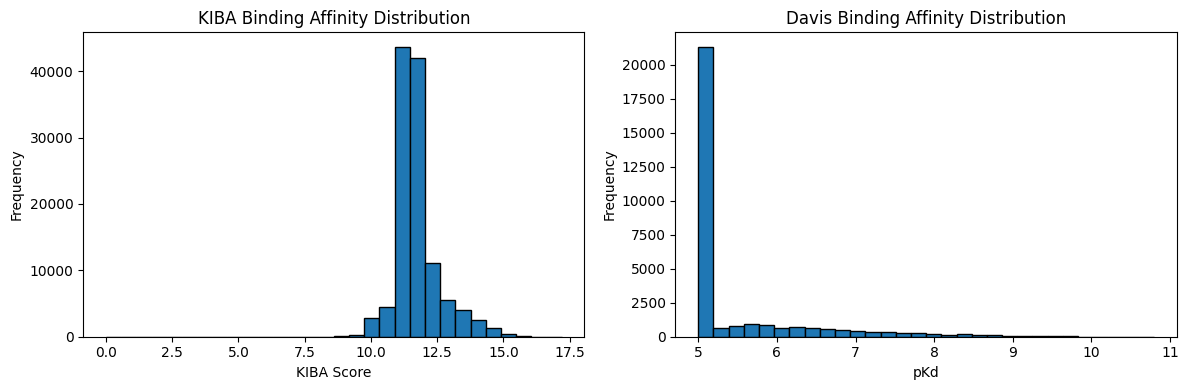

In [79]:
import pandas as pd
import matplotlib.pyplot as plt

# Load datasets
kiba = pd.read_csv(
    "/content/drive/MyDrive/Drug_Target_Project/dashboard/data/kiba_records.csv"
)

davis = pd.read_csv(
    "/content/drive/MyDrive/Drug_Target_Project/dashboard/data/davis_records.csv"
)

# Create histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(kiba["Binding Affinity"], bins=30, edgecolor="black")
axes[0].set_title("KIBA Binding Affinity Distribution")
axes[0].set_xlabel("KIBA Score")
axes[0].set_ylabel("Frequency")

axes[1].hist(davis["Binding Affinity"], bins=30, edgecolor="black")
axes[1].set_title("Davis Binding Affinity Distribution")
axes[1].set_xlabel("pKd")
axes[1].set_ylabel("Frequency")

plt.tight_layout()

# Save figure
plt.savefig("Figure_9_1_Affinity_Distribution.png", dpi=300)
plt.show()

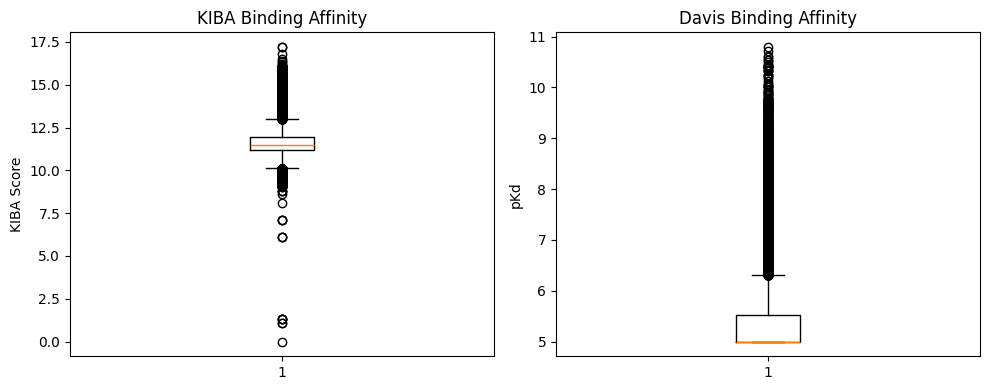

In [80]:
import pandas as pd
import matplotlib.pyplot as plt

# Load datasets
kiba = pd.read_csv(
    "/content/drive/MyDrive/Drug_Target_Project/dashboard/data/kiba_records.csv"
)

davis = pd.read_csv(
    "/content/drive/MyDrive/Drug_Target_Project/dashboard/data/davis_records.csv"
)

# Create box plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].boxplot(kiba["Binding Affinity"].dropna())
axes[0].set_title("KIBA Binding Affinity")
axes[0].set_ylabel("KIBA Score")

axes[1].boxplot(davis["Binding Affinity"].dropna())
axes[1].set_title("Davis Binding Affinity")
axes[1].set_ylabel("pKd")

plt.tight_layout()

# Save figure
plt.savefig("Figure_9_2_Box_Plot.png", dpi=300)
plt.show()

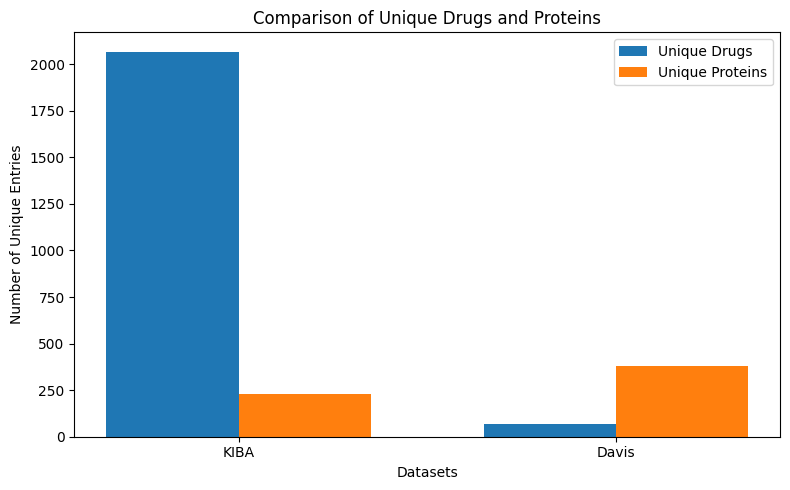

In [81]:
import matplotlib.pyplot as plt
import numpy as np

# Dataset values
datasets = ["KIBA", "Davis"]
unique_drugs = [2068, 68]
unique_proteins = [229, 379]

x = np.arange(len(datasets))
width = 0.35

# Create grouped bar chart
plt.figure(figsize=(8, 5))

plt.bar(x - width/2, unique_drugs, width, label="Unique Drugs")
plt.bar(x + width/2, unique_proteins, width, label="Unique Proteins")

plt.xlabel("Datasets")
plt.ylabel("Number of Unique Entries")
plt.title("Comparison of Unique Drugs and Proteins")
plt.xticks(x, datasets)
plt.legend()

plt.tight_layout()

# Save figure
plt.savefig("Figure_9_3_Unique_Drugs_Proteins.png", dpi=300)
plt.show()

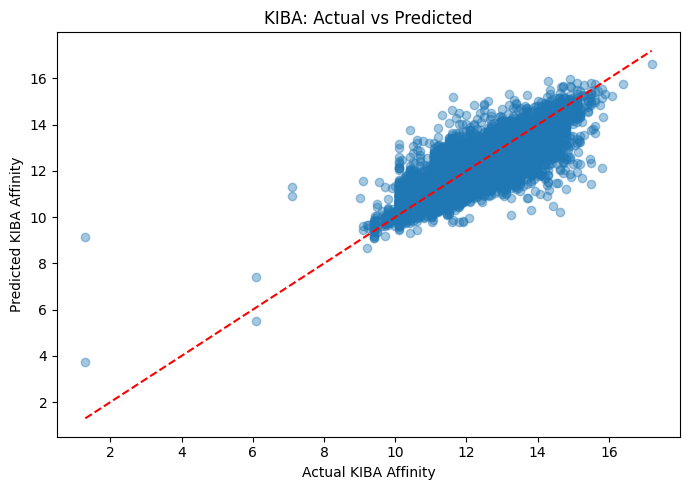

In [82]:
import pandas as pd
import matplotlib.pyplot as plt

path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results/kiba_test_predictions.csv"
df = pd.read_csv(path)

plt.figure(figsize=(7, 5))
plt.scatter(df["Actual"], df["Predicted"], alpha=0.4)
plt.plot(
    [df["Actual"].min(), df["Actual"].max()],
    [df["Actual"].min(), df["Actual"].max()],
    'r--'
)
plt.xlabel("Actual KIBA Affinity")
plt.ylabel("Predicted KIBA Affinity")
plt.title("KIBA: Actual vs Predicted")
plt.tight_layout()
plt.savefig("Figure_12_1_KIBA.png", dpi=300)
plt.show()

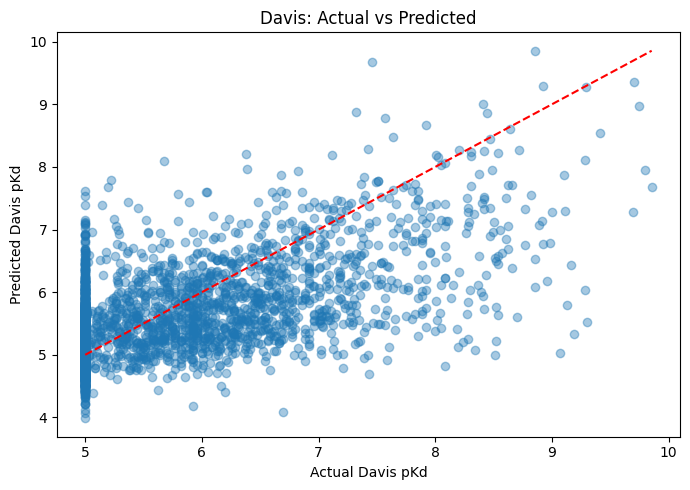

In [83]:
path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results/davis_test_predictions.csv"
df = pd.read_csv(path)

plt.figure(figsize=(7, 5))
plt.scatter(df["Actual"], df["Predicted"], alpha=0.4)
plt.plot(
    [df["Actual"].min(), df["Actual"].max()],
    [df["Actual"].min(), df["Actual"].max()],
    'r--'
)
plt.xlabel("Actual Davis pKd")
plt.ylabel("Predicted Davis pKd")
plt.title("Davis: Actual vs Predicted")
plt.tight_layout()
plt.savefig("Figure_12_2_Davis.png", dpi=300)
plt.show()

In [1]:
!ps aux | grep streamlit

root        1322  0.0  0.0   7344  3624 ?        S    23:22   0:00 /bin/bash -c ps aux | grep streamlit
root        1324  0.0  0.0   6548  2368 ?        S    23:22   0:00 grep streamlit


In [2]:
import os

app_path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

print("App exists:", os.path.exists(app_path))

App exists: False


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os

path = "/content/drive/MyDrive"

print(os.listdir(path))

['IMG_0854.jpeg', 'Classroom', 'Quiz1 (1).gdoc', 'Quiz1.gdoc', 'Saved from Chrome (1)', 'course-materials', 'PPT template.gslides', 'English ppt final.pdf', 'Collaborative_Array_Manipulation_II_Worksheet.gdoc', 'Copy of Collaborative_Array_Manipulation_II_Worksheet.gdoc', '97c06945-46cc-41c6-b2b3-71885782fc8f_251105_232803\n\n.txt', '97c06945-46cc-41c6-b2b3-71885782fc8f_251105_232803.pdf', 'iLovePDF', 'RVUN25CSE066 es exp 10.pdf', 'Sec_B_Team_number4_066.pdf', 'Web.gdoc', 'Department-of-SOCSE-CS-1929-Structured-Innovation-with-Design-Thinking.pptx_20260113_100919_0000.pdf', 'Bhanvi V.pdf', 'Characters.pdf', 'Team 13 PPT.pdf', 'Unit-1.pptx.pdf', 'Saved from Chrome', 'mobilepresent (2)', 'mobilepresent (1)', 'IMG_3428.webp', 'dokumen.pub_introduction-to-linear-algebra-fifth-edition-5nbsped-0980232775-9780980232776.pdf', '1RUA25CSE0113_BHANVI V_SEC-B_Q1 (1).dft', '1RUA25CSE0113_BHANVI V_SEC-B_Q1.dft', '1RUA25CSE0113_BHANVI V_SEC-B_Q2 (1).dft', '1RUA25CSE0113_BHANVI V_SEC-B_Q2.dft', 'mobil

In [5]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "app.py" in files:
        print("Found app.py:", os.path.join(root, "app.py"))

Found app.py: /content/drive/MyDrive/Drug_Target_Project/dashboard/app.py


In [6]:
!streamlit run /content/drive/MyDrive/Drug_Target_Project/dashboard/app.py --server.port 8501 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false > /content/streamlit.log 2>&1 &

In [7]:
!sleep 5
!cat /content/streamlit.log

/bin/bash: line 1: streamlit: command not found


In [8]:
!pip install streamlit -q

In [9]:
!streamlit --version

Streamlit, version 1.67.0


In [10]:
!streamlit run /content/drive/MyDrive/Drug_Target_Project/dashboard/app.py --server.port 8501 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false > /content/streamlit.log 2>&1 &

In [11]:
!sleep 5
!cat /content/streamlit.log



2026-11-10 23:26:45.116 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.107.239.78:8501



In [12]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [13]:
from google.colab import output

url = output.eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-use4a4-1cj61bw8a33mt-a.us-east4.prod.r.colab.dev


In [14]:
!pip install rdkit -q

In [15]:
from rdkit import Chem

print("RDKit installed successfully!")

RDKit installed successfully!


In [16]:
requirements = """
streamlit
rdkit
pandas
numpy
scikit-learn
joblib
matplotlib
seaborn
"""

path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/requirements.txt"

with open(path, "w") as f:
    f.write(requirements.strip())

print("Requirements saved successfully!")

Requirements saved successfully!


In [17]:
from google.colab import drive

drive.mount('/content/drive')

!pip install -q -r /content/drive/MyDrive/Drug_Target_Project/dashboard/requirements.txt

!streamlit run /content/drive/MyDrive/Drug_Target_Project/dashboard/app.py --server.port 8501 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false > /content/streamlit.log 2>&1 &

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
from google.colab import output

url = output.eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-use4a4-1cj61bw8a33mt-a.us-east4.prod.r.colab.dev


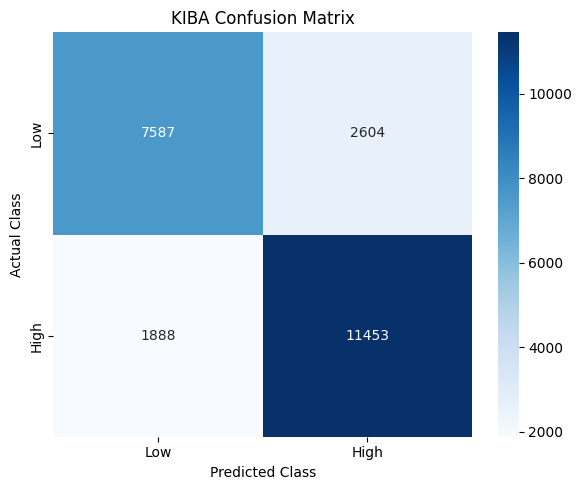

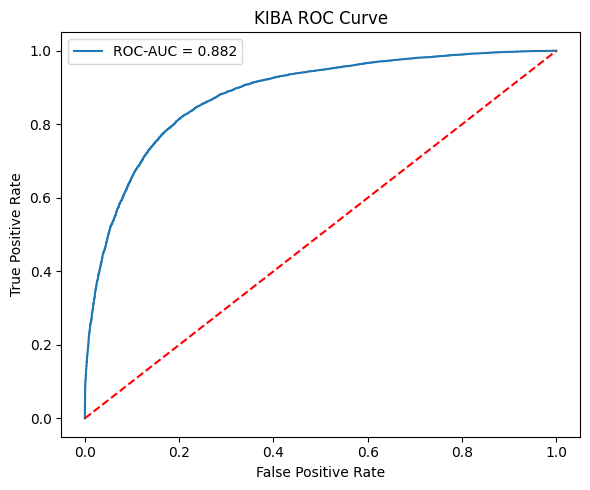

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


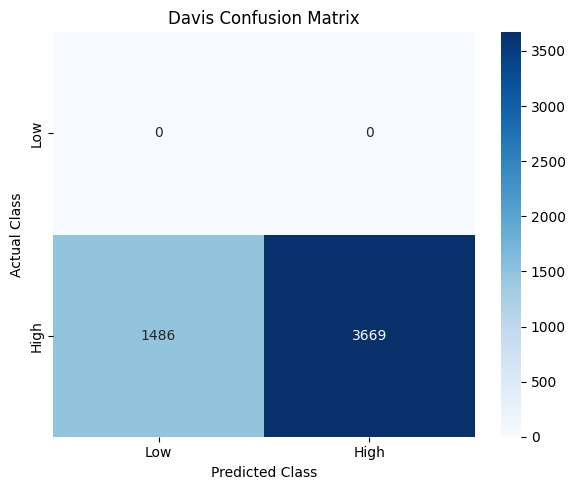

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1179: UndefinedMetricWarning: No negative samples in y_true, false positive value should be meaningless
  warnings.warn(


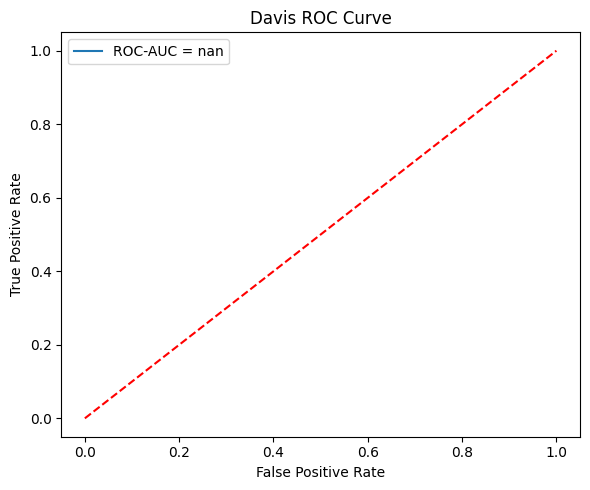

CLASSIFICATION RESULTS


,Dataset,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,KIBA,0.8091,0.8148,0.8585,0.8360,0.8818
1,Davis,0.7117,1.0000,0.7117,0.8316,NaN


In [19]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

# File paths
base = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results"

datasets = {
    "KIBA": {
        "file": f"{base}/kiba_test_predictions.csv",
        "threshold": 11.5
    },
    "Davis": {
        "file": f"{base}/davis_test_predictions.csv",
        "threshold": 5.0
    }
}

results = []

for name, config in datasets.items():

    df = pd.read_csv(config["file"])

    # Convert actual and predicted affinity into binary classes
    actual = (df["Actual"] >= config["threshold"]).astype(int)
    predicted = (df["Predicted"] >= config["threshold"]).astype(int)

    # Classification metrics
    accuracy = accuracy_score(actual, predicted)
    precision = precision_score(actual, predicted, zero_division=0)
    recall = recall_score(actual, predicted, zero_division=0)
    f1 = f1_score(actual, predicted, zero_division=0)
    auc = roc_auc_score(actual, df["Predicted"])

    results.append({
        "Dataset": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    # Confusion matrix
    cm = confusion_matrix(actual, predicted)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Low", "High"],
        yticklabels=["Low", "High"]
    )
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.title(f"{name} Confusion Matrix")
    plt.tight_layout()

    plt.savefig(
        f"{base}/{name.lower()}_confusion_matrix.png",
        dpi=300
    )
    plt.show()

    # ROC curve
    fpr, tpr, _ = roc_curve(actual, df["Predicted"])

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
    plt.plot([0, 1], [0, 1], "r--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} ROC Curve")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"{base}/{name.lower()}_roc_curve.png",
        dpi=300
    )
    plt.show()

# Save classification results
results_df = pd.DataFrame(results)

results_df.to_csv(
    f"{base}/classification_metrics.csv",
    index=False
)

print("CLASSIFICATION RESULTS")
display(results_df.round(4))


In [20]:
import os

base = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results"

for file in os.listdir(base):
    if "confusion_matrix" in file or "roc_curve" in file or "classification_metrics" in file:
        print(file)

kiba_confusion_matrix.png
kiba_roc_curve.png
davis_confusion_matrix.png
davis_roc_curve.png
classification_metrics.csv


In [21]:
import pandas as pd

display(pd.read_csv(
    "/content/drive/MyDrive/Drug_Target_Project/dashboard/results/classification_metrics.csv"
))

,Dataset,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,KIBA,0.809111,0.814754,0.858481,0.836046,0.881773
1,Davis,0.711736,1.000000,0.711736,0.831596,NaN


In [22]:

import pandas as pd

path = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results/davis_test_predictions.csv"

df = pd.read_csv(path)

threshold = 7.0

actual = (df["Actual"] >= threshold).astype(int)

print("Davis actual class distribution:")
print(actual.value_counts().rename({
    0: "Low affinity",
    1: "High affinity"
}))

print("\nThreshold:", threshold)


Davis actual class distribution:
Actual
Low affinity     4807
High affinity     348
Name: count, dtype: int64

Threshold: 7.0


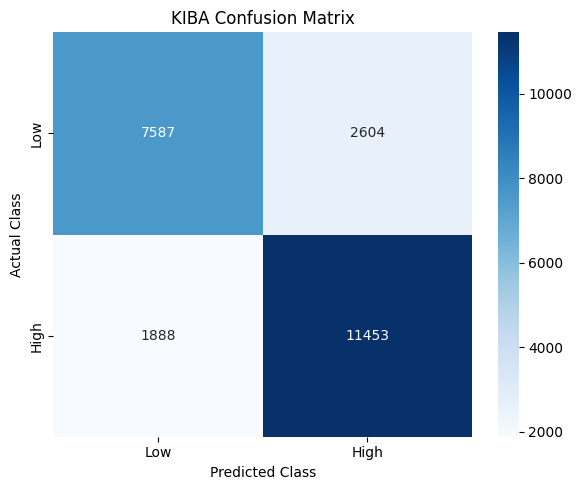

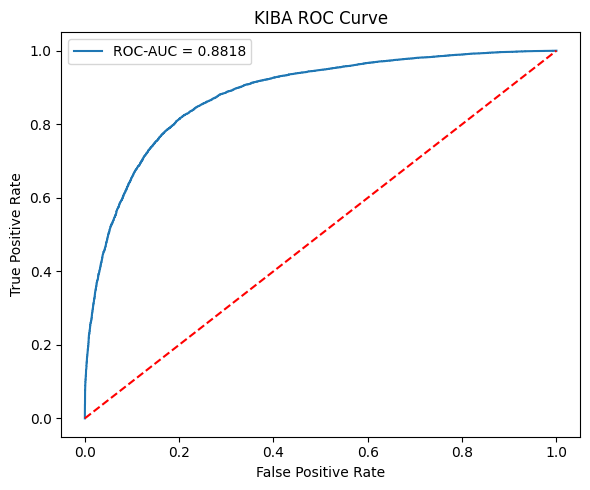

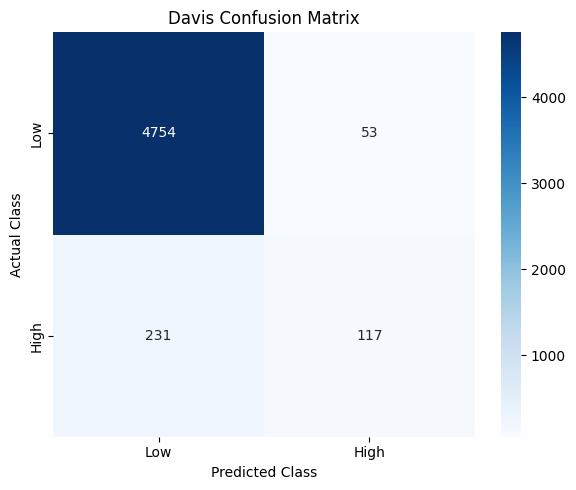

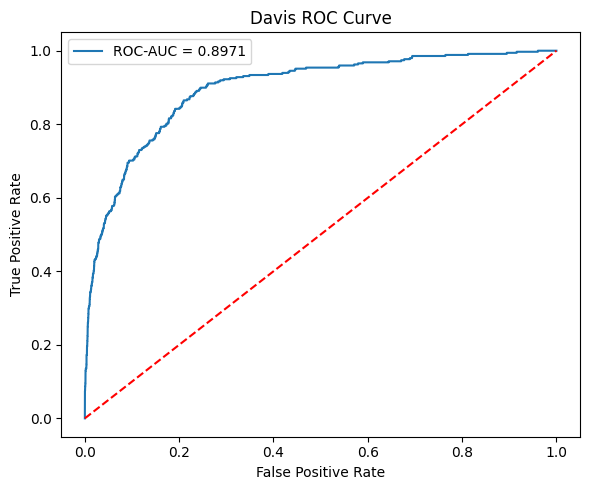

FINAL CLASSIFICATION RESULTS


,Dataset,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,KIBA,11.5,0.8091,0.8148,0.8585,0.8360,0.8818
1,Davis,7.0,0.9449,0.6882,0.3362,0.4517,0.8971


In [23]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve
)

base = "/content/drive/MyDrive/Drug_Target_Project/dashboard/results"

datasets = {
    "KIBA": (f"{base}/kiba_test_predictions.csv", 11.5),
    "Davis": (f"{base}/davis_test_predictions.csv", 7.0)
}

results = []

for name, (path, threshold) in datasets.items():

    df = pd.read_csv(path)

    actual = (df["Actual"] >= threshold).astype(int)
    predicted = (df["Predicted"] >= threshold).astype(int)

    auc = roc_auc_score(actual, df["Predicted"])

    results.append({
        "Dataset": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1-Score": f1_score(actual, predicted, zero_division=0),
        "ROC-AUC": auc
    })

    # Confusion matrix
    cm = confusion_matrix(actual, predicted)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Low", "High"],
        yticklabels=["Low", "High"]
    )
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.savefig(f"{base}/{name.lower()}_confusion_matrix.png", dpi=300)
    plt.show()

    # ROC curve
    fpr, tpr, _ = roc_curve(actual, df["Predicted"])

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], "r--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{base}/{name.lower()}_roc_curve.png", dpi=300)
    plt.show()

# Save final results
results_df = pd.DataFrame(results)
results_df.to_csv(f"{base}/classification_metrics.csv", index=False)

print("FINAL CLASSIFICATION RESULTS")
display(results_df.round(4))


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q -r /content/drive/MyDrive/Drug_Target_Project/dashboard/requirements.txt

In [3]:
!streamlit run /content/drive/MyDrive/Drug_Target_Project/dashboard/app.py --server.port 8501 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false



2026-11-11 07:21:55.498 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.67.164.138:8501

  Stopping...
  Stopping...


In [5]:
!curl -I http://localhost:8501

curl: (7) Failed to connect to localhost port 8501 after 0 ms: Couldn't connect to server


In [6]:
!ps aux | grep streamlit

root        2348  0.0  0.0   7344  3480 ?        S    07:26   0:00 /bin/bash -c ps aux | grep streamlit
root        2350  0.0  0.0   6548  2352 ?        S    07:26   0:00 grep streamlit


In [7]:
!pkill -f streamlit

In [10]:
import os
import time
import subprocess
import requests

APP = "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py"

# Check app location
if not os.path.exists(APP):
    print("ERROR: App file not found!")
    print("Check your Google Drive folder path.")
else:
    print("App file found!")

    # Stop old Streamlit processes
    subprocess.run(
        ["pkill", "-f", "streamlit run"],
        capture_output=True
    )

    # Start Streamlit and save logs
    log = open("/content/streamlit.log", "w")

    process = subprocess.Popen(
        [
            "streamlit", "run", APP,
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

    time.sleep(10)

    # Check server
    try:
        response = requests.get(
            "http://127.0.0.1:8501",
            timeout=5
        )
        print("SUCCESS! Streamlit is running.")
        print("Status:", response.status_code)
    except Exception as e:
        print("Streamlit is not responding.")
        print("Error:", e)

    print("\nSERVER LOGS:")
    print(open("/content/streamlit.log").read()[-5000:])

App file found!
SUCCESS! Streamlit is running.
Status: 200

SERVER LOGS:


2026-11-11 07:29:53.281 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.67.164.138:8501




In [11]:
from google.colab import output

url = output.eval_js("google.colab.kernel.proxyPort(8501)")
print("OPEN YOUR DRUGTARGET AI DASHBOARD:")
print(url)

OPEN YOUR DRUGTARGET AI DASHBOARD:
https://8501-m-s-usc1c10-3gpp1jdcri6v0-c.us-central1.prod.r.colab.dev


In [12]:
print(open("/content/streamlit.log").read()[-10000:])



2026-11-11 07:29:53.281 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.67.164.138:8501

2026-11-11 07:30:39.726 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usc1c10-3gpp1jdcri6v0-c.us-central1.prod.r.colab.dev, host=m-s-usc1c10-3gpp1jdcri6v0.us-central1-c.c.codatalab-user-runtimes.internal:8007
2026-11-11 07:30:42.128 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usc1c10-3gpp1jdcri6v0-c.us-central1.prod.r.colab.dev, host=m-s-usc1c10-3gpp1jdcri6v0.us-central1-c.c.codatalab-user-runtimes.internal:8007
2026-11-11 07:30:43.836 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usc1c10-3gpp1jdcri6v0-c.us-central1.prod.r.colab.dev, host=m-s-usc1c10-3gpp1jdcri6v0.us-central1-c.c.codatalab-user-runtimes.inte

In [13]:
import subprocess
import time
import requests

# Stop existing Streamlit processes safely
import psutil

for p in psutil.process_iter(["pid", "cmdline"]):
    try:
        cmd = p.info["cmdline"] or []
        if any("streamlit" in x for x in cmd) and any("app.py" in x for x in cmd):
            p.terminate()
    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass

time.sleep(3)

# Start Streamlit with Colab-compatible settings
log = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run",
        "/content/drive/MyDrive/Drug_Target_Project/dashboard/app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(8)

print("Server status:", requests.get(
    "http://127.0.0.1:8501",
    timeout=10
).status_code)

print("Dashboard server restarted!")

Server status: 200
Dashboard server restarted!


In [14]:
from google.colab import output

url = output.eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-usc1c10-3gpp1jdcri6v0-c.us-central1.prod.r.colab.dev
